# Predicción del abandono de clientes

Usamos el conjunto Iranian Churn para predecir si un cliente de telecomunicaciones abandona el servicio. La variable objetivo es abandono: 1 si abandonó y 0 si permaneció.

El cuaderno sigue las etapas de un proyecto de analítica, del entendimiento del negocio al despliegue. Cada herramienta se importa y se explica en la etapa donde se usa.

En esta versión la métrica que optimizamos es el Recall del abandono, con un piso de precisión para que no gane un modelo que alerta a todos. Primero ajustamos los hiperparámetros de los doce modelos con los datos en crudo y después probamos, sobre cada modelo ya ajustado, la selección de variables, el PCA y SHAP, para quedarnos con el mejor de todas las combinaciones.

<a id="indice"></a>
## Índice

1. [Entendimiento del negocio](#seccion-1)
2. [Enfoque analítico](#seccion-2)
3. [Requerimiento de datos](#seccion-3)
4. [Recolección de los datos](#seccion-4)
5. [Separación de entrenamiento y prueba](#seccion-5)
6. [Entendimiento de los datos](#seccion-6)
7. [Preparación de los datos](#seccion-7)
8. [Modelado](#seccion-8)
9. [Ajuste de hiperparámetros](#seccion-9)
10. [Selección de variables, PCA y SHAP](#seccion-10)
11. [Selección del umbral](#seccion-11)
12. [Evaluación final](#seccion-12)
13. [Despliegue y conclusiones](#seccion-13)

<a id="seccion-1"></a>
## 1. Entendimiento del negocio

Una empresa de telecomunicaciones en Irán pierde clientes que se van a la competencia. Conseguir un cliente nuevo cuesta bastante más que retener a uno que ya se tiene, así que a la empresa le interesa saber quién está a punto de irse para contactarlo antes.

El equipo de retención no puede llamar a todos los clientes: tiene capacidad para atender a unos pocos cada mes. Lo que necesita es una lista corta de clientes en riesgo, ordenada por prioridad.

Los falsos positivos y negativos afectan distinto. Dejar escapar a un cliente que sí se iba significa perderlo; llamar a uno que no pensaba irse solo gasta una llamada. Por eso nos importa más no dejar escapar clientes que acertar en todas las llamadas.

[Volver al índice](#indice)

<a id="seccion-2"></a>
## 2. Enfoque analítico

El problema se plantea como una clasificación binaria: para cada cliente predecimos si abandona (1) o permanece (0).

La métrica principal es el Recall de la clase abandono: de los clientes que de verdad se van, cuántos alcanzamos a detectar. Es lo que más nos importa, porque un cliente que se va y no detectamos es un cliente perdido. Pero el Recall solo se puede engañar: un modelo que alerte a todos los clientes tiene un Recall de 1,00. Por eso le ponemos un piso a la precisión, que dice cuántas de nuestras alertas eran correctas. Entre las configuraciones con precisión de al menos 0,60 nos quedamos con la de mayor Recall, y el F1 desempata. Miramos también la precisión y el F1 por separado para entender cómo se reparte ese resultado.

No usamos la exactitud para decidir. Como la mayoría de los clientes permanece, un modelo que respondiera siempre permanece acertaría la mayor parte de las veces sin detectar a nadie en riesgo, que es justo lo que necesitamos.

El modelo además debe entregar una probabilidad por cliente, no solo una respuesta de sí o no, para poder ordenar la lista de contactos por prioridad.

[Volver al índice](#indice)

<a id="seccion-3"></a>
## 3. Requerimiento de datos

Para anticipar el abandono necesitamos información de cada cliente anterior al momento en que se va: cuánto usa el servicio, si ha tenido problemas, qué plan tiene y cuánto lleva contratado.

Usamos el conjunto Iranian Churn del repositorio UCI (https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset), que recoge datos reales de una empresa de telecomunicaciones iraní. Las variables de entrada corresponden a los primeros nueve meses y el abandono se registra al terminar el mes doce, así que las entradas son anteriores al desenlace que queremos predecir.

Dos cosas que harían falta y el archivo no trae: un identificador de cliente y las fechas de cada medición. Sin identificador no podemos saber si dos filas iguales son el mismo cliente, y sin fechas no podemos comprobar el orden de los hechos cliente por cliente. Lo tenemos en cuenta al interpretar los resultados.

[Volver al índice](#indice)

<a id="seccion-4"></a>
## 4. Recolección de los datos

Cargamos el archivo original, revisamos qué trae y dejamos los nombres de las columnas en español. El archivo no se modifica en ningún momento.

### 4.1. Ruta de los datos

En local el cuaderno se ejecuta desde la carpeta del proyecto. Para Colab hay que activar EN_COLAB y ajustar la ruta en Drive.

In [1]:
EN_COLAB = False

if EN_COLAB:
    %pip install phik imbalanced-learn shap -q
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_BASE = "/content/drive/MyDrive/churn/"
else:
    RUTA_BASE = "./"

RUTA_DATOS = RUTA_BASE + "data/"
RUTA_RESULTADOS = RUTA_BASE + "resultados/"
ruta_original = RUTA_DATOS + "original/Customer Churn.csv"

### 4.2. Carga del archivo

pandas es la librería con la que trabajamos las tablas, y os nos sirve para crear la carpeta donde guardamos los resultados.

In [2]:
import os
import pandas as pd

os.makedirs(RUTA_RESULTADOS, exist_ok=True)

In [3]:
datos_originales = pd.read_csv(ruta_original)
datos_originales.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


### 4.3. Tamaño de la tabla

In [4]:
print("Filas:", datos_originales.shape[0])
print("Columnas:", datos_originales.shape[1])

Filas: 3150
Columnas: 14


3.150 filas y 14 columnas. Churn es la variable objetivo.

### 4.4. Tipos de datos y valores faltantes

In [5]:
revision_columnas = pd.DataFrame({
    "Tipo": datos_originales.dtypes.astype(str),
    "Valores faltantes": datos_originales.isna().sum()
})
revision_columnas

,Tipo,Valores faltantes
Call Failure,int64,0
Complains,int64,0
Subscription Length,int64,0
Charge Amount,int64,0
Seconds of Use,int64,0
Frequency of use,int64,0
Frequency of SMS,int64,0
Distinct Called Numbers,int64,0
Age Group,int64,0
Tariff Plan,int64,0


No hay valores faltantes. Todas las columnas son numéricas, pero algunas representan categorías que ya fueron codificadas previamente, como las quejas o el plan tarifario.

### 4.5. Filas repetidas

In [6]:
filas_repetidas = datos_originales.duplicated().sum()
print("Filas repetidas:", filas_repetidas)

Filas repetidas: 300


Hay 300 filas repetidas. Las conservamos: sin identificador de cliente no se puede afirmar que sean el mismo cliente registrado dos veces, así que tratamos cada fila como un cliente distinto.

### 4.6. Nombres de las columnas

Trabajamos sobre una copia de la tabla original.

In [7]:
nombres = {
    "Call  Failure": "fallas_llamadas",
    "Complains": "quejas",
    "Subscription  Length": "antiguedad",
    "Charge  Amount": "nivel_cargo",
    "Seconds of Use": "segundos_uso",
    "Frequency of use": "frecuencia_uso",
    "Frequency of SMS": "frecuencia_sms",
    "Distinct Called Numbers": "numeros_distintos",
    "Age Group": "grupo_edad",
    "Tariff Plan": "plan_tarifario",
    "Status": "estado",
    "Age": "edad",
    "Customer Value": "valor_cliente",
    "Churn": "abandono"
}

datos = datos_originales.rename(columns=nombres).copy()

datos.head()

,fallas_llamadas,quejas,antiguedad,nivel_cargo,segundos_uso,frecuencia_uso,frecuencia_sms,numeros_distintos,grupo_edad,plan_tarifario,estado,edad,valor_cliente,abandono
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


### 4.7. Estado y valor del cliente

Conservamos estado y valor_cliente como entradas.

estado vale 1 si el cliente está activo y 2 si no lo está, así que es una categoría. valor_cliente es un valor calculado cuya fórmula UCI no publica, por lo que no lo leemos como dinero. Por esa falta de documentación las revisamos aparte en la sección 6, ya con los datos de entrenamiento separados.

In [8]:
datos[["estado", "valor_cliente"]].head()

,estado,valor_cliente
0,1,197.640
1,2,46.035
2,1,1536.520
3,1,240.020
4,1,145.805


Quedan 3.150 filas con 13 entradas más abandono. No hubo que completar ni eliminar nada.

[Volver al índice](#indice)

<a id="seccion-5"></a>
## 5. Separación de entrenamiento y prueba

Separamos los datos antes de mirarlos a fondo. Si exploráramos la tabla completa, las decisiones que tomemos después estarían influidas por los clientes que después usamos para evaluar, y el resultado final se vería mejor de lo que es.

Dividimos en 80 % para entrenamiento y 20 % para prueba, con partición estratificada para que las dos partes conserven la proporción de abandono y random_state=42 para poder repetirla.

La prueba queda reservada desde aquí: no se usa para explorar, comparar ni ajustar, solo para la evaluación final de la sección 12.

Cada fila es un cliente distinto, porque el archivo no trae identificador, así que repartimos las filas sin agrupar perfiles idénticos.

La función que parte los datos viene de scikit-learn.

In [9]:
from sklearn.model_selection import train_test_split

### 5.1. Variables de entrada y variable objetivo

In [10]:
X = datos.drop(columns="abandono")
y = datos["abandono"]

print("Variables de entrada:", X.shape[1])
print("Filas:", len(X))
print("Permanencias (0):", int((y == 0).sum()))
print("Abandonos (1):", int((y == 1).sum()))
print("Porcentaje de abandono:", round((y == 1).mean() * 100, 2))

Variables de entrada: 13
Filas: 3150
Permanencias (0): 2655
Abandonos (1): 495
Porcentaje de abandono: 15.71


Hay 3.150 filas: 2.655 de permanencia y 495 de abandono, un 15,71 %. Por cada cliente que abandona hay más de cinco que permanecen, y ese desbalance es la razón de acompañar el Recall con un piso de precisión.

### 5.2. Partición 80/20

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Filas de entrenamiento:", len(X_train))
print("Filas de prueba:", len(X_test))

Filas de entrenamiento: 2520
Filas de prueba: 630


2.520 filas de entrenamiento y 630 de prueba.

### 5.3. Verificación de la estratificación

Si la partición quedó bien hecha, los tres porcentajes de abandono deben ser casi iguales.

In [12]:
rows = []

for nombre_conjunto, serie in [("Completo", y), ("Entrenamiento", y_train), ("Prueba", y_test)]:
    rows.append({
        "Conjunto": nombre_conjunto,
        "Filas": len(serie),
        "Permanencia (0)": int((serie == 0).sum()),
        "Abandono (1)": int((serie == 1).sum()),
        "% Abandono": round((serie == 1).mean() * 100, 2)
    })

tabla_particion = pd.DataFrame(rows)
tabla_particion

,Conjunto,Filas,Permanencia (0),Abandono (1),% Abandono
0,Completo,3150,2655,495,15.71
1,Entrenamiento,2520,2124,396,15.71
2,Prueba,630,531,99,15.71


Los tres coinciden en 15,71 %: 396 abandonos en entrenamiento y 99 en prueba.

### 5.4. Tablas de entrenamiento y prueba

Armamos train y test con sus entradas y su columna abandono, y reiniciamos el índice.

In [13]:
train = pd.concat([X_train, y_train], axis=1).reset_index(drop=True)
test = pd.concat([X_test, y_test], axis=1).reset_index(drop=True)

X_train = train.drop(columns="abandono")
y_train = train["abandono"]
X_test = test.drop(columns="abandono")
y_test = test["abandono"]

print("Tabla de entrenamiento:", train.shape)
print("Tabla de prueba:", test.shape)

train.head()

Tabla de entrenamiento: (2520, 14)
Tabla de prueba: (630, 14)


,fallas_llamadas,quejas,antiguedad,nivel_cargo,segundos_uso,frecuencia_uso,frecuencia_sms,numeros_distintos,grupo_edad,plan_tarifario,estado,edad,valor_cliente,abandono
0,0,0,31,0,2420,10,0,8,3,1,1,30,97.200,0
1,15,0,40,1,4503,72,8,37,1,1,1,15,295.625,0
2,22,0,35,8,10840,98,2,40,4,1,1,45,278.450,0
3,0,0,33,0,795,12,0,7,2,1,2,25,36.315,0
4,1,0,34,0,7328,119,373,38,2,1,1,25,2013.615,0


train tiene 2.520 filas y test 630, las dos con 14 columnas. De aquí en adelante trabajamos solo con train, y la prueba no se vuelve a tocar hasta la sección 12.

[Volver al índice](#indice)

<a id="seccion-6"></a>
## 6. Entendimiento de los datos

Con el entrenamiento ya separado, miramos el desbalance, la distribución de cada variable, su asociación con el abandono y si hay variables que repiten la misma información.

matplotlib y seaborn para las gráficas, y phik para medir la asociación entre variables.

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import phik

### 6.1. Resumen de las variables

In [15]:
rows = []

for columna in train.columns:
    serie = train[columna]
    rows.append({
        "Variable": columna,
        "Tipo": str(serie.dtype),
        "Valores distintos": serie.nunique(),
        "Mínimo": serie.min(),
        "Máximo": serie.max(),
        "Promedio": round(serie.mean(), 2)
    })

tabla_variables = pd.DataFrame(rows)
tabla_variables

,Variable,Tipo,Valores distintos,Mínimo,Máximo,Promedio
0,fallas_llamadas,int64,37,0.0,36.00,7.64
1,quejas,int64,2,0.0,1.00,0.08
2,antiguedad,int64,45,3.0,47.00,32.59
3,nivel_cargo,int64,11,0.0,10.00,0.95
4,segundos_uso,int64,1528,0.0,16980.00,4453.48
5,frecuencia_uso,int64,238,0.0,254.00,69.39
6,frecuencia_sms,int64,382,0.0,522.00,73.75
7,numeros_distintos,int64,92,0.0,97.00,23.55
8,grupo_edad,int64,5,1.0,5.00,2.83
9,plan_tarifario,int64,2,1.0,2.00,1.08


La tabla tiene 14 columnas: 13 entradas y abandono. quejas, plan_tarifario y estado toman dos valores, grupo_edad cinco y nivel_cargo once.

edad también toma solo cinco valores (15, 25, 30, 45 y 55), los mismos niveles de grupo_edad. Lo revisamos en 4.7.

### 6.2. Desbalance de la variable objetivo

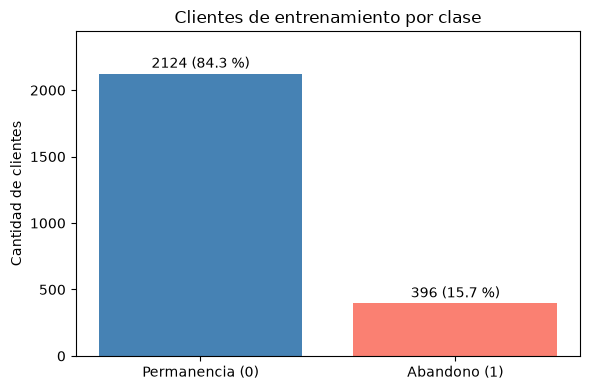

In [16]:
conteo = y_train.value_counts().reindex([0, 1], fill_value=0)
porcentajes = (conteo / len(y_train)) * 100

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["Permanencia (0)", "Abandono (1)"], conteo, color=["steelblue", "salmon"])
ax.set_title("Clientes de entrenamiento por clase")
ax.set_ylabel("Cantidad de clientes")
ax.set_ylim(0, conteo.max() * 1.15)

for barra, porcentaje in zip(barras, porcentajes):
    altura = barra.get_height()
    ax.text(barra.get_x() + barra.get_width() / 2, altura + 20,
            str(int(altura)) + " (" + str(round(porcentaje, 1)) + " %)",
            ha="center", va="bottom")

plt.tight_layout()
plt.show()

2.124 clientes permanecieron y 396 abandonaron, un 15,7 %. Un modelo que respondiera siempre permanece acertaría el 84,3 % de las veces sin detectar a nadie en riesgo, y por eso la exactitud no nos sirve para decidir.

Para ver por qué conviene acompañar el Recall con otra medida, imaginemos un modelo que respondiera siempre que el cliente abandona. Detectaría a todos los que se van.

In [17]:
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score

todos_abandonan = [1] * len(y_train)

pd.DataFrame([{
    "Modelo": "Todos abandonan",
    "Recall": round(recall_score(y_train, todos_abandonan), 4),
    "Precisión": round(precision_score(y_train, todos_abandonan), 4)
}])

,Modelo,Recall,Precisión
0,Todos abandonan,1.0,0.1571


Ese modelo tiene un Recall de 1,00 y una precisión de 0,1571: habría que llamar a los 2.520 clientes de entrenamiento y solo el 15,7 % se iba. No sirve de nada, y es la razón por la que más adelante le ponemos un piso a la precisión.

### 6.3. Variables categóricas

Cinco variables son categorías: quejas, plan_tarifario, estado, nivel_cargo y grupo_edad. Para cada una contamos los clientes y su porcentaje de abandono.

In [18]:
columnas_categoricas = ["quejas", "plan_tarifario", "estado", "nivel_cargo", "grupo_edad"]

rows = []

for columna in columnas_categoricas:
    resumen = train.groupby(columna)["abandono"].agg(["count", "sum"])
    for categoria in resumen.index:
        clientes = int(resumen.loc[categoria, "count"])
        abandonos = int(resumen.loc[categoria, "sum"])
        rows.append({
            "Variable": columna,
            "Categoría": categoria,
            "Clientes": clientes,
            "Abandonos": abandonos,
            "% Abandono": round(abandonos / clientes * 100, 2)
        })

tabla_categoricas = pd.DataFrame(rows)
tabla_categoricas

,Variable,Categoría,Clientes,Abandonos,% Abandono
0,quejas,0,2318,233,10.05
1,quejas,1,202,163,80.69
2,plan_tarifario,1,2323,390,16.79
3,plan_tarifario,2,197,6,3.05
4,estado,1,1896,100,5.27
5,estado,2,624,296,47.44
6,nivel_cargo,0,1397,336,24.05
7,nivel_cargo,1,510,35,6.86
8,nivel_cargo,2,316,17,5.38
9,nivel_cargo,3,162,7,4.32


La misma información en gráficas.

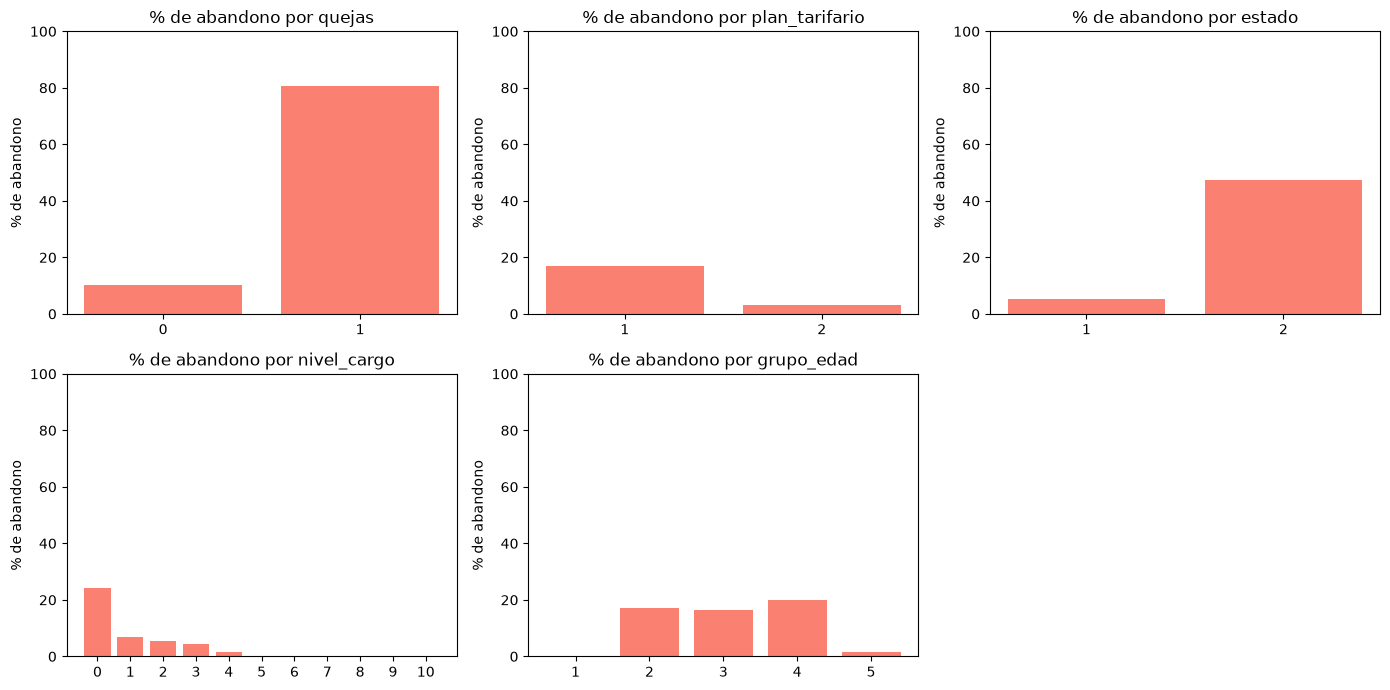

In [19]:
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
ejes = ejes.flatten()

for i, columna in enumerate(columnas_categoricas):
    datos_columna = tabla_categoricas[tabla_categoricas["Variable"] == columna]
    ejes[i].bar(datos_columna["Categoría"].astype(str), datos_columna["% Abandono"], color="salmon")
    ejes[i].set_title("% de abandono por " + columna)
    ejes[i].set_ylabel("% de abandono")
    ejes[i].set_ylim(0, 100)

for i in range(len(columnas_categoricas), len(ejes)):
    ejes[i].axis("off")

plt.tight_layout()
plt.show()

Dos variables separan los grupos con claridad: abandona el 80,69 % de los 202 clientes con queja, frente al 10,05 % del resto, y el 47,44 % de los 624 clientes no activos, frente al 5,27 % de los activos.

Las demás aportan menos. El plan contractual abandona un 3,05 % frente al 16,79 % del prepago. En nivel_cargo el abandono baja al subir el nivel y de 5 en adelante no hay ninguno, pero esos niveles tienen entre 6 y 24 clientes. En grupo_edad los grupos 1 y 5 casi no registran abandono, mientras que 2, 3 y 4 rondan el 17 %.

### 6.4. Variables numéricas

Las ocho restantes son cantidades. Revisamos su resumen y sus histogramas.

In [20]:
columnas_numericas = []

for columna in X_train.columns:
    if columna not in columnas_categoricas:
        columnas_numericas.append(columna)

print("Variables numéricas:", len(columnas_numericas))

train[columnas_numericas].describe().round(2)

Variables numéricas: 8


,fallas_llamadas,antiguedad,segundos_uso,frecuencia_uso,frecuencia_sms,numeros_distintos,edad,valor_cliente
count,2520.00,2520.00,2520.00,2520.00,2520.00,2520.00,2520.00,2520.00
mean,7.64,32.59,4453.48,69.39,73.75,23.55,31.01,472.65
std,7.27,8.57,4183.98,57.45,112.32,17.34,8.85,519.11
min,0.00,3.00,0.00,0.00,0.00,0.00,15.00,0.00
25%,1.00,30.00,1415.00,27.00,6.00,10.00,25.00,113.60
50%,6.00,35.00,2990.00,54.00,21.00,21.00,30.00,228.65
75%,11.00,38.00,6480.00,94.00,91.25,34.00,30.00,796.08
max,36.00,47.00,16980.00,254.00,522.00,97.00,55.00,2165.28


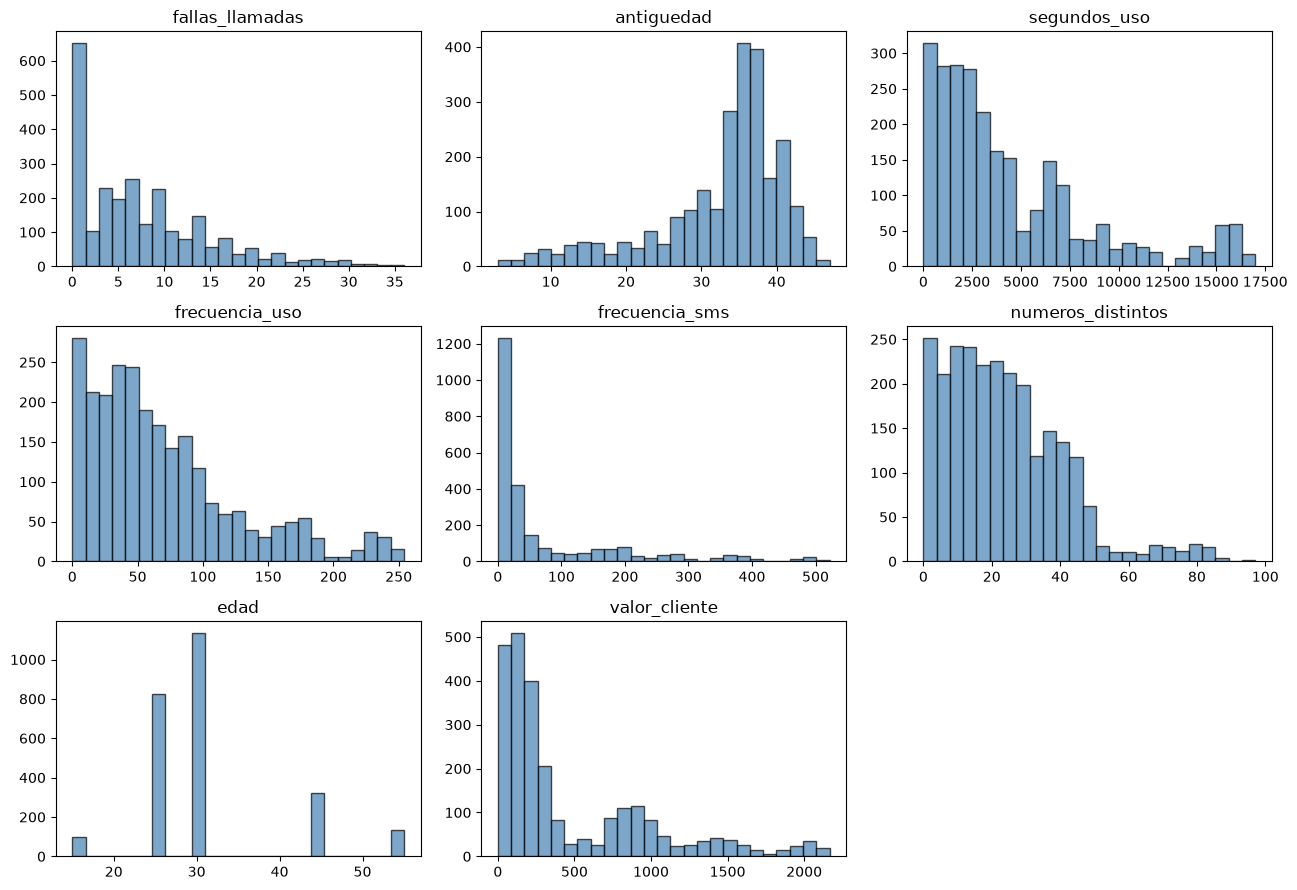

In [21]:
fig, ejes = plt.subplots(3, 3, figsize=(13, 9))
ejes = ejes.flatten()

for i, columna in enumerate(columnas_numericas):
    ejes[i].hist(train[columna], bins=25, color="steelblue", edgecolor="black", alpha=0.7)
    ejes[i].set_title(columna)

for i in range(len(columnas_numericas), len(ejes)):
    ejes[i].axis("off")

plt.tight_layout()
plt.show()

Las ocho tienen la media por encima de la mediana, señal de una cola larga a la derecha: segundos_uso promedia 4.453 con mediana 2.990 y valor_cliente 472,65 con mediana 228,65.

Las escalas son muy distintas entre sí, desde antiguedad entre 3 y 47 hasta segundos_uso que llega a 16.980, así que el escalado importa.

### 6.5. Diferencias entre quienes abandonan y quienes permanecen

Comparamos cada variable numérica entre los dos grupos, con diagramas de caja y con una tabla de medianas.

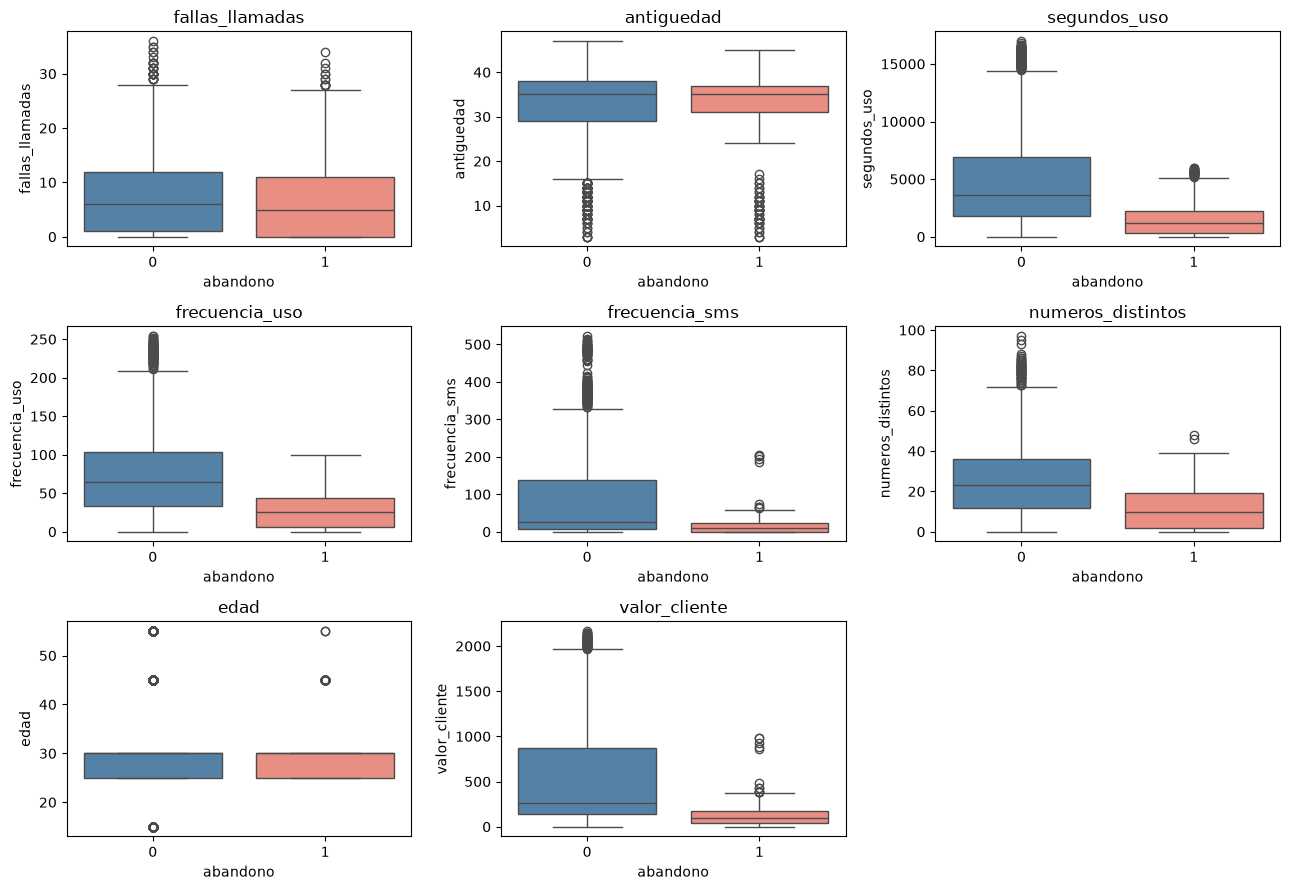

In [22]:
fig, ejes = plt.subplots(3, 3, figsize=(13, 9))
ejes = ejes.flatten()

for i, columna in enumerate(columnas_numericas):
    sns.boxplot(
        data=train, x="abandono", y=columna, hue="abandono",
        palette=["steelblue", "salmon"], legend=False, ax=ejes[i]
    )
    ejes[i].set_title(columna)

for i in range(len(columnas_numericas), len(ejes)):
    ejes[i].axis("off")

plt.tight_layout()
plt.show()

In [23]:
rows = []

for columna in columnas_numericas:
    mediana_permanencia = train.loc[train["abandono"] == 0, columna].median()
    mediana_abandono = train.loc[train["abandono"] == 1, columna].median()
    rows.append({
        "Variable": columna,
        "Mediana permanencia": round(mediana_permanencia, 2),
        "Mediana abandono": round(mediana_abandono, 2),
        "Diferencia": round(mediana_abandono - mediana_permanencia, 2)
    })

tabla_medianas = pd.DataFrame(rows)
tabla_medianas

,Variable,Mediana permanencia,Mediana abandono,Diferencia
0,fallas_llamadas,6.00,5.00,-1.00
1,antiguedad,35.00,35.00,0.00
2,segundos_uso,3594.00,1188.00,-2406.00
3,frecuencia_uso,64.00,25.00,-39.00
4,frecuencia_sms,26.00,9.00,-17.00
5,numeros_distintos,23.00,10.00,-13.00
6,edad,30.00,30.00,0.00
7,valor_cliente,267.94,97.82,-170.12


Quien abandona usa mucho menos el servicio: 1.188 segundos frente a 3.594, 25 llamadas frente a 64, 10 números distintos frente a 23 y un valor_cliente de 97,82 frente a 267,94.

antiguedad y edad tienen la misma mediana en los dos grupos. La señal está en el uso, no en el perfil del cliente.

### 6.6. Asociación de cada variable con el abandono

Usamos phik porque mide la asociación sin exigir que sea lineal y sirve igual para categorías y para cantidades. Va de 0 a 1.

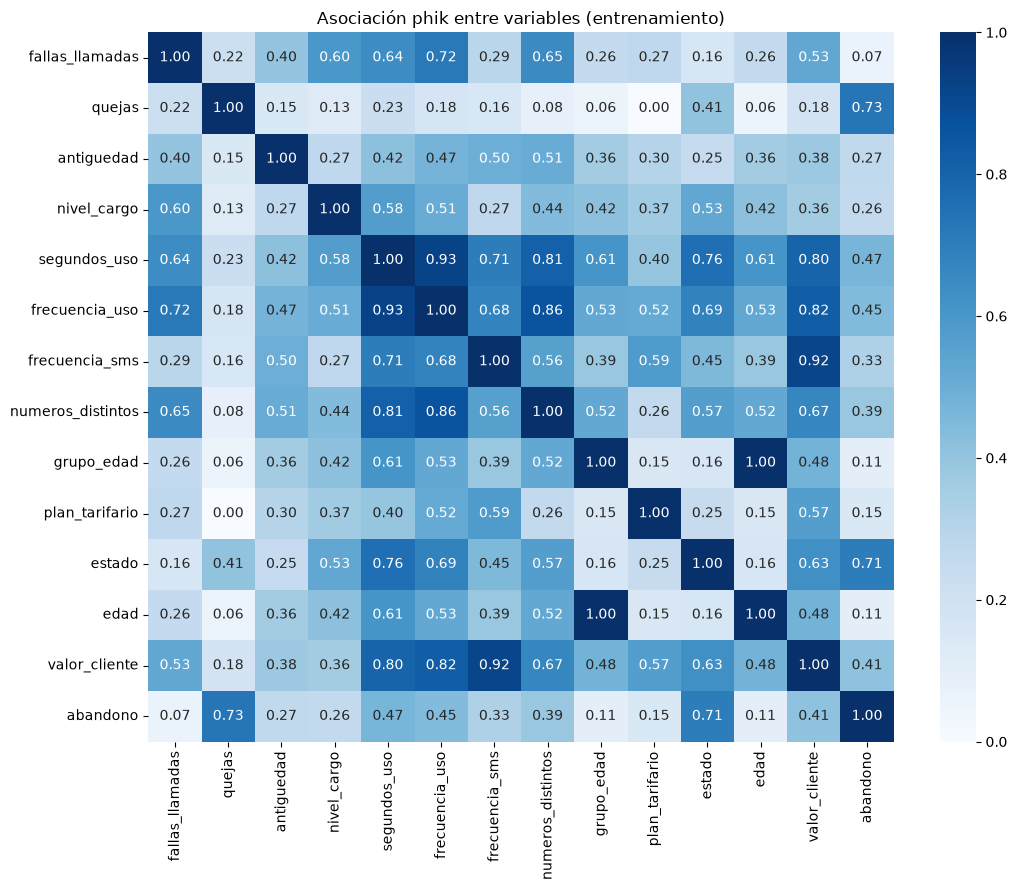

In [24]:
matriz_phik = train.phik_matrix(interval_cols=columnas_numericas, njobs=1)

plt.figure(figsize=(11, 9))
sns.heatmap(matriz_phik, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Asociación phik entre variables (entrenamiento)")
plt.tight_layout()
plt.show()

In [25]:
asociacion_abandono = matriz_phik["abandono"].drop("abandono").sort_values(ascending=False)

tabla_asociacion = asociacion_abandono.round(3).reset_index()
tabla_asociacion.columns = ["Variable", "phik con abandono"]
tabla_asociacion

,Variable,phik con abandono
0,quejas,0.734
1,estado,0.705
2,segundos_uso,0.469
3,frecuencia_uso,0.445
4,valor_cliente,0.413
5,numeros_distintos,0.389
6,frecuencia_sms,0.325
7,antiguedad,0.267
8,nivel_cargo,0.262
9,plan_tarifario,0.152


Encabezan quejas con 0,734 y estado con 0,705, seguidas por el bloque de uso: segundos_uso 0,469, frecuencia_uso 0,445, valor_cliente 0,413, numeros_distintos 0,389 y frecuencia_sms 0,325.

Al final quedan plan_tarifario 0,152, grupo_edad y edad 0,105, y fallas_llamadas 0,066.

### 6.7. Variables que repiten información

Buscamos parejas de entradas con phik de 0,60 o más: si dos variables dicen lo mismo, el modelo no gana nada con las dos.

In [26]:
entradas_phik = matriz_phik.drop(index="abandono", columns="abandono")

rows = []

for i in range(len(entradas_phik.columns)):
    for j in range(i + 1, len(entradas_phik.columns)):
        valor = entradas_phik.iloc[i, j]
        if valor >= 0.60:
            rows.append({
                "Variable A": entradas_phik.columns[i],
                "Variable B": entradas_phik.columns[j],
                "phik": round(valor, 3)
            })

tabla_redundancia = pd.DataFrame(rows)

if len(tabla_redundancia) > 0:
    tabla_redundancia = tabla_redundancia.sort_values("phik", ascending=False)

tabla_redundancia

,Variable A,Variable B,phik
17,grupo_edad,edad,1.000
4,segundos_uso,frecuencia_uso,0.928
15,frecuencia_sms,valor_cliente,0.918
12,frecuencia_uso,numeros_distintos,0.865
14,frecuencia_uso,valor_cliente,0.821
6,segundos_uso,numeros_distintos,0.812
10,segundos_uso,valor_cliente,0.798
8,segundos_uso,estado,0.755
2,fallas_llamadas,frecuencia_uso,0.720
5,segundos_uso,frecuencia_sms,0.706


Revisamos aparte la relación entre edad y grupo_edad.

In [27]:
relacion_edades = train[["edad", "grupo_edad"]].drop_duplicates().sort_values("edad")

print("Grupos distintos por edad:", train.groupby("edad")["grupo_edad"].nunique().max())
print("Edades distintas por grupo:", train.groupby("grupo_edad")["edad"].nunique().max())

relacion_edades

Grupos distintos por edad: 1
Edades distintas por grupo: 1


,edad,grupo_edad
1,15,1
3,25,2
0,30,3
2,45,4
18,55,5


Hay 19 parejas con phik de 0,60 o más. El caso extremo es edad y grupo_edad, con phik de 1,000: cada edad pertenece a un solo grupo y cada grupo tiene una sola edad (15 a 1, 25 a 2, 30 a 3, 45 a 4 y 55 a 5), así que son la misma variable escrita de dos maneras.

Las variables de uso también se solapan: segundos_uso con frecuencia_uso 0,928, frecuencia_sms con valor_cliente 0,918 y frecuencia_uso con numeros_distintos 0,865. Cada una mide algo distinto, así que se quedan.

### 6.8. Quitamos edad

Conservar las dos no aporta nada y sí estorba: en los modelos de distancia la edad contaría doble, en los árboles su importancia se repartiría entre las dos copias y en la selección ocuparían dos puestos para decir lo mismo.

Quitamos edad y conservamos grupo_edad, que es la forma documentada por UCI. No se pierde información, porque cada grupo corresponde a una sola edad.

In [28]:
train = train.drop(columns="edad")
test = test.drop(columns="edad")

X_train = train.drop(columns="abandono")
y_train = train["abandono"]
X_test = test.drop(columns="abandono")
y_test = test["abandono"]

columnas_numericas.remove("edad")

print("Variables de entrada:", X_train.shape[1])
print("Entrenamiento:", train.shape, "| Prueba:", test.shape)

list(X_train.columns)

Variables de entrada: 12
Entrenamiento: (2520, 13) | Prueba: (630, 13)


['fallas_llamadas',
 'quejas',
 'antiguedad',
 'nivel_cargo',
 'segundos_uso',
 'frecuencia_uso',
 'frecuencia_sms',
 'numeros_distintos',
 'grupo_edad',
 'plan_tarifario',
 'estado',
 'valor_cliente']

### 6.9. Estado y valor del cliente

Estas dos entradas merecen una revisión aparte. De estado no sabemos qué cuenta como activo, y de valor_cliente no conocemos la fórmula, así que conviene comprobar que aportan algo y que ese algo no viene de otra variable.

De estado queremos saber si dice algo por su cuenta o si solo repite lo que ya dicen las quejas, que son la señal más fuerte. Lo miramos entre los clientes que no pusieron ninguna queja.

In [29]:
sin_quejas = train[train["quejas"] == 0]

rows = []

for valor in [1, 2]:
    grupo = sin_quejas[sin_quejas["estado"] == valor]
    rows.append({
        "estado": valor,
        "Clientes": len(grupo),
        "Abandonos": int(grupo["abandono"].sum()),
        "% Abandono": round(grupo["abandono"].mean() * 100, 2)
    })

tabla_estado = pd.DataFrame(rows)
tabla_estado

,estado,Clientes,Abandonos,% Abandono
0,1,1824,50,2.74
1,2,494,183,37.04


Entre los 2.318 clientes que no pusieron ninguna queja abandona el 37,04 % de los 494 no activos y el 2,74 % de los 1.824 activos: trece veces más. Estado separa por su cuenta, sin apoyarse en las quejas, y concentra 183 de los 233 abandonos de ese grupo en uno de cada cinco clientes.

De valor_cliente queremos saber si trae información nueva. Si las demás entradas lo reconstruyen, es una combinación de ellas y no una medición aparte. Lo medimos con una regresión que intenta reproducirlo a partir de las otras once.

In [30]:
from sklearn.linear_model import LinearRegression

entradas_sin_valor = []

for columna in X_train.columns:
    if columna != "valor_cliente":
        entradas_sin_valor.append(columna)

reconstruccion = LinearRegression()
reconstruccion.fit(train[entradas_sin_valor], train["valor_cliente"])

print("R2 de valor_cliente a partir de las demás entradas:",
      round(reconstruccion.score(train[entradas_sin_valor], train["valor_cliente"]), 4))

R2 de valor_cliente a partir de las demás entradas: 0.9807


Las demás entradas explican el 98 % de la variación de valor_cliente, así que es una combinación de ellas.

Las dos se conservan.

Quedan 12 entradas más abandono. Quitamos la columna también de test para que los dos conjuntos tengan las mismas variables. Es la única variable que eliminamos.

Las señales más fuertes son las quejas y el estado del cliente, seguidas por el uso: quien abandona consume cerca de un tercio. Las distribuciones están sesgadas a la derecha y en escalas muy distintas, que es lo que atiende la preparación de la sección siguiente.

[Volver al índice](#indice)

<a id="seccion-7"></a>
## 7. Preparación de los datos

La preparación es lo que ocurre entre los datos y el modelo: escalar las variables y decidir cómo tratar el desbalance. Aquí decidimos qué opciones probar; las aplicamos en las secciones siguientes.

El orden de trabajo es este. Primero ajustamos los hiperparámetros de los doce modelos con las doce variables, sin quitar ninguna ni resumirlas, y nos quedamos con la mejor versión de cada uno. Después, con esas versiones, probamos la selección de variables, el PCA y SHAP en todas las combinaciones. Por eso aquí no decidimos nada sobre quitar variables.

Nada se aplica sobre la tabla completa. Cada paso se ajusta con la parte de entrenamiento de cada partición y después se aplica a la parte que se evalúa, como en el cuaderno de normalización de clase.

### 7.1. Escalado

Las variables están en escalas muy distintas, desde antiguedad entre 3 y 47 hasta segundos_uso que llega a 16.980, y sus distribuciones están sesgadas.

Los modelos que miden distancias, como KNN o SVM, comparan las variables entre sí, así que sin escalar quedarían dominados por segundos_uso y valor_cliente. A los árboles no les afecta, porque cortan cada variable por separado.

MinMaxScaler lleva cada variable al rango de 0 a 1. Conserva la forma de la distribución y deja los ceros en cero, que aquí significan algo: un cliente sin uso. StandardScaler centra en la media y divide por la desviación, lo que encaja mejor con distribuciones simétricas; con colas tan largas como estas, la media queda lejos de donde está la mayoría de los clientes.

No sabemos de antemano cuál le conviene a cada modelo, así que la búsqueda de la sección 9 prueba los dos y se queda con el mejor. El escalador se ajusta con el entrenamiento y se aplica a los dos conjuntos, nunca al revés. En la comparación de modelos eso se repite dentro de cada partición.

### 7.2. El desbalance

Solo el 15,7 % de los clientes abandona, así que un modelo puede acertar mucho ignorando por completo a la minoría. Hay cuatro formas de tratarlo.

Sin balanceo deja los datos como están y sirve de punto de comparación. Peso por clase le dice al modelo que equivoque menos a la minoría, y solo lo admiten algunos. SMOTENC crea clientes sintéticos de la clase minoritaria, buscando vecinos más cercanos y combinando los que ya existen, respetando que quejas, plan_tarifario y estado son categorías y no admiten promedios. Submuestreo descarta clientes de la mayoría hasta igualar los dos grupos.

No elegimos una a mano. La búsqueda de la sección 9 prueba el balanceo (ninguno, SMOTENC o submuestreo) junto con los hiperparámetros de cada modelo, y el peso por clase como un hiperparámetro más en los modelos que lo admiten.

SMOTENC necesita saber cuáles columnas son categorías, así que buscamos su posición en la tabla de entrenamiento.

In [31]:
columnas_smotenc = []

for columna in X_train.columns:
    if columna in ["quejas", "plan_tarifario", "estado"]:
        columnas_smotenc.append(X_train.columns.get_loc(columna))

print("Columnas categóricas para SMOTENC:", columnas_smotenc)

Columnas categóricas para SMOTENC: [1, 9, 10]


Son quejas, plan_tarifario y estado, en las posiciones 1, 9 y 10.

### 7.3. Por qué todo va dentro de un Pipeline

RandomizedSearchCV llama directamente al fit del modelo con los datos que uno le pasa: entre partir los datos y entrenar no hay dónde meter el escalado ni el balanceo. Si los aplicáramos antes, sobre todo el entrenamiento, aprenderían también de las filas que después se usan para evaluar.

Con SMOTENC el problema es mayor. Crea clientes nuevos interpolando entre los que abandonaron, así que algunos sintéticos saldrían de clientes que luego se evalúan, y además las particiones de evaluación quedarían mitad y mitad, cuando la realidad es 15,7 % de abandono.

La solución es entregarle a la búsqueda un solo objeto que lleve los pasos adentro: el Pipeline de imbalanced-learn. SMOTENC no transforma filas, las crea, y ese Pipeline sabe que eso solo debe pasar al entrenar. Cuando la búsqueda entrena, el escalado y el balanceo trabajan únicamente con las nueve partes de esa vuelta; cuando evalúa, el escalador aplica lo que aprendió y el balanceo no hace nada.

Cada modelo va entonces en un Pipeline de tres pasos: escalador, balanceo y modelo. Más adelante, cuando probemos la selección de variables, entra un paso nuevo entre el balanceo y el modelo.

[Volver al índice](#indice)

<a id="seccion-8"></a>
## 8. Modelado

Comparamos doce clasificadores con sus valores por defecto, sin quitar variables y sin balancear, para tener una línea base. El objetivo de esta sección no es afinar ningún modelo, sino saber desde dónde partimos: en la sección 9 una búsqueda intenta mejorar a cada uno. Todo se mide con validación cruzada sobre entrenamiento; la prueba sigue reservada.

### 8.1. Los doce modelos

Van desde los más simples, como Naive Bayes o un árbol, hasta conjuntos de modelos como Random Forest, Gradient Boosting o Stacking, que combina tres modelos distintos y usa una regresión logística para decidir entre ellos. Todos se crean con random_state=42 donde aplica y con los valores por defecto de scikit-learn: no fijamos a mano ningún hiperparámetro, porque eso lo decide la búsqueda de la sección 9.

In [32]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import StackingClassifier

modelos_crudos = [
    ("KNN", KNeighborsClassifier()),
    ("Naive Bayes", GaussianNB()),
    ("Árbol de decisión", DecisionTreeClassifier(random_state=42)),
    ("Regresión logística", LogisticRegression(random_state=42)),
    ("SVM", SVC(random_state=42)),
    ("SVM lineal", LinearSVC(random_state=42)),
    ("Red neuronal", MLPClassifier(random_state=42)),
    ("Random Forest", RandomForestClassifier(random_state=42)),
    ("Bagging", BaggingClassifier(random_state=42)),
    ("AdaBoost", AdaBoostClassifier(random_state=42)),
    ("Gradient Boosting", GradientBoostingClassifier(random_state=42)),
    ("Stacking", StackingClassifier(
        estimators=[
            ("rf", RandomForestClassifier(random_state=42)),
            ("svm", SVC(random_state=42)),
            ("knn", KNeighborsClassifier())
        ],
        final_estimator=LogisticRegression(random_state=42)
    ))
]

print("Modelos:", len(modelos_crudos))

Modelos: 12


### 8.2. Cómo decidimos cuál configuración es mejor

El criterio es el Recall con un piso de precisión. El piso lo definimos una vez aquí y lo usamos en todo el cuaderno: con 0,60, seis de cada diez alertas deben ser clientes que de verdad se iban.

In [33]:
PISO_PRECISION = 0.60

metricas = {"recall": "recall", "precision": "precision", "f1": "f1"}

La función de abajo recibe los resultados de una búsqueda con validación cruzada y devuelve la posición de la mejor configuración: la de mayor Recall entre las que cumplen el piso, con el F1 como desempate. Si ninguna cumple el piso, devuelve la de mayor precisión. Se la pasamos a la búsqueda para que escoja con este criterio y no con el predeterminado.

In [34]:
def elegir_por_recall(resultados):
    """Devuelve la posición de la configuración con mayor Recall que cumple el piso de precisión."""
    recalls = resultados["mean_test_recall"]
    precisiones = resultados["mean_test_precision"]
    f1s = resultados["mean_test_f1"]

    mejor = -1
    for i in range(len(recalls)):
        if precisiones[i] < PISO_PRECISION:
            continue
        if mejor == -1:
            mejor = i
        elif recalls[i] > recalls[mejor]:
            mejor = i
        elif recalls[i] == recalls[mejor] and f1s[i] > f1s[mejor]:
            mejor = i

    if mejor == -1:
        mejor = 0
        for i in range(len(precisiones)):
            if precisiones[i] > precisiones[mejor]:
                mejor = i

    return mejor

### 8.3. La comparación

Las diez particiones son las mismas en todo el cuaderno. La función de abajo evalúa un modelo recorriéndolas a mano: en cada vuelta separa la parte de entrenamiento de la que se evalúa, ajusta el escalador solo con la primera y se lo aplica a las dos. Devuelve el Recall, la precisión y el F1 promedio, con la desviación del Recall entre particiones.

In [35]:
import time
import warnings
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

particiones = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)


def evaluar_en_particiones(modelo, X_datos, y_datos):
    """Evalúa un modelo con las diez particiones y devuelve sus métricas promedio."""
    recalls = []
    precisiones = []
    f1s = []

    for indices_entrenamiento, indices_evaluacion in particiones.split(X_datos, y_datos):
        X_train_cv = X_datos.iloc[indices_entrenamiento]
        X_test_cv = X_datos.iloc[indices_evaluacion]
        y_train_cv = y_datos.iloc[indices_entrenamiento]
        y_test_cv = y_datos.iloc[indices_evaluacion]

        norm = MinMaxScaler().fit(X_train_cv)
        X_train_cv = norm.transform(X_train_cv)
        X_test_cv = norm.transform(X_test_cv)

        clasificador = clone(modelo)
        clasificador.fit(X_train_cv, y_train_cv)
        predicciones = clasificador.predict(X_test_cv)

        recalls.append(recall_score(y_test_cv, predicciones, zero_division=0))
        precisiones.append(precision_score(y_test_cv, predicciones, zero_division=0))
        f1s.append(f1_score(y_test_cv, predicciones, zero_division=0))

    return {
        "Recall": sum(recalls) / len(recalls),
        "Desviación Recall": pd.Series(recalls).std(),
        "Precisión": sum(precisiones) / len(precisiones),
        "F1": sum(f1s) / len(f1s)
    }

Corremos los doce modelos. Imprime una línea por modelo para poder seguir el avance.

In [36]:
rows = []

for nombre_modelo, modelo in modelos_crudos:
    inicio = time.time()
    resultado = evaluar_en_particiones(modelo, X_train, y_train)
    duracion = time.time() - inicio

    rows.append({
        "Modelo": nombre_modelo,
        "Recall": round(resultado["Recall"], 4),
        "Desviación Recall": round(resultado["Desviación Recall"], 4),
        "Precisión": round(resultado["Precisión"], 4),
        "F1": round(resultado["F1"], 4),
        "Segundos": round(duracion, 1)
    })

    print(nombre_modelo, "-> Recall", round(resultado["Recall"], 4), "(" + str(round(duracion, 1)) + " s)")

linea_base = pd.DataFrame(rows).sort_values("Recall", ascending=False).reset_index(drop=True)
linea_base

KNN -> Recall 0.8083 (0.4 s)
Naive Bayes -> Recall 0.9367 (0.2 s)


Árbol de decisión -> Recall 0.7803 (0.2 s)


Regresión logística -> Recall 0.4095 (0.3 s)


SVM -> Recall 0.4147 (0.6 s)
SVM lineal -> Recall 0.4094 (0.2 s)


Red neuronal -> Recall 0.6314 (26.1 s)


...

Bagging -> Recall 0.7956 (1.3 s)


AdaBoost -> Recall 0.5738 (3.1 s)


Gradient Boosting -> Recall 0.7578 (6.4 s)


Stacking -> Recall 0.8308 (21.2 s)


,Modelo,Recall,Desviación Recall,Precisión,F1,Segundos
0,Naive Bayes,0.9367,0.0322,0.3723,0.5323,0.2
1,Stacking,0.8308,0.0264,0.8877,0.8580,21.2
2,KNN,0.8083,0.0602,0.8501,0.8280,0.4
3,Bagging,0.7956,0.0331,0.8769,0.8335,1.3
4,Random Forest,0.7906,0.0415,0.8982,0.8401,4.7
5,Árbol de decisión,0.7803,0.0663,0.8248,0.8013,0.2
6,Gradient Boosting,0.7578,0.0481,0.8661,0.8073,6.4
7,Red neuronal,0.6314,0.0682,0.8658,0.7287,26.1
8,AdaBoost,0.5738,0.0867,0.7995,0.6624,3.1
9,SVM,0.4147,0.0899,0.8965,0.5621,0.6


### 8.4. Resultados

Con los valores por defecto, Naive Bayes encabeza con un Recall de 0,9367, pero su precisión es de solo 0,3723, así que no cumple el piso: alerta a demasiados clientes que no se iban. Entre los que sí lo cumplen lidera Stacking con 0,8308, seguido de KNN con 0,8083, Bagging con 0,7956, Random Forest con 0,7906 y el árbol con 0,7803. Los de abajo casi no detectan a quienes abandonan: la SVM lineal con 0,4094, la regresión logística con 0,4095 y la SVM con 0,4147.

Esta es la línea base. En la sección siguiente vemos cuánto sube cada modelo cuando la búsqueda le ajusta los hiperparámetros.

[Volver al índice](#indice)

<a id="seccion-9"></a>
## 9. Ajuste de hiperparámetros

En la sección 8 los modelos corrieron con sus valores por defecto. Aquí dejamos que una búsqueda encuentre los hiperparámetros de los doce, con los datos en crudo (las doce variables, sin selección ni PCA) y siempre con las mismas diez particiones del entrenamiento. Los rangos son amplios y los valores no los ponemos nosotros.

RandomizedSearchCV sortea combinaciones dentro de esos rangos en lugar de recorrerlas todas, que con tantos parámetros sería imposible. Además de los hiperparámetros de cada modelo, la búsqueda decide el escalador (MinMaxScaler o StandardScaler), el balanceo (ninguno, SMOTENC o submuestreo aleatorio) y, en los modelos que lo admiten, el peso por clase. Todo eso va dentro de un Pipeline, como explicamos en 7.3.

### 9.1. El Pipeline de cada modelo

La función armar_pipeline arma el Pipeline con el escalador, el balanceo y el modelo que le indiquemos y le pone los hiperparámetros dados. Nos sirve para la búsqueda y para reconstruir después el modelo ajustado. Los hiperparámetros se guardan en un archivo como texto, así que otras dos funciones los pasan a texto y de vuelta.

In [37]:
import json
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning,ignore::sklearn.exceptions.ConvergenceWarning,ignore::sklearn.exceptions.UndefinedMetricWarning"


def armar_pipeline(modelo, nombre_escalador, nombre_balanceo, parametros):
    """Arma el Pipeline escalador, balanceo y modelo con los hiperparámetros dados."""
    escaladores = {"MinMaxScaler": MinMaxScaler(), "StandardScaler": StandardScaler()}
    balanceos = {
        "passthrough": "passthrough",
        "SMOTENC": SMOTENC(categorical_features=columnas_smotenc, random_state=42),
        "RandomUnderSampler": RandomUnderSampler(random_state=42)
    }
    pipeline = Pipeline([
        ("escalador", escaladores[nombre_escalador]),
        ("balanceo", balanceos[nombre_balanceo]),
        ("modelo", clone(modelo))
    ])
    pipeline.set_params(**parametros)
    return pipeline


def nombre_de(paso):
    """Devuelve el nombre de un paso del Pipeline como texto."""
    if isinstance(paso, str):
        return paso
    return type(paso).__name__


def parametros_a_texto(mejores):
    """Deja los hiperparámetros del modelo con valores de Python y los pasa a texto JSON."""
    limpios = {}
    for clave, valor in mejores.items():
        if clave.startswith("modelo__"):
            if hasattr(valor, "item"):
                valor = valor.item()
            limpios[clave] = valor
    return json.dumps(limpios)


def texto_a_parametros(texto):
    """Recupera el diccionario de hiperparámetros desde su texto JSON."""
    parametros = json.loads(texto)
    if "modelo__hidden_layer_sizes" in parametros:
        parametros["modelo__hidden_layer_sizes"] = tuple(parametros["modelo__hidden_layer_sizes"])
    return parametros

El Stacking usa como modelos base el Random Forest, la SVM y el KNN ya ajustados, así que se arma después de ellos. De los modelos crudos tomamos una copia por nombre y le ponemos los hiperparámetros que encontró la búsqueda.

In [38]:
modelos_por_nombre = {}

for nombre_modelo, modelo in modelos_crudos:
    modelos_por_nombre[nombre_modelo] = modelo


def modelo_con_parametros(nombre, parametros):
    """Copia un modelo crudo y le pone los hiperparámetros ajustados."""
    modelo = clone(modelos_por_nombre[nombre])
    for clave, valor in parametros.items():
        modelo.set_params(**{clave.replace("modelo__", "", 1): valor})
    return modelo


def crear_stacking(parametros_ajustados):
    """Crea el Stacking con Random Forest, SVM y KNN ajustados y regresión logística final."""
    return StackingClassifier(
        estimators=[
            ("rf", modelo_con_parametros("Random Forest", parametros_ajustados["Random Forest"])),
            ("svm", modelo_con_parametros("SVM", parametros_ajustados["SVM"])),
            ("knn", modelo_con_parametros("KNN", parametros_ajustados["KNN"]))
        ],
        final_estimator=LogisticRegression(random_state=42)
    )


def modelo_base(nombre, parametros_ajustados):
    """Devuelve el modelo sin ajustar que entra al Pipeline de la búsqueda."""
    if nombre == "Stacking":
        return crear_stacking(parametros_ajustados)
    return modelos_por_nombre[nombre]

### 9.2. Espacios de búsqueda

Cada espacio mezcla listas de opciones con distribuciones continuas, log-uniformes para los parámetros que cambian por órdenes de magnitud. Los parámetros que solo acotan el tiempo de cómputo (las iteraciones máximas de la SVM, la SVM lineal y la red neuronal, y el solver liblinear de la regresión logística, necesario para la penalización l1) van como opción única.

Cada modelo prueba 60 combinaciones. El Stacking prueba 30 porque solo tiene tres parámetros que buscar.

In [39]:
from scipy.stats import randint
from scipy.stats import loguniform
from scipy.stats import uniform

profundidades = [None]
for profundidad in range(2, 31):
    profundidades.append(profundidad)

pesos_clase = [None, "balanced"]

busquedas = [
    ("KNN", {
        "modelo__n_neighbors": randint(1, 61),
        "modelo__weights": ["uniform", "distance"],
        "modelo__p": [1, 2]
    }, 60),
    ("Naive Bayes", {
        "modelo__var_smoothing": loguniform(1e-12, 1e-2)
    }, 60),
    ("Árbol de decisión", {
        "modelo__max_depth": profundidades,
        "modelo__min_samples_split": randint(2, 51),
        "modelo__min_samples_leaf": randint(1, 31),
        "modelo__criterion": ["gini", "entropy", "log_loss"],
        "modelo__class_weight": pesos_clase
    }, 60),
    ("Regresión logística", {
        "modelo__C": loguniform(1e-3, 1e3),
        "modelo__penalty": ["l1", "l2"],
        "modelo__solver": ["liblinear"],
        "modelo__class_weight": pesos_clase
    }, 60),
    ("SVM", {
        "modelo__C": loguniform(1e-2, 1e3),
        "modelo__gamma": loguniform(1e-4, 10),
        "modelo__kernel": ["rbf", "poly"],
        "modelo__degree": randint(2, 5),
        "modelo__class_weight": pesos_clase,
        "modelo__max_iter": [100000]
    }, 60),
    ("SVM lineal", {
        "modelo__C": loguniform(1e-3, 1e3),
        "modelo__class_weight": pesos_clase,
        "modelo__max_iter": [10000]
    }, 60),
    ("Red neuronal", {
        "modelo__hidden_layer_sizes": [(16,), (32,), (64,), (128,), (32, 16), (64, 32), (128, 64)],
        "modelo__alpha": loguniform(1e-6, 1e-1),
        "modelo__learning_rate_init": loguniform(1e-4, 1e-1),
        "modelo__activation": ["relu", "tanh"],
        "modelo__max_iter": [300]
    }, 60),
    ("Random Forest", {
        "modelo__n_estimators": randint(50, 601),
        "modelo__max_depth": profundidades,
        "modelo__min_samples_leaf": randint(1, 31),
        "modelo__max_features": ["sqrt", "log2", None],
        "modelo__class_weight": [None, "balanced", "balanced_subsample"]
    }, 60),
    ("Bagging", {
        "modelo__n_estimators": randint(10, 301),
        "modelo__max_samples": uniform(0.3, 0.7),
        "modelo__max_features": uniform(0.3, 0.7)
    }, 60),
    ("AdaBoost", {
        "modelo__n_estimators": randint(25, 501),
        "modelo__learning_rate": loguniform(1e-3, 2)
    }, 60),
    ("Gradient Boosting", {
        "modelo__n_estimators": randint(50, 501),
        "modelo__learning_rate": uniform(0.01, 0.49),
        "modelo__max_depth": randint(1, 9),
        "modelo__subsample": uniform(0.5, 0.5)
    }, 60),
    ("Stacking", {
        "modelo__final_estimator__C": loguniform(1e-3, 1e3),
        "modelo__final_estimator__class_weight": pesos_clase,
        "modelo__passthrough": [True, False]
    }, 30)
]

print("Modelos a ajustar:", len(busquedas))

Modelos a ajustar: 12


### 9.3. La búsqueda

La función corre la búsqueda de un modelo con las diez particiones de siempre y devuelve una fila con la configuración elegida y sus métricas. Para escoger usa la función de 8.2 como criterio. Las combinaciones que fallen cuentan con Recall 0, para que nunca ganen.

Cada modelo terminado se guarda en un archivo de resultados. Con REANUDAR en True, una ejecución interrumpida o repetida salta los modelos que ya están guardados; con False se repite todo.

In [40]:
from sklearn.model_selection import RandomizedSearchCV

REANUDAR = True
ruta_ajuste = RUTA_RESULTADOS + "ajuste_hiperparametros.csv"


def agregar_preprocesado(espacio):
    """Agrega al espacio de búsqueda el escalador y el balanceo."""
    espacio["escalador"] = [MinMaxScaler(), StandardScaler()]
    espacio["balanceo"] = [
        "passthrough",
        SMOTENC(categorical_features=columnas_smotenc, random_state=42),
        RandomUnderSampler(random_state=42)
    ]
    return espacio


def ajustar_modelo(nombre, modelo, espacio, n_iter):
    """Busca los hiperparámetros de un modelo y devuelve la fila con la mejor configuración."""
    base = Pipeline([
        ("escalador", MinMaxScaler()),
        ("balanceo", "passthrough"),
        ("modelo", clone(modelo))
    ])
    busqueda = RandomizedSearchCV(
        base, agregar_preprocesado(espacio), n_iter=n_iter, cv=particiones,
        scoring=metricas, refit=elegir_por_recall, n_jobs=-1,
        random_state=42, error_score=0.0
    )

    inicio = time.time()
    busqueda.fit(X_train, y_train)
    duracion = time.time() - inicio

    mejor = busqueda.best_index_
    resultados = busqueda.cv_results_
    mejores = busqueda.best_params_

    recalls = []
    for numero in range(10):
        recalls.append(resultados["split" + str(numero) + "_test_recall"][mejor])

    return {
        "Modelo": nombre,
        "Escalador": nombre_de(mejores["escalador"]),
        "Balanceo": nombre_de(mejores["balanceo"]),
        "Recall": resultados["mean_test_recall"][mejor],
        "Desviación Recall": pd.Series(recalls).std(),
        "Precisión": resultados["mean_test_precision"][mejor],
        "F1": resultados["mean_test_f1"][mejor],
        "Combinaciones": n_iter,
        "Segundos": duracion,
        "Parámetros": parametros_a_texto(mejores)
    }

Esta es la celda más pesada de la sección: doce búsquedas con diez particiones cada una, unos veinte minutos la primera vez.

In [41]:
filas = []
parametros_ajustados = {}

if REANUDAR and os.path.exists(ruta_ajuste):
    filas = pd.read_csv(ruta_ajuste).to_dict("records")

modelos_hechos = []
for fila in filas:
    modelos_hechos.append(fila["Modelo"])
    parametros_ajustados[fila["Modelo"]] = texto_a_parametros(fila["Parámetros"])

for nombre_modelo, espacio, n_iter in busquedas:
    if nombre_modelo in modelos_hechos:
        print(nombre_modelo, "-> ya estaba en el CSV")
        continue

    modelo = modelo_base(nombre_modelo, parametros_ajustados)
    fila = ajustar_modelo(nombre_modelo, modelo, espacio, n_iter)

    filas.append(fila)
    parametros_ajustados[nombre_modelo] = texto_a_parametros(fila["Parámetros"])
    pd.DataFrame(filas).to_csv(ruta_ajuste, index=False)

    print(nombre_modelo, "-> Recall", round(fila["Recall"], 4), "precisión", round(fila["Precisión"], 4),
          "(" + str(round(fila["Segundos"] / 60, 1)) + " min)")

KNN -> ya estaba en el CSV
Naive Bayes -> ya estaba en el CSV
Árbol de decisión -> ya estaba en el CSV
Regresión logística -> ya estaba en el CSV
SVM -> ya estaba en el CSV
SVM lineal -> ya estaba en el CSV
Red neuronal -> ya estaba en el CSV
Random Forest -> ya estaba en el CSV
Bagging -> ya estaba en el CSV
AdaBoost -> ya estaba en el CSV
Gradient Boosting -> ya estaba en el CSV
Stacking -> ya estaba en el CSV


### 9.4. Resultados del ajuste

La tabla compara cada modelo ajustado con su línea base de la sección 8. Las cifras salen de las mismas diez particiones con las que se eligió cada configuración, así que son algo optimistas; la validación anidada de la sección 10 da la cifra sin ese sesgo.

In [42]:
recall_base = {}
precision_base = {}

for indice_fila in range(len(linea_base)):
    recall_base[linea_base.loc[indice_fila, "Modelo"]] = linea_base.loc[indice_fila, "Recall"]
    precision_base[linea_base.loc[indice_fila, "Modelo"]] = linea_base.loc[indice_fila, "Precisión"]

ajuste = pd.DataFrame(filas)

recalls_antes = []
precisiones_antes = []
cumple_piso = []

for indice_fila in range(len(ajuste)):
    nombre_modelo = ajuste.loc[indice_fila, "Modelo"]
    recalls_antes.append(recall_base[nombre_modelo])
    precisiones_antes.append(precision_base[nombre_modelo])
    cumple_piso.append("Sí" if ajuste.loc[indice_fila, "Precisión"] >= PISO_PRECISION else "No")

ajuste["Recall línea base"] = recalls_antes
ajuste["Precisión línea base"] = precisiones_antes
ajuste["Cumple piso"] = cumple_piso

ajuste_ordenado = ajuste.sort_values("Recall", ascending=False).reset_index(drop=True)

tabla_ajuste = ajuste_ordenado[[
    "Modelo", "Escalador", "Balanceo", "Recall", "Desviación Recall", "Precisión", "F1",
    "Cumple piso", "Recall línea base", "Precisión línea base", "Combinaciones", "Segundos"
]].copy()

for columna in ["Recall", "Desviación Recall", "Precisión", "F1", "Recall línea base", "Precisión línea base"]:
    tabla_ajuste[columna] = tabla_ajuste[columna].round(4)
tabla_ajuste["Segundos"] = tabla_ajuste["Segundos"].round(1)

tabla_ajuste

,Modelo,Escalador,Balanceo,Recall,Desviación Recall,Precisión,F1,Cumple piso,Recall línea base,Precisión línea base,Combinaciones,Segundos
0,Red neuronal,MinMaxScaler,RandomUnderSampler,0.9597,0.0297,0.6762,0.7931,Sí,0.6314,0.8658,60,245.8
1,SVM,StandardScaler,passthrough,0.9546,0.0387,0.6707,0.7872,Sí,0.4147,0.8965,60,27.3
2,Stacking,StandardScaler,RandomUnderSampler,0.9546,0.0309,0.6759,0.7905,Sí,0.8308,0.8877,30,200.8
3,Gradient Boosting,StandardScaler,RandomUnderSampler,0.9545,0.0427,0.6530,0.7734,Sí,0.7578,0.8661,60,173.3
4,Bagging,StandardScaler,RandomUnderSampler,0.9520,0.0367,0.6173,0.7472,Sí,0.7956,0.8769,60,99.9
5,Random Forest,MinMaxScaler,RandomUnderSampler,0.9520,0.0421,0.6078,0.7401,Sí,0.7906,0.8982,60,177.8
6,Naive Bayes,MinMaxScaler,passthrough,0.9367,0.0322,0.3728,0.5328,No,0.9367,0.3723,60,5.2
7,KNN,StandardScaler,RandomUnderSampler,0.9342,0.0448,0.6224,0.7457,Sí,0.8083,0.8501,60,13.2
8,Árbol de decisión,StandardScaler,RandomUnderSampler,0.9015,0.0385,0.6377,0.7452,Sí,0.7803,0.8248,60,5.2
9,AdaBoost,MinMaxScaler,passthrough,0.7506,0.0816,0.7832,0.7637,Sí,0.5738,0.7995,60,128.3


Con 60 combinaciones por modelo, la red neuronal queda primera con un Recall de 0,9597 y precisión de 0,6762. Detrás vienen la SVM y el Stacking con 0,9546, Gradient Boosting con 0,9545 y Bagging y Random Forest con 0,9520: seis modelos pasan de 0,95 con la precisión sobre el piso de 0,60. El ajuste cambia mucho el orden de la línea base: la SVM sube de 0,4147 a 0,9546 y la red neuronal de 0,6314 a 0,9597, mientras que el Stacking, que era el mejor de los que cumplían el piso, pasa de 0,8308 a 0,9546.

Siete modelos eligieron submuestreo aleatorio y cinco ninguno; ninguno eligió SMOTENC. Ocho usan el escalador estándar y cuatro el de rango 0 a 1.

Naive Bayes llega a 0,9367, pero con precisión de 0,3728: ninguna configuración suya cumple el piso, así que la tabla muestra la de mayor precisión que encontró la búsqueda. La regresión logística (0,6519), la SVM lineal (0,4121) y AdaBoost (0,7506) sí cumplen el piso, pero se quedan muy por debajo de los demás.

Estas cifras se midieron con las mismas diez particiones con las que se eligió la configuración de cada modelo, así que son algo optimistas.

Los hiperparámetros que encontró la búsqueda para cada modelo:

In [43]:
pd.set_option("display.max_colwidth", None)

ajuste_ordenado[["Modelo", "Parámetros"]]

,Modelo,Parámetros
0,Red neuronal,"{""modelo__activation"": ""relu"", ""modelo__alpha"": 0.010368090560355392, ""modelo__hidden_layer_sizes"": [32, 16], ""modelo__learning_rate_init"": 0.007887102624766478, ""modelo__max_iter"": 300}"
1,SVM,"{""modelo__C"": 1.7334679757337652, ""modelo__class_weight"": ""balanced"", ""modelo__degree"": 4, ""modelo__gamma"": 0.22944454507601977, ""modelo__kernel"": ""rbf"", ""modelo__max_iter"": 100000}"
2,Stacking,"{""modelo__final_estimator__C"": 0.9355380606452179, ""modelo__final_estimator__class_weight"": null, ""modelo__passthrough"": true}"
3,Gradient Boosting,"{""modelo__learning_rate"": 0.049618129903030474, ""modelo__max_depth"": 8, ""modelo__n_estimators"": 172, ""modelo__subsample"": 0.621079969138713}"
4,Bagging,"{""modelo__max_features"": 0.7870490795415575, ""modelo__max_samples"": 0.45998501525810975, ""modelo__n_estimators"": 153}"
5,Random Forest,"{""modelo__class_weight"": null, ""modelo__max_depth"": 23, ""modelo__max_features"": ""sqrt"", ""modelo__min_samples_leaf"": 3, ""modelo__n_estimators"": 177}"
6,Naive Bayes,"{""modelo__var_smoothing"": 0.0003975612682497527}"
7,KNN,"{""modelo__n_neighbors"": 8, ""modelo__p"": 1, ""modelo__weights"": ""uniform""}"
8,Árbol de decisión,"{""modelo__class_weight"": ""balanced"", ""modelo__criterion"": ""gini"", ""modelo__max_depth"": 20, ""modelo__min_samples_leaf"": 2, ""modelo__min_samples_split"": 7}"
9,AdaBoost,"{""modelo__learning_rate"": 1.8102701073330132, ""modelo__n_estimators"": 368}"


### 9.5. Recall de cada modelo ajustado

Barras con la desviación del Recall entre las diez particiones. El rombo negro marca la línea base de cada modelo. Los modelos en gris no alcanzan el piso de precisión con la mejor configuración que encontró la búsqueda.

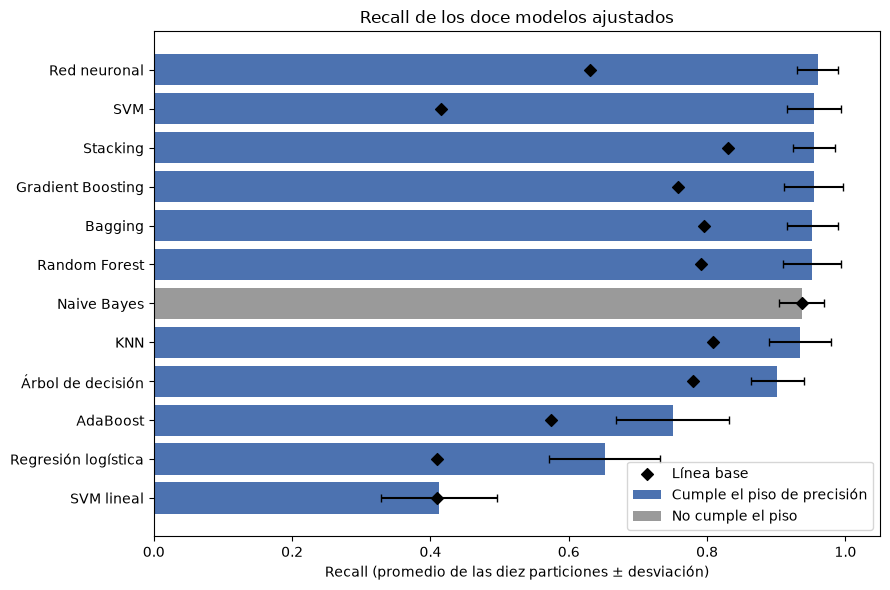

In [44]:
import matplotlib.pyplot as plt

orden = ajuste_ordenado.sort_values("Recall").reset_index(drop=True)
figura, eje = plt.subplots(figsize=(9, 6))
etiquetas_usadas = {}

for posicion in range(len(orden)):
    if orden.loc[posicion, "Cumple piso"] == "Sí":
        color = "#4C72B0"
        etiqueta = "Cumple el piso de precisión"
    else:
        color = "#9A9A9A"
        etiqueta = "No cumple el piso"
    if etiqueta in etiquetas_usadas:
        etiqueta = None
    else:
        etiquetas_usadas[etiqueta] = True
    eje.barh(posicion, orden.loc[posicion, "Recall"], xerr=orden.loc[posicion, "Desviación Recall"],
             color=color, capsize=3, label=etiqueta)

eje.scatter(orden["Recall línea base"], orden.index, color="black", marker="D", zorder=3, label="Línea base")
eje.set_yticks(orden.index)
eje.set_yticklabels(orden["Modelo"])
eje.set_xlim(0, 1.05)
eje.set_xlabel("Recall (promedio de las diez particiones ± desviación)")
eje.set_title("Recall de los doce modelos ajustados")
eje.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 9.6. Sobreajuste en KNN y en el árbol

Recorremos cada hiperparámetro de complejidad dejando fijo el resto de la configuración ajustada. Si el Recall de entrenamiento queda muy por encima del de validación hay sobreajuste; si los dos son bajos, el modelo es demasiado simple. La línea vertical marca el valor que eligió la búsqueda y la horizontal de precisión marca el piso.

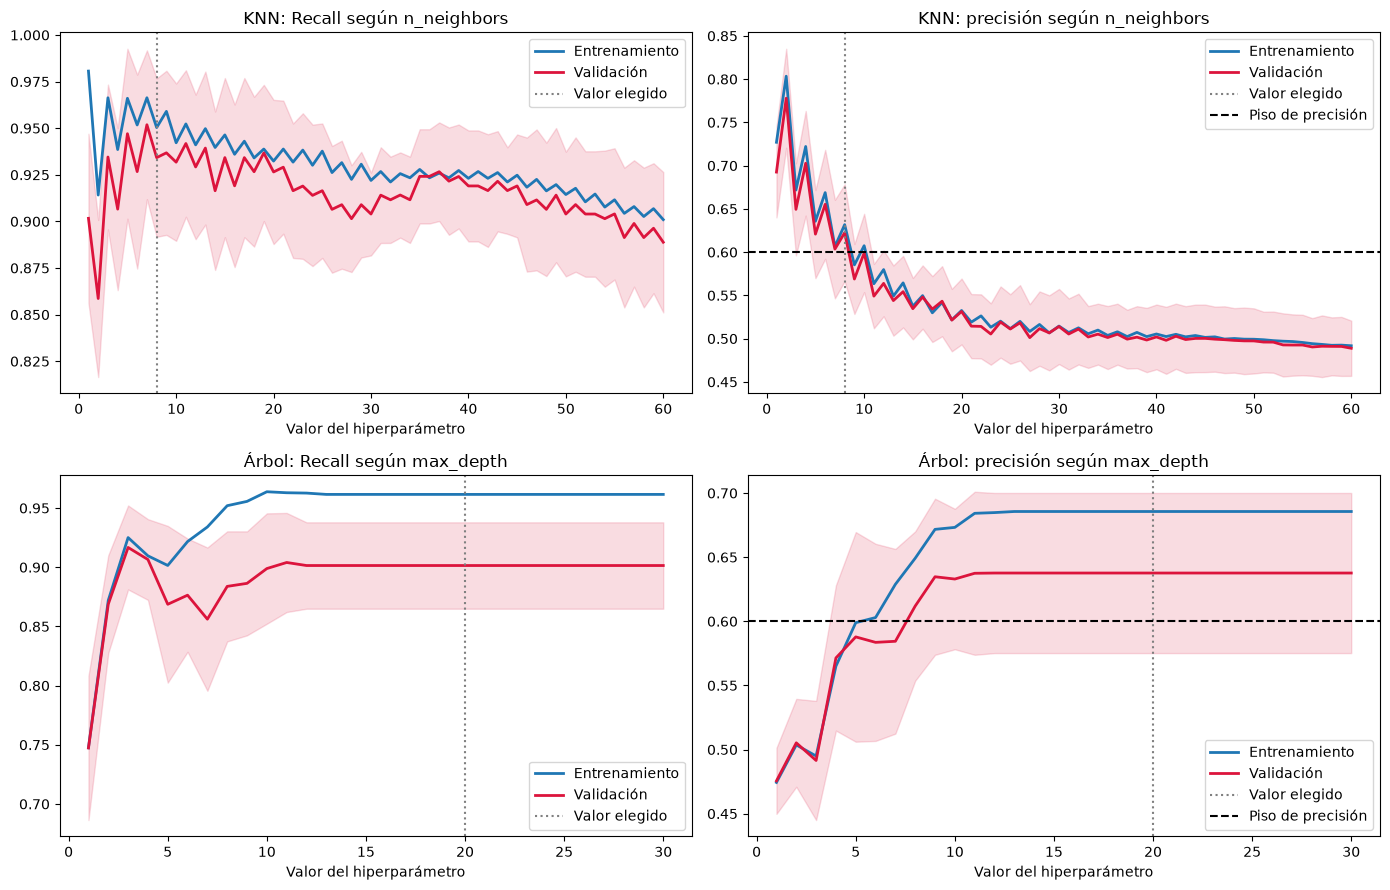

In [45]:
from sklearn.model_selection import validation_curve

def pipeline_ajustado(nombre):
    """Reconstruye el Pipeline ajustado de un modelo a partir de la tabla de resultados."""
    fila = ajuste[ajuste["Modelo"] == nombre].iloc[0]
    return armar_pipeline(
        modelo_base(nombre, parametros_ajustados),
        fila["Escalador"], fila["Balanceo"], parametros_ajustados[nombre]
    )


def curva_de_validacion(nombre, parametro, valores, metrica):
    """Calcula la métrica en entrenamiento y validación para un rango de un hiperparámetro."""
    return validation_curve(
        pipeline_ajustado(nombre), X_train, y_train, param_name=parametro,
        param_range=valores, cv=particiones, scoring=metrica, n_jobs=-1
    )


def graficar_curva(eje, valores, entrenamiento, validacion, titulo, elegido, piso):
    """Dibuja las curvas de entrenamiento y validación con su banda de desviación."""
    media_entrenamiento = entrenamiento.mean(axis=1)
    media_validacion = validacion.mean(axis=1)
    desviacion_validacion = validacion.std(axis=1)

    eje.plot(valores, media_entrenamiento, label="Entrenamiento", linewidth=2)
    eje.plot(valores, media_validacion, label="Validación", color="crimson", linewidth=2)
    eje.fill_between(valores, media_validacion - desviacion_validacion,
                     media_validacion + desviacion_validacion, color="crimson", alpha=0.15)
    if elegido is not None:
        eje.axvline(elegido, color="gray", linestyle=":", label="Valor elegido")
    if piso:
        eje.axhline(PISO_PRECISION, color="black", linestyle="--", label="Piso de precisión")
    eje.set_title(titulo)
    eje.legend()


valores_knn = []
for vecinos in range(1, 61):
    valores_knn.append(vecinos)

valores_arbol = []
for profundidad in range(1, 31):
    valores_arbol.append(profundidad)

figura, ejes = plt.subplots(2, 2, figsize=(14, 9))

recall_entrenamiento, recall_validacion = curva_de_validacion("KNN", "modelo__n_neighbors", valores_knn, "recall")
precision_entrenamiento, precision_validacion = curva_de_validacion("KNN", "modelo__n_neighbors", valores_knn, "precision")
vecinos_elegidos = parametros_ajustados["KNN"]["modelo__n_neighbors"]
graficar_curva(ejes[0, 0], valores_knn, recall_entrenamiento, recall_validacion, "KNN: Recall según n_neighbors", vecinos_elegidos, False)
graficar_curva(ejes[0, 1], valores_knn, precision_entrenamiento, precision_validacion, "KNN: precisión según n_neighbors", vecinos_elegidos, True)

recall_entrenamiento, recall_validacion = curva_de_validacion("Árbol de decisión", "modelo__max_depth", valores_arbol, "recall")
precision_entrenamiento, precision_validacion = curva_de_validacion("Árbol de decisión", "modelo__max_depth", valores_arbol, "precision")
profundidad_elegida = parametros_ajustados["Árbol de decisión"]["modelo__max_depth"]
graficar_curva(ejes[1, 0], valores_arbol, recall_entrenamiento, recall_validacion, "Árbol: Recall según max_depth", profundidad_elegida, False)
graficar_curva(ejes[1, 1], valores_arbol, precision_entrenamiento, precision_validacion, "Árbol: precisión según max_depth", profundidad_elegida, True)

for fila_ejes in ejes:
    for eje_curva in fila_ejes:
        eje_curva.set_xlabel("Valor del hiperparámetro")

plt.tight_layout()
plt.show()

El KNN pierde Recall de forma gradual al subir n_neighbors y su precisión cae por debajo del piso desde n_neighbors cercano a 10; la búsqueda eligió 8, justo antes de cruzarlo (Recall 0,9342 y precisión 0,6224). El árbol se separa de su validación desde profundidad 5 y se estabiliza pasando de 11: con la profundidad elegida el Recall es de alrededor de 0,96 en entrenamiento y 0,90 en validación, es decir, un sobreajuste moderado.

### 9.7. Matriz de confusión de cada modelo

Para ver qué errores comete cada modelo ajustado, predecimos a cada cliente de entrenamiento con un modelo que no lo vio: las diez particiones de siempre, con el escalado y el balanceo dentro de cada una. Con esas predicciones armamos la matriz de confusión de los doce modelos. Solo usamos el entrenamiento; la prueba sigue sin tocarse.

In [46]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay


predicciones = {}

for nombre_modelo in ajuste["Modelo"]:
    inicio = time.time()
    pipeline = pipeline_ajustado(nombre_modelo)
    predicciones[nombre_modelo] = cross_val_predict(pipeline, X_train, y_train, cv=particiones, n_jobs=-1)
    print(nombre_modelo, "-> listo (" + str(round(time.time() - inicio, 1)) + " s)")

KNN -> listo (0.1 s)
Naive Bayes -> listo (0.1 s)
Árbol de decisión -> listo (0.1 s)
Regresión logística -> listo (0.1 s)


SVM -> listo (0.2 s)
SVM lineal -> listo (0.1 s)


Red neuronal -> listo (1.6 s)


Random Forest -> listo (1.0 s)


Bagging -> listo (1.3 s)


AdaBoost -> listo (3.3 s)


Gradient Boosting -> listo (2.7 s)


Stacking -> listo (5.8 s)


Las doce matrices.

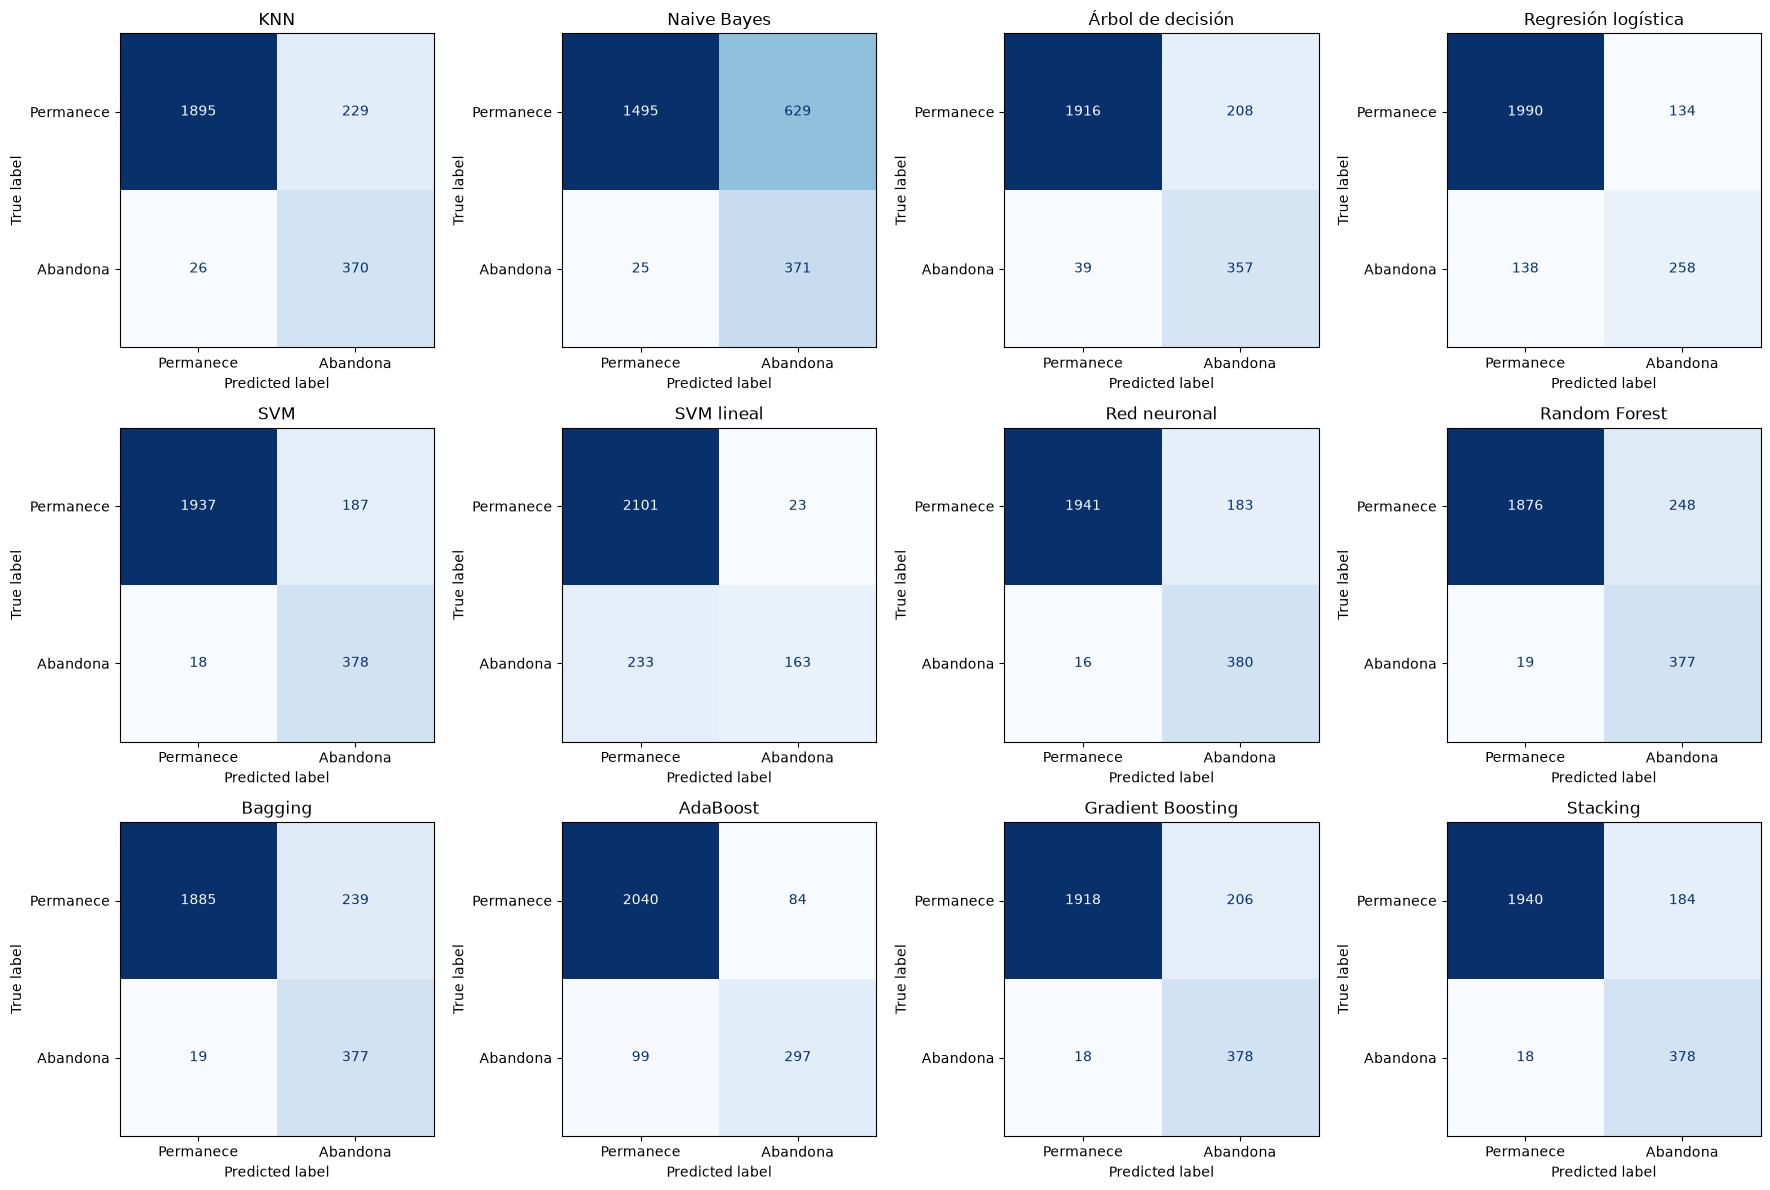

In [47]:
etiquetas = ["Permanece", "Abandona"]
figura, ejes = plt.subplots(3, 4, figsize=(18, 12))
ejes = ejes.flatten()

posicion = 0
for nombre_modelo in ajuste["Modelo"]:
    matriz = confusion_matrix(y_train, predicciones[nombre_modelo])
    pantalla = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=etiquetas)
    pantalla.plot(ax=ejes[posicion], cmap=plt.cm.Blues, colorbar=False, values_format="d")
    ejes[posicion].set_title(nombre_modelo)
    posicion += 1

plt.tight_layout()
plt.show()

Los mismos números en una tabla. Con el abandono como clase positiva, VP son los abandonos detectados, FN los abandonos que se escaparon, FP las alertas falsas y VN las permanencias bien clasificadas.

In [48]:
rows = []

for nombre_modelo in ajuste["Modelo"]:
    vn, fp, fn, vp = confusion_matrix(y_train, predicciones[nombre_modelo]).ravel()
    rows.append({
        "Modelo": nombre_modelo,
        "VP": int(vp),
        "FN": int(fn),
        "FP": int(fp),
        "VN": int(vn),
        "Recall": round(vp / (vp + fn), 4),
        "Precisión": round(vp / (vp + fp), 4)
    })

tabla_confusion = pd.DataFrame(rows).sort_values("Recall", ascending=False).reset_index(drop=True)
tabla_confusion

,Modelo,VP,FN,FP,VN,Recall,Precisión
0,Red neuronal,380,16,183,1941,0.9596,0.6750
1,Stacking,378,18,184,1940,0.9545,0.6726
2,SVM,378,18,187,1937,0.9545,0.6690
3,Gradient Boosting,378,18,206,1918,0.9545,0.6473
4,Bagging,377,19,239,1885,0.9520,0.6120
5,Random Forest,377,19,248,1876,0.9520,0.6032
6,Naive Bayes,371,25,629,1495,0.9369,0.3710
7,KNN,370,26,229,1895,0.9343,0.6177
8,Árbol de decisión,357,39,208,1916,0.9015,0.6319
9,AdaBoost,297,99,84,2040,0.7500,0.7795


La red neuronal detecta 380 de los 396 abandonos del entrenamiento con 183 falsas alertas (Recall 0,9596, precisión 0,6750). El Stacking y la SVM detectan 378 con 184 y 187 falsas alertas, y Gradient Boosting detecta 378 con 206. Naive Bayes detecta 371 pero genera 629 falsas alertas, más de seis de cada diez alertas equivocadas (precisión 0,3710). La SVM lineal solo detecta 163 de los 396 abandonos y la regresión logística 258. Estas matrices juntan las predicciones de las diez particiones, por eso su Recall difiere en el cuarto decimal del promedio por partición de la tabla anterior.

[Volver al índice](#indice)

<a id="seccion-10"></a>
## 10. Selección de variables, PCA y SHAP

Con los doce modelos ya ajustados probamos ahora cada uno con quince formas de usar las variables: todas, doce métodos de selección y tres variantes de PCA. Salen 180 combinaciones. Cada una se evalúa con las mismas diez particiones, y la selección va dentro del Pipeline, entre el balanceo y el modelo, para que se ajuste solo con la parte de entrenamiento de cada partición.

Los métodos son los del cuaderno de selección de rasgos de clase: ANOVA, chi cuadrado, información mutua, varianza baja, selección hacia adelante, RFECV, regularización L1, importancia de Gradient Boosting y SHAP en dos versiones, más el filtro de correlación entre variables y el PCA en tres versiones.

### 10.1. Partición interna

Dentro del entrenamiento separamos una parte interna de validación, 75 % y 25 %. Sirve únicamente para armar los subconjuntos de variables y para elegir cuántas conservar con cada modelo. La prueba no se toca.

In [49]:
import numpy as np

columnas = list(X_train.columns)
indices = np.arange(len(X_train))

indices_subtrain, indices_val = train_test_split(
    indices, test_size=0.25, random_state=42, stratify=y_train
)

X_subtrain = X_train.iloc[indices_subtrain]
y_subtrain = y_train.iloc[indices_subtrain]
X_val = X_train.iloc[indices_val]
y_val = y_train.iloc[indices_val]

print("Subentrenamiento:", X_subtrain.shape, "| Validación interna:", X_val.shape)

Subentrenamiento: (1890, 12) | Validación interna: (630, 12)


### 10.2. ANOVA

Con doce entradas no tenemos un problema de tamaño, pero sí vimos variables que casi no se mueven con el abandono y otras que se repiten entre sí. ANOVA puntúa cada variable por separado según cuánto separa a los dos grupos.

Empezamos por ANOVA. La prueba compara, para cada variable, el promedio de quienes abandonan con el de quienes permanecen. Un valor de F alto significa que los dos grupos están lejos, o sea que esa variable tiene un promedio muy diferente entre quienes abandonan y quienes no y permite diferenciarlos, y un p pequeño que sería poco probable observar una diferencia de medias tan grande como la encontrada, o mayor, si en realidad ambos grupos tuvieran la misma media.

In [50]:
from sklearn.feature_selection import f_classif

valores_f, valores_p = f_classif(X_train, y_train)

tabla_anova = pd.DataFrame({
    "Variable": X_train.columns,
    "F": valores_f.round(2),
    "p": valores_p.round(4)
})

tabla_anova = tabla_anova.sort_values("F", ascending=False)
tabla_anova

,Variable,F,p
1,quejas,968.57,0.0000
10,estado,839.51,0.0000
5,frecuencia_uso,259.48,0.0000
4,segundos_uso,252.24,0.0000
11,valor_cliente,229.31,0.0000
7,numeros_distintos,212.87,0.0000
6,frecuencia_sms,128.76,0.0000
3,nivel_cargo,108.20,0.0000
9,plan_tarifario,26.14,0.0000
2,antiguedad,4.49,0.0343


El orden coincide con el que dio phik: quejas con F de 968,57 y estado con 839,51 muy por delante, después el bloque de uso entre 259 y 128, y nivel_cargo con 108,20.

Al final quedan plan_tarifario con 26,14, antiguedad con 4,49 y p de 0,0343, y dos variables sin relación aparente: fallas_llamadas con F de 0,68 y p de 0,41, y grupo_edad con 0,11 y p de 0,74. Con esos p no podemos afirmar que sus promedios cambien entre quienes abandonan y quienes permanecen.

Conviene leerlo con cuidado. ANOVA mira cada variable sola y compara promedios, así que una F baja no quiere decir que la variable sea inútil: puede aportar combinada con otras, o separar los grupos de una forma que esta prueba no capta.

Más adelante ANOVA entra como uno de los quince métodos, dentro del Pipeline y con el número de variables que mejor le resulte a cada modelo.

### 10.3. Varianza baja y correlación entre variables

Estos dos filtros no usan el abandono para decidir qué quitar. Varianza baja descarta las variables que casi no cambian: usamos un umbral de 0,01 sobre las variables llevadas al rango de 0 a 1. Correlación entre variables mira cada pareja con correlación mayor a 0,85 y quita la que menos se asocia con el abandono.

Seis métodos entregan una lista de variables armada con la parte interna del entrenamiento: varianza baja, correlación, selección hacia adelante, RFECV, L1 y SHAP. Como esa parte después se usa en la validación cruzada, las cifras de esos métodos pueden salir algo optimistas. ANOVA, chi cuadrado, información mutua, la importancia de Gradient Boosting y el PCA se reajustan dentro del Pipeline en cada partición y no tienen ese sesgo. La validación anidada de 10.11 lo corrige para el ganador.

In [51]:
import json
import warnings
from functools import partial
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_validate
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import SelectFromModel
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.feature_selection import RFECV
from sklearn.feature_selection import f_classif
from sklearn.feature_selection import chi2
from sklearn.feature_selection import mutual_info_classif
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)

particiones_internas = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
listas_fijas = {}


def posiciones_de(mascara):
    """Convierte una máscara booleana en la lista de posiciones seleccionadas."""
    posiciones = []
    for posicion in range(len(mascara)):
        if mascara[posicion]:
            posiciones.append(posicion)
    return posiciones


def quitar_correlacionados(datos_entrada, objetivo, umbral):
    """Lista las variables a quitar de cada par con correlación mayor al umbral."""
    correlaciones = datos_entrada.corr().abs()
    con_objetivo = datos_entrada.corrwith(objetivo).abs()
    quitar = []

    for i in range(len(columnas)):
        for j in range(i + 1, len(columnas)):
            primera = columnas[i]
            segunda = columnas[j]
            if correlaciones.iloc[i, j] > umbral and primera not in quitar and segunda not in quitar:
                print("Par correlacionado:", primera, "y", segunda, "->", round(correlaciones.iloc[i, j], 3))
                if con_objetivo[primera] >= con_objetivo[segunda]:
                    quitar.append(segunda)
                else:
                    quitar.append(primera)
    return quitar


minmax_interno = MinMaxScaler().fit(X_subtrain)
filtro_varianza = VarianceThreshold(threshold=0.01).fit(minmax_interno.transform(X_subtrain))
listas_fijas["Varianza"] = {None: posiciones_de(filtro_varianza.get_support())}

quitar = quitar_correlacionados(X_subtrain, y_subtrain, 0.85)
conservar = []
for posicion in range(len(columnas)):
    if columnas[posicion] not in quitar:
        conservar.append(posicion)
listas_fijas["Correlación entre rasgos"] = {None: conservar}

print("Varianza baja conserva", len(listas_fijas["Varianza"][None]), "de", len(columnas), "variables")
print("Correlación entre rasgos quita:", quitar)

Par correlacionado: segundos_uso y frecuencia_uso -> 0.946
Par correlacionado: frecuencia_sms y valor_cliente -> 0.926
Varianza baja conserva 12 de 12 variables
Correlación entre rasgos quita: ['segundos_uso', 'frecuencia_sms']


El filtro de varianza conserva las doce variables: ninguna casi no cambia. La correlación encuentra dos parejas, segundos_uso con frecuencia_uso (0,946) y frecuencia_sms con valor_cliente (0,926), y quita segundos_uso y frecuencia_sms.

### 10.4. Selección hacia adelante y RFECV

Los dos usan una regresión logística con pesos balanceados sobre las variables estandarizadas. Dentro de estos métodos puntuamos con F1 y no con Recall: sin un piso de precisión, el Recall solo premiaría al subconjunto que alerta a todos. Para la selección hacia adelante armamos una lista por cada tamaño, de 1 a 11 variables, y después cada modelo escoge el tamaño que le conviene. RFECV entrega una sola lista, junto con su curva.

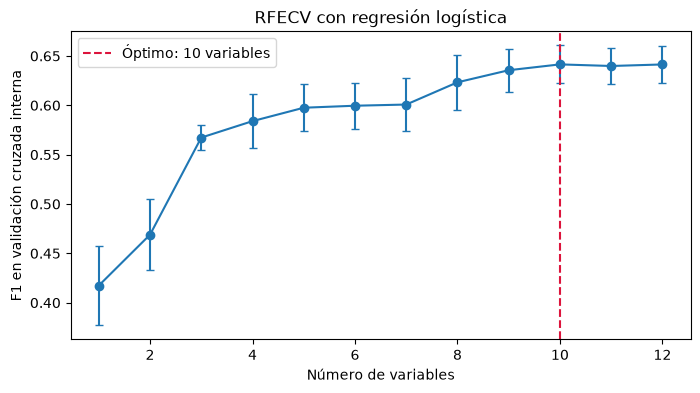

Forward Selection, variables con k = 5: [1, 2, 4, 9, 10]
RFECV elige 10 variables


In [52]:
import matplotlib.pyplot as plt

regresion_interna = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)

listas_fijas["Forward Selection"] = {}
for tamano in range(1, len(columnas)):
    seleccion_adelante = Pipeline([
        ("escalador", StandardScaler()),
        ("seleccion", SequentialFeatureSelector(
            clone(regresion_interna), n_features_to_select=tamano, direction="forward",
            scoring="f1", cv=particiones_internas, n_jobs=-1
        ))
    ])
    seleccion_adelante.fit(X_subtrain, y_subtrain)
    listas_fijas["Forward Selection"][tamano] = posiciones_de(seleccion_adelante.named_steps["seleccion"].get_support())

seleccion_rfecv = Pipeline([
    ("escalador", StandardScaler()),
    ("rfecv", RFECV(
        clone(regresion_interna), step=1, cv=particiones_internas, scoring="f1",
        min_features_to_select=1, n_jobs=-1
    ))
])
seleccion_rfecv.fit(X_subtrain, y_subtrain)
rfecv = seleccion_rfecv.named_steps["rfecv"]
listas_fijas["RFECV"] = {None: posiciones_de(rfecv.support_)}

cantidades = np.arange(1, len(rfecv.cv_results_["mean_test_score"]) + 1)
plt.figure(figsize=(8, 4))
plt.errorbar(cantidades, rfecv.cv_results_["mean_test_score"], yerr=rfecv.cv_results_["std_test_score"],
             marker="o", capsize=3)
plt.axvline(rfecv.n_features_, color="crimson", linestyle="--", label="Óptimo: " + str(rfecv.n_features_) + " variables")
plt.xlabel("Número de variables")
plt.ylabel("F1 en validación cruzada interna")
plt.title("RFECV con regresión logística")
plt.legend()
plt.show()

print("Forward Selection, variables con k = 5:", listas_fijas["Forward Selection"][5])
print("RFECV elige", rfecv.n_features_, "variables")

Con cinco variables, la selección hacia adelante se queda con quejas, antiguedad, segundos_uso, plan_tarifario y estado. RFECV elige diez variables.

### 10.5. Regularización L1

Regresión logística con penalización L1 sobre las variables estandarizadas: se queda con las variables de coeficiente distinto de cero. Usamos C de 0,1 como en el cuaderno de clase y, si no queda ninguna variable, C de 1.

In [53]:
valores_c = [0.1, 1.0]

for valor_c in valores_c:
    seleccion_l1 = Pipeline([
        ("escalador", StandardScaler()),
        ("seleccion", SelectFromModel(LogisticRegression(
            l1_ratio=1, solver="liblinear", C=valor_c, class_weight="balanced",
            max_iter=2000, random_state=42
        )))
    ])
    seleccion_l1.fit(X_subtrain, y_subtrain)
    mascara_l1 = seleccion_l1.named_steps["seleccion"].get_support()
    if mascara_l1.sum() > 0:
        break

listas_fijas["L1"] = {None: posiciones_de(mascara_l1)}
print("L1 con C =", valor_c, "conserva", len(listas_fijas["L1"][None]), "variables")

L1 con C = 0.1 conserva 10 variables


Con C de 0,1 quedan diez variables: L1 deja fuera a segundos_uso y valor_cliente.

### 10.6. SHAP

SHAP mide cuánto aporta cada variable a la predicción de un modelo. El ranking de esta sección sale de un solo modelo: el Gradient Boosting ajustado en la sección 9, entrenado con la parte interna y con su escalador y su balanceo. Con TreeExplainer calculamos el aporte de cada variable y el ranking es el promedio de su valor absoluto. De ese ranking salen dos tipos de lista: las k variables más importantes, con k de 1 a 11, y las que acumulan el 95 % de la importancia.

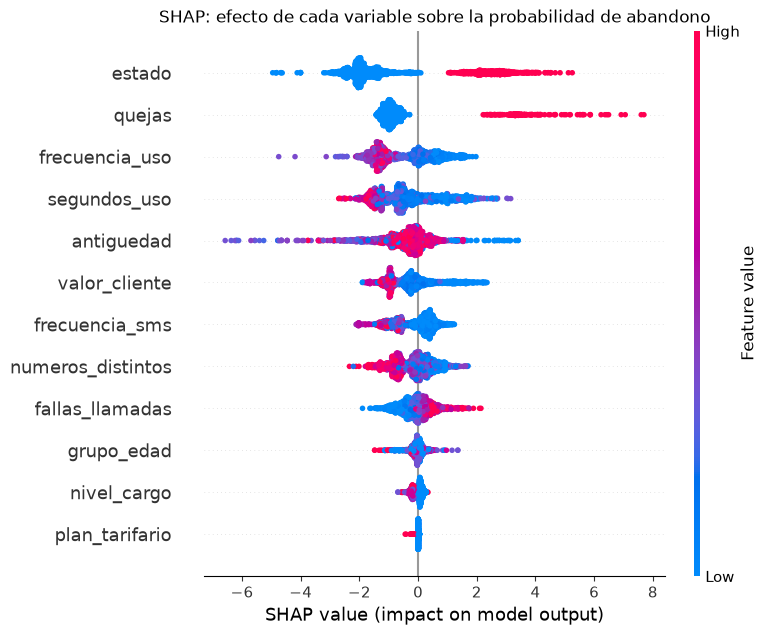

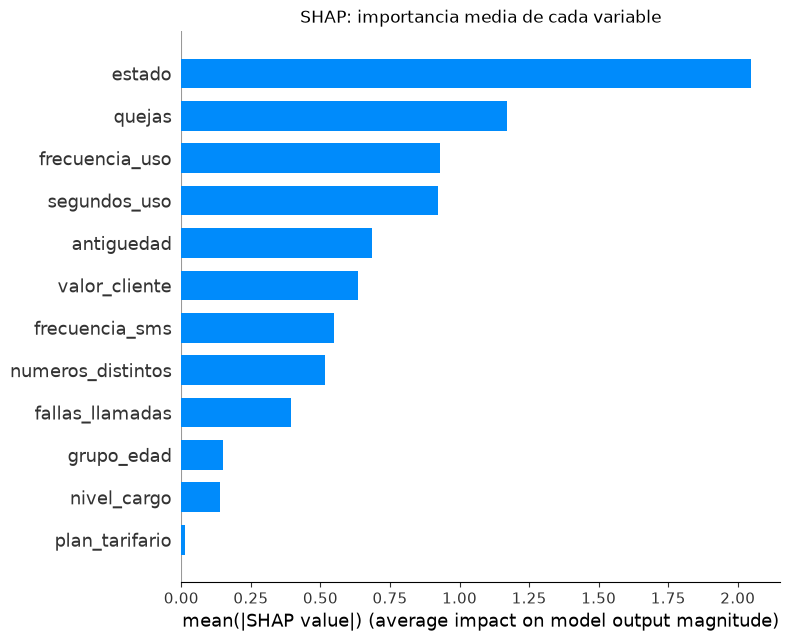

,Variable,Importancia media,Acumulada
0,estado,2.0492,0.2513
1,quejas,1.1689,0.3947
2,frecuencia_uso,0.9304,0.5088
3,segundos_uso,0.9215,0.6218
4,antiguedad,0.6856,0.7059
5,valor_cliente,0.6357,0.7839
6,frecuencia_sms,0.5478,0.8510
7,numeros_distintos,0.5176,0.9145
8,fallas_llamadas,0.3948,0.9629
9,grupo_edad,0.1506,0.9814


In [54]:
warnings.filterwarnings("ignore", message="IProgress not found")

import shap

pipeline_shap = pipeline_ajustado("Gradient Boosting")
pipeline_shap.fit(X_subtrain, y_subtrain)

X_shap = pd.DataFrame(pipeline_shap.named_steps["escalador"].transform(X_subtrain), columns=columnas)
explicador = shap.TreeExplainer(pipeline_shap.named_steps["modelo"])
valores_shap = explicador.shap_values(X_shap)

if isinstance(valores_shap, list):
    valores_shap = valores_shap[1]
if valores_shap.ndim == 3:
    valores_shap = valores_shap[:, :, 1]

shap.summary_plot(valores_shap, X_shap, show=False)
plt.title("SHAP: efecto de cada variable sobre la probabilidad de abandono")
plt.show()

shap.summary_plot(valores_shap, X_shap, plot_type="bar", show=False)
plt.title("SHAP: importancia media de cada variable")
plt.show()

importancia_shap = pd.Series(np.abs(valores_shap).mean(axis=0), index=columnas).sort_values(ascending=False)
ranking_shap = pd.DataFrame({
    "Variable": importancia_shap.index,
    "Importancia media": importancia_shap.values.round(4),
    "Acumulada": (importancia_shap / importancia_shap.sum()).cumsum().values.round(4)
})
ranking_shap

El ranking lo encabezan estado, con 2,0492, y quejas, con 1,1689. Junto con frecuencia_uso y segundos_uso reúnen el 62,18 % de la importancia, y plan_tarifario cierra con 0,0141.

In [55]:
listas_fijas["SHAP top-k"] = {}
for tamano in range(1, len(columnas)):
    posiciones_top = []
    for nombre_variable in importancia_shap.index[:tamano]:
        posiciones_top.append(columnas.index(nombre_variable))
    listas_fijas["SHAP top-k"][tamano] = sorted(posiciones_top)

acumulada = (importancia_shap / importancia_shap.sum()).cumsum()
posiciones_95 = []
for nombre_variable in acumulada.index:
    if acumulada[nombre_variable] <= 0.95:
        posiciones_95.append(columnas.index(nombre_variable))
if len(posiciones_95) == 0:
    posiciones_95.append(columnas.index(acumulada.index[0]))
listas_fijas["SHAP 95 %"] = {None: sorted(posiciones_95)}

print("SHAP 95 % acumulado conserva", len(posiciones_95), "variables")

SHAP 95 % acumulado conserva 8 variables


El 95 % acumulado se alcanza con ocho variables.

### 10.7. PCA

Pasamos al PCA (Principal Component Analysis). Lo aplicamos sobre los datos escalados, porque las componentes se construyen buscando la mayor variación y sin escalar se las llevarían las variables de números grandes. Ajustamos el escalador con el entrenamiento, como quedó dicho en 7.1, y miramos cuánta variación conserva cada cantidad de componentes.

In [56]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

norm = MinMaxScaler().fit(X_train)
X_train_norm = norm.transform(X_train)

componentes = PCA()
componentes.fit(X_train_norm)

varianza_acumulada = componentes.explained_variance_ratio_.cumsum()

rows = []

for i in range(len(varianza_acumulada)):
    rows.append({
        "Componentes": i + 1,
        "% de varianza acumulada": round(varianza_acumulada[i] * 100, 2)
    })

tabla_pca = pd.DataFrame(rows)
tabla_pca

,Componentes,% de varianza acumulada
0,1,38.11
1,2,52.74
2,3,64.89
3,4,74.43
4,5,82.63
5,6,89.37
6,7,93.68
7,8,96.70
8,9,98.52
9,10,99.71


La compresión es escasa. Hacen falta siete componentes para conservar el 90 % de la variación y ocho para el 95 %, partiendo de doce variables. Las dos primeras juntas apenas reúnen el 52,74 %.

Es coherente con lo que vimos en 6.7: las variables de uso se solapan entre sí, pero las categóricas aportan variación propia que no se deja resumir.

Con las variables estandarizadas miramos además cuántos componentes hacen falta para llegar al 95 % de la varianza y cómo se ven los dos primeros según el abandono. Es una vista general; dentro de cada Pipeline el PCA usa el escalador que eligió la búsqueda para ese modelo.

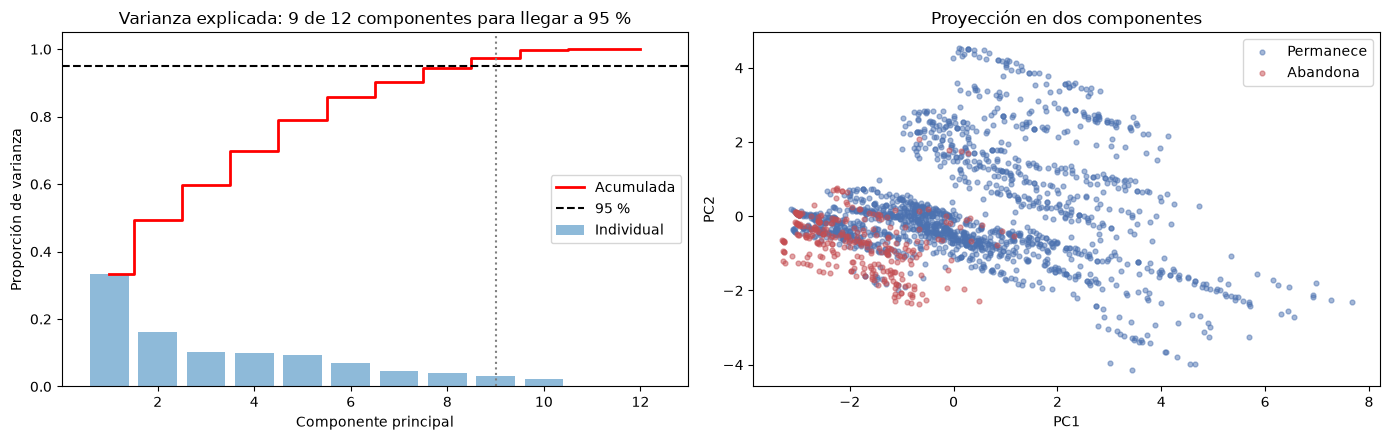

In [57]:
X_subtrain_estandar = StandardScaler().fit_transform(X_subtrain)
pca_completo = PCA(random_state=42).fit(X_subtrain_estandar)
varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)
componentes_95 = int(np.searchsorted(varianza_acumulada, 0.95) + 1)
numeros = np.arange(1, len(varianza_acumulada) + 1)

figura, ejes = plt.subplots(1, 2, figsize=(14, 4.5))

ejes[0].bar(numeros, pca_completo.explained_variance_ratio_, alpha=0.5, label="Individual")
ejes[0].step(numeros, varianza_acumulada, where="mid", color="red", linewidth=2, label="Acumulada")
ejes[0].axhline(0.95, color="black", linestyle="--", label="95 %")
ejes[0].axvline(componentes_95, color="gray", linestyle=":")
ejes[0].set_xlabel("Componente principal")
ejes[0].set_ylabel("Proporción de varianza")
ejes[0].set_title("Varianza explicada: " + str(componentes_95) + " de " + str(len(numeros)) + " componentes para llegar a 95 %")
ejes[0].legend()

proyeccion = PCA(n_components=2, random_state=42).fit_transform(X_subtrain_estandar)
for clase, etiqueta, color in [(0, "Permanece", "#4C72B0"), (1, "Abandona", "#C44E52")]:
    seleccionados = (y_subtrain == clase).values
    ejes[1].scatter(proyeccion[seleccionados, 0], proyeccion[seleccionados, 1], c=color, alpha=0.5, s=12, label=etiqueta)
ejes[1].set_xlabel("PC1")
ejes[1].set_ylabel("PC2")
ejes[1].set_title("Proyección en dos componentes")
ejes[1].legend()

plt.tight_layout()
plt.show()

### 10.8. Los quince métodos como pasos del Pipeline

La función de abajo devuelve el paso de selección de cada método. A los que se reajustan dentro del Pipeline les damos el número de variables k, y a las listas fijas las aplicamos con un ColumnTransformer. El chi cuadrado necesita valores no negativos, así que su puntaje se calcula sobre las columnas llevadas al rango de 0 a 1 sin cambiar los datos que llegan al modelo.

Los métodos con k variable (ANOVA, chi cuadrado, información mutua, importancia de Gradient Boosting, selección hacia adelante, SHAP y PCA con k) se prueban con cada k, y cada modelo se queda con el k de mayor Recall que cumple el piso de precisión en la validación interna. Si dos k empatan, gana el más pequeño.

In [58]:
from sklearn.ensemble import GradientBoostingClassifier

mi_con_semilla = partial(mutual_info_classif, random_state=42)

metodos = [
    "Todos los rasgos", "ANOVA", "Chi2", "Información mutua", "Varianza",
    "Forward Selection", "RFECV", "L1", "Importancia Gradient Boosting",
    "SHAP top-k", "SHAP 95 %", "PCA 95 %", "PCA k",
    "Correlación entre rasgos", "PCA 2D"
]

tamanos_1_a_11 = []
for tamano in range(1, len(columnas)):
    tamanos_1_a_11.append(tamano)

tamanos_1_a_12 = tamanos_1_a_11 + [len(columnas)]

ks_por_metodo = {}
for metodo in metodos:
    ks_por_metodo[metodo] = [None]
for metodo in ["ANOVA", "Chi2", "Información mutua", "Importancia Gradient Boosting", "Forward Selection", "SHAP top-k"]:
    ks_por_metodo[metodo] = tamanos_1_a_11
ks_por_metodo["PCA k"] = tamanos_1_a_12


def puntaje_chi2(X_datos, y_datos):
    """Puntaje chi cuadrado de cada columna después de llevarla al rango 0 a 1."""
    return chi2(MinMaxScaler().fit_transform(X_datos), y_datos)


def construir_selector(metodo, k):
    """Devuelve el paso de selección de un método para k rasgos."""
    if metodo == "Todos los rasgos":
        return "passthrough"
    if metodo == "ANOVA":
        return SelectKBest(f_classif, k=k)
    if metodo == "Chi2":
        return SelectKBest(puntaje_chi2, k=k)
    if metodo == "Información mutua":
        return SelectKBest(mi_con_semilla, k=k)
    if metodo == "Importancia Gradient Boosting":
        return SelectFromModel(GradientBoostingClassifier(random_state=42), threshold=-np.inf, max_features=k)
    if metodo == "PCA 95 %":
        return PCA(n_components=0.95, random_state=42)
    if metodo == "PCA k":
        return PCA(n_components=k, random_state=42)
    if metodo == "PCA 2D":
        return PCA(n_components=2, random_state=42)
    return ColumnTransformer([("seleccion", "passthrough", listas_fijas[metodo][k])], remainder="drop")


def pipeline_con_seleccion(nombre, metodo, k):
    """Arma el Pipeline ajustado del modelo con la selección entre el balanceo y el modelo."""
    pasos = pipeline_ajustado(nombre).steps
    return Pipeline([pasos[0], pasos[1], ("seleccion", construir_selector(metodo, k)), pasos[2]])


modelos_matriz = []
for nombre_modelo in ajuste["Modelo"]:
    modelos_matriz.append(nombre_modelo)

print("Modelos:", len(modelos_matriz), "| Métodos:", len(metodos))

Modelos: 12 | Métodos: 15


### 10.9. La matriz

Elegir k usa una búsqueda en rejilla sobre el paso de selección, con una sola partición: el subentrenamiento para ajustar y la validación interna para medir. Reutilizamos la función de 8.2 para escoger entre los k. Evaluar una combinación corre las diez particiones sobre todo el entrenamiento.

In [59]:
def elegir_k(nombre, metodo):
    """Elige el k de un método para un modelo con la validación interna y devuelve también su curva."""
    ks = ks_por_metodo[metodo]
    if len(ks) == 1:
        return ks[0], None

    candidatos = []
    for k in ks:
        candidatos.append(construir_selector(metodo, k))

    busqueda = GridSearchCV(
        pipeline_con_seleccion(nombre, metodo, ks[0]), {"seleccion": candidatos},
        cv=[(indices_subtrain, indices_val)], scoring=metricas, refit=False,
        n_jobs=-1, error_score=0.0
    )
    busqueda.fit(X_train, y_train)
    resultados = busqueda.cv_results_
    mejor = elegir_por_recall(resultados)

    curva = []
    for posicion in range(len(ks)):
        curva.append({
            "Modelo": nombre,
            "Método": metodo,
            "k": ks[posicion],
            "Recall": resultados["mean_test_recall"][posicion],
            "Precisión": resultados["mean_test_precision"][posicion]
        })
    return ks[mejor], curva


def evaluar_celda(nombre, metodo, k):
    """Evalúa un modelo con un método de selección en las diez particiones del entrenamiento."""
    resultados = cross_validate(
        pipeline_con_seleccion(nombre, metodo, k), X_train, y_train, cv=particiones,
        scoring=metricas, n_jobs=-1, error_score=0.0
    )
    return {
        "Recall": resultados["test_recall"].mean(),
        "Desviación Recall": pd.Series(resultados["test_recall"]).std(),
        "Precisión": resultados["test_precision"].mean(),
        "F1": resultados["test_f1"].mean()
    }


def rasgos_elegidos(nombre, metodo, k):
    """Devuelve los nombres de los rasgos que deja el método al ajustarse con todo el entrenamiento."""
    if metodo == "Todos los rasgos":
        return columnas
    if metodo in listas_fijas:
        nombres = []
        for posicion in listas_fijas[metodo][k]:
            nombres.append(columnas[posicion])
        return nombres

    previo = Pipeline(pipeline_con_seleccion(nombre, metodo, k).steps[:3])
    previo.fit(X_train, y_train)
    seleccion = previo.named_steps["seleccion"]
    if metodo.startswith("PCA"):
        return ["PCA con " + str(seleccion.n_components_) + " componentes"]

    nombres = []
    for posicion in posiciones_de(seleccion.get_support()):
        nombres.append(columnas[posicion])
    return nombres

Corremos las 180 combinaciones: doce modelos por quince métodos, cada una con la elección de k en la validación interna y las diez particiones. Cada combinación terminada se guarda en el archivo de resultados, y con REANUDAR_MATRIZ en True una ejecución interrumpida o repetida salta las que ya están.

In [60]:
REANUDAR_MATRIZ = True
ruta_matriz = RUTA_RESULTADOS + "matriz_combinaciones.csv"
ruta_curvas = RUTA_RESULTADOS + "curvas_k.csv"

filas_matriz = []
filas_curvas = []

if REANUDAR_MATRIZ and os.path.exists(ruta_matriz):
    filas_matriz = pd.read_csv(ruta_matriz).to_dict("records")
if REANUDAR_MATRIZ and os.path.exists(ruta_curvas):
    filas_curvas = pd.read_csv(ruta_curvas).to_dict("records")

celdas_hechas = []
for fila in filas_matriz:
    celdas_hechas.append(fila["Modelo"] + "|" + fila["Método"])

for nombre_modelo in modelos_matriz:
    inicio_modelo = time.time()
    nuevas = 0

    for metodo in metodos:
        if nombre_modelo + "|" + metodo in celdas_hechas:
            continue

        inicio = time.time()
        k, curva = elegir_k(nombre_modelo, metodo)
        resultado = evaluar_celda(nombre_modelo, metodo, k)
        rasgos = rasgos_elegidos(nombre_modelo, metodo, k)

        filas_matriz.append({
            "Modelo": nombre_modelo,
            "Método": metodo,
            "k": k,
            "Número de rasgos": len(rasgos),
            "Rasgos": json.dumps(rasgos),
            "Recall": resultado["Recall"],
            "Desviación Recall": resultado["Desviación Recall"],
            "Precisión": resultado["Precisión"],
            "F1": resultado["F1"],
            "Segundos": time.time() - inicio
        })
        pd.DataFrame(filas_matriz).to_csv(ruta_matriz, index=False)

        if curva is not None:
            for punto in curva:
                filas_curvas.append(punto)
            pd.DataFrame(filas_curvas).to_csv(ruta_curvas, index=False)
        nuevas += 1

    print(nombre_modelo, "->", nuevas, "celdas nuevas (" + str(round((time.time() - inicio_modelo) / 60, 1)) + " min)")

KNN -> 0 celdas nuevas (0.0 min)
Naive Bayes -> 0 celdas nuevas (0.0 min)
Árbol de decisión -> 0 celdas nuevas (0.0 min)
Regresión logística -> 0 celdas nuevas (0.0 min)
SVM -> 0 celdas nuevas (0.0 min)
SVM lineal -> 0 celdas nuevas (0.0 min)
Red neuronal -> 0 celdas nuevas (0.0 min)
Random Forest -> 0 celdas nuevas (0.0 min)
Bagging -> 0 celdas nuevas (0.0 min)
AdaBoost -> 0 celdas nuevas (0.0 min)
Gradient Boosting -> 0 celdas nuevas (0.0 min)
Stacking -> 0 celdas nuevas (0.0 min)


### 10.10. Resultados de la matriz

Primero comprobamos que la columna de todos los rasgos coincide con el ajuste de la sección 9, porque es la misma configuración medida con las mismas particiones.

In [61]:
matriz = pd.DataFrame(filas_matriz)

for posicion in range(len(matriz)):
    descripcion = json.loads(matriz.loc[posicion, "Rasgos"])[0]
    if descripcion.startswith("PCA con"):
        matriz.loc[posicion, "Número de rasgos"] = int(descripcion.split()[2])

todos = matriz[matriz["Método"] == "Todos los rasgos"]
diferencias = []
for fila in todos.to_dict("records"):
    recall_ajuste = ajuste[ajuste["Modelo"] == fila["Modelo"]]["Recall"].iloc[0]
    diferencias.append(abs(fila["Recall"] - recall_ajuste))

print("Mayor diferencia de Recall entre la matriz y la sección 4:", round(max(diferencias), 6))

Mayor diferencia de Recall entre la matriz y la sección 4: 0.0


La diferencia es 0,0: las dos secciones están midiendo lo mismo.

Ahora el Recall de cada combinación en un mapa de calor. Las celdas grises no alcanzan el piso de precisión, así que su Recall no cuenta.

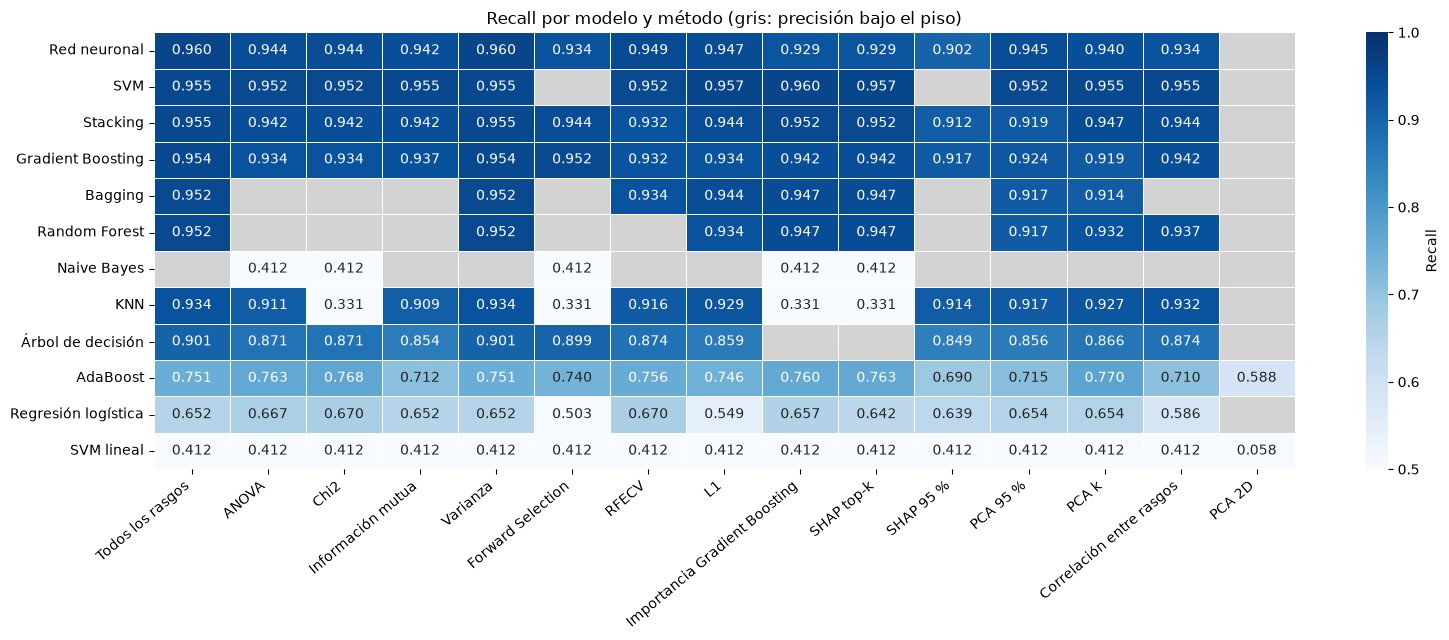

In [62]:
import seaborn as sns

orden_metodos = metodos
orden_modelos = list(ajuste_ordenado["Modelo"])

tabla_recall = matriz.pivot(index="Modelo", columns="Método", values="Recall").reindex(index=orden_modelos, columns=orden_metodos)
tabla_precision = matriz.pivot(index="Modelo", columns="Método", values="Precisión").reindex(index=orden_modelos, columns=orden_metodos)

figura, eje = plt.subplots(figsize=(16, 6.5))
sns.heatmap(tabla_recall, mask=tabla_precision < PISO_PRECISION, annot=True, fmt=".3f", cmap="Blues",
            vmin=0.5, vmax=1.0, linewidths=0.5, cbar_kws={"label": "Recall"}, ax=eje)
eje.set_facecolor("lightgray")
eje.set_title("Recall por modelo y método (gris: precisión bajo el piso)")
eje.set_xlabel("")
eje.set_ylabel("")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

La precisión de las mismas combinaciones.

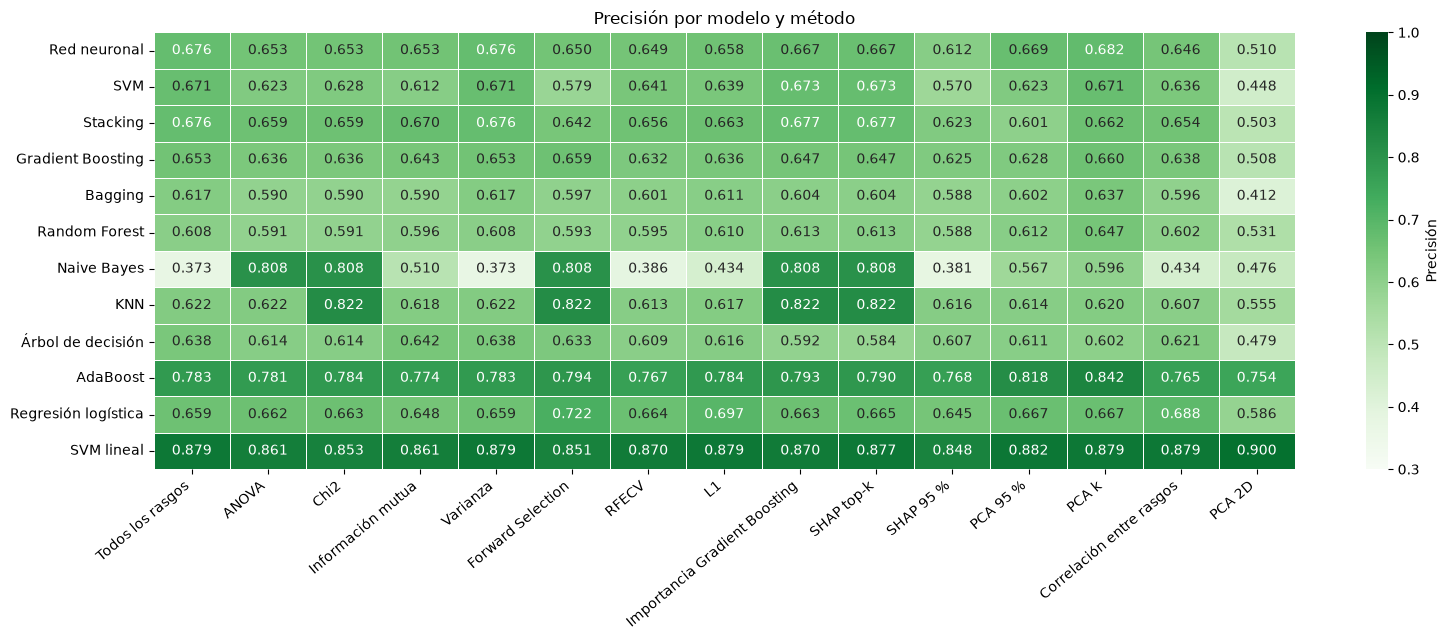

In [63]:
figura, eje = plt.subplots(figsize=(16, 6.5))
sns.heatmap(tabla_precision, annot=True, fmt=".3f", cmap="Greens", vmin=0.3, vmax=1.0,
            linewidths=0.5, cbar_kws={"label": "Precisión"}, ax=eje)
eje.set_title("Precisión por modelo y método")
eje.set_xlabel("")
eje.set_ylabel("")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

La mejor combinación de cada modelo, con el mismo criterio de 8.2: mayor Recall con precisión sobre el piso.

In [64]:
rows = []

for nombre_modelo in orden_modelos:
    del_modelo = matriz[(matriz["Modelo"] == nombre_modelo) & (matriz["Precisión"] >= PISO_PRECISION)]
    if len(del_modelo) == 0:
        rows.append({"Modelo": nombre_modelo, "Método": "ninguno cumple el piso"})
        continue
    mejor_fila = del_modelo.sort_values(["Recall", "F1"], ascending=False).iloc[0]
    rows.append({
        "Modelo": nombre_modelo,
        "Método": mejor_fila["Método"],
        "Número de rasgos": mejor_fila["Número de rasgos"],
        "Recall": round(mejor_fila["Recall"], 4),
        "Desviación Recall": round(mejor_fila["Desviación Recall"], 4),
        "Precisión": round(mejor_fila["Precisión"], 4),
        "F1": round(mejor_fila["F1"], 4)
    })

mejor_por_modelo = pd.DataFrame(rows)
mejor_por_modelo

,Modelo,Método,Número de rasgos,Recall,Desviación Recall,Precisión,F1
0,Red neuronal,Todos los rasgos,12,0.9597,0.0297,0.6762,0.7931
1,SVM,Importancia Gradient Boosting,11,0.9597,0.0395,0.6731,0.7905
2,Stacking,Todos los rasgos,12,0.9546,0.0309,0.6759,0.7905
3,Gradient Boosting,Todos los rasgos,12,0.9545,0.0427,0.6530,0.7734
4,Bagging,Todos los rasgos,12,0.9520,0.0367,0.6173,0.7472
5,Random Forest,Todos los rasgos,12,0.9520,0.0421,0.6078,0.7401
6,Naive Bayes,ANOVA,1,0.4121,0.0836,0.8078,0.5423
7,KNN,Todos los rasgos,12,0.9342,0.0448,0.6224,0.7457
8,Árbol de decisión,Todos los rasgos,12,0.9015,0.0385,0.6377,0.7452
9,AdaBoost,PCA k,12,0.7704,0.0502,0.8425,0.8039


Y las veinte mejores combinaciones de toda la matriz.

In [65]:
cumplen = matriz[matriz["Precisión"] >= PISO_PRECISION]
ranking_general = cumplen.sort_values(["Recall", "F1"], ascending=False).head(20).reset_index(drop=True)

ranking_general = ranking_general[["Modelo", "Método", "Número de rasgos", "Recall", "Desviación Recall", "Precisión", "F1"]].copy()
for columna in ["Recall", "Desviación Recall", "Precisión", "F1"]:
    ranking_general[columna] = ranking_general[columna].round(4)

print("Combinaciones que cumplen el piso:", len(cumplen), "de", len(matriz))
ranking_general

Combinaciones que cumplen el piso: 145 de 180


,Modelo,Método,Número de rasgos,Recall,Desviación Recall,Precisión,F1
0,Red neuronal,Todos los rasgos,12,0.9597,0.0297,0.6762,0.7931
1,Red neuronal,Varianza,12,0.9597,0.0297,0.6762,0.7931
2,SVM,Importancia Gradient Boosting,11,0.9597,0.0395,0.6731,0.7905
3,SVM,L1,10,0.9571,0.0375,0.6390,0.7659
4,SVM,SHAP top-k,11,0.9571,0.0374,0.6726,0.7893
5,SVM,Información mutua,11,0.9547,0.0369,0.6118,0.7443
6,SVM,Todos los rasgos,12,0.9546,0.0387,0.6707,0.7872
7,SVM,Varianza,12,0.9546,0.0387,0.6707,0.7872
8,SVM,PCA k,11,0.9546,0.0387,0.6707,0.7872
9,SVM,Correlación entre rasgos,10,0.9546,0.0406,0.6356,0.7621


De las 180 combinaciones, 145 cumplen el piso de precisión. El mejor Recall es 0,9597 y lo alcanzan tres combinaciones: la red neuronal con todos los rasgos (precisión 0,6762), la misma red con el filtro de varianza baja, que no quita ninguna de las doce variables y por eso es idéntica, y la SVM con la importancia de Gradient Boosting (11 variables, precisión 0,6731).

Quitar variables casi nunca ayuda: en siete de los doce modelos (red neuronal, Stacking, Gradient Boosting, Bagging, Random Forest, KNN y árbol) la mejor combinación es la de todos los rasgos. La selección sí mejora algo en la SVM (de 0,9546 a 0,9597 con la importancia de Gradient Boosting), en AdaBoost (de 0,7506 a 0,7704 con PCA de k componentes) y en la regresión logística (de 0,6519 a 0,6697 con chi cuadrado), pero son diferencias menores que la desviación entre particiones. Naive Bayes solo cumple el piso con combinaciones de una variable, con Recall de 0,4121. PCA con dos componentes casi nunca cumple el piso: solo AdaBoost y la SVM lineal quedan sobre él, con Recall de 0,588 y 0,058.

Las listas fijas son algo optimistas, y aun así ninguna supera a la columna de todos los rasgos; la conclusión de que seleccionar no sube el Recall se sostiene.

Cómo cambia el Recall en la validación interna al variar el número de variables k, en los métodos que lo recorren.

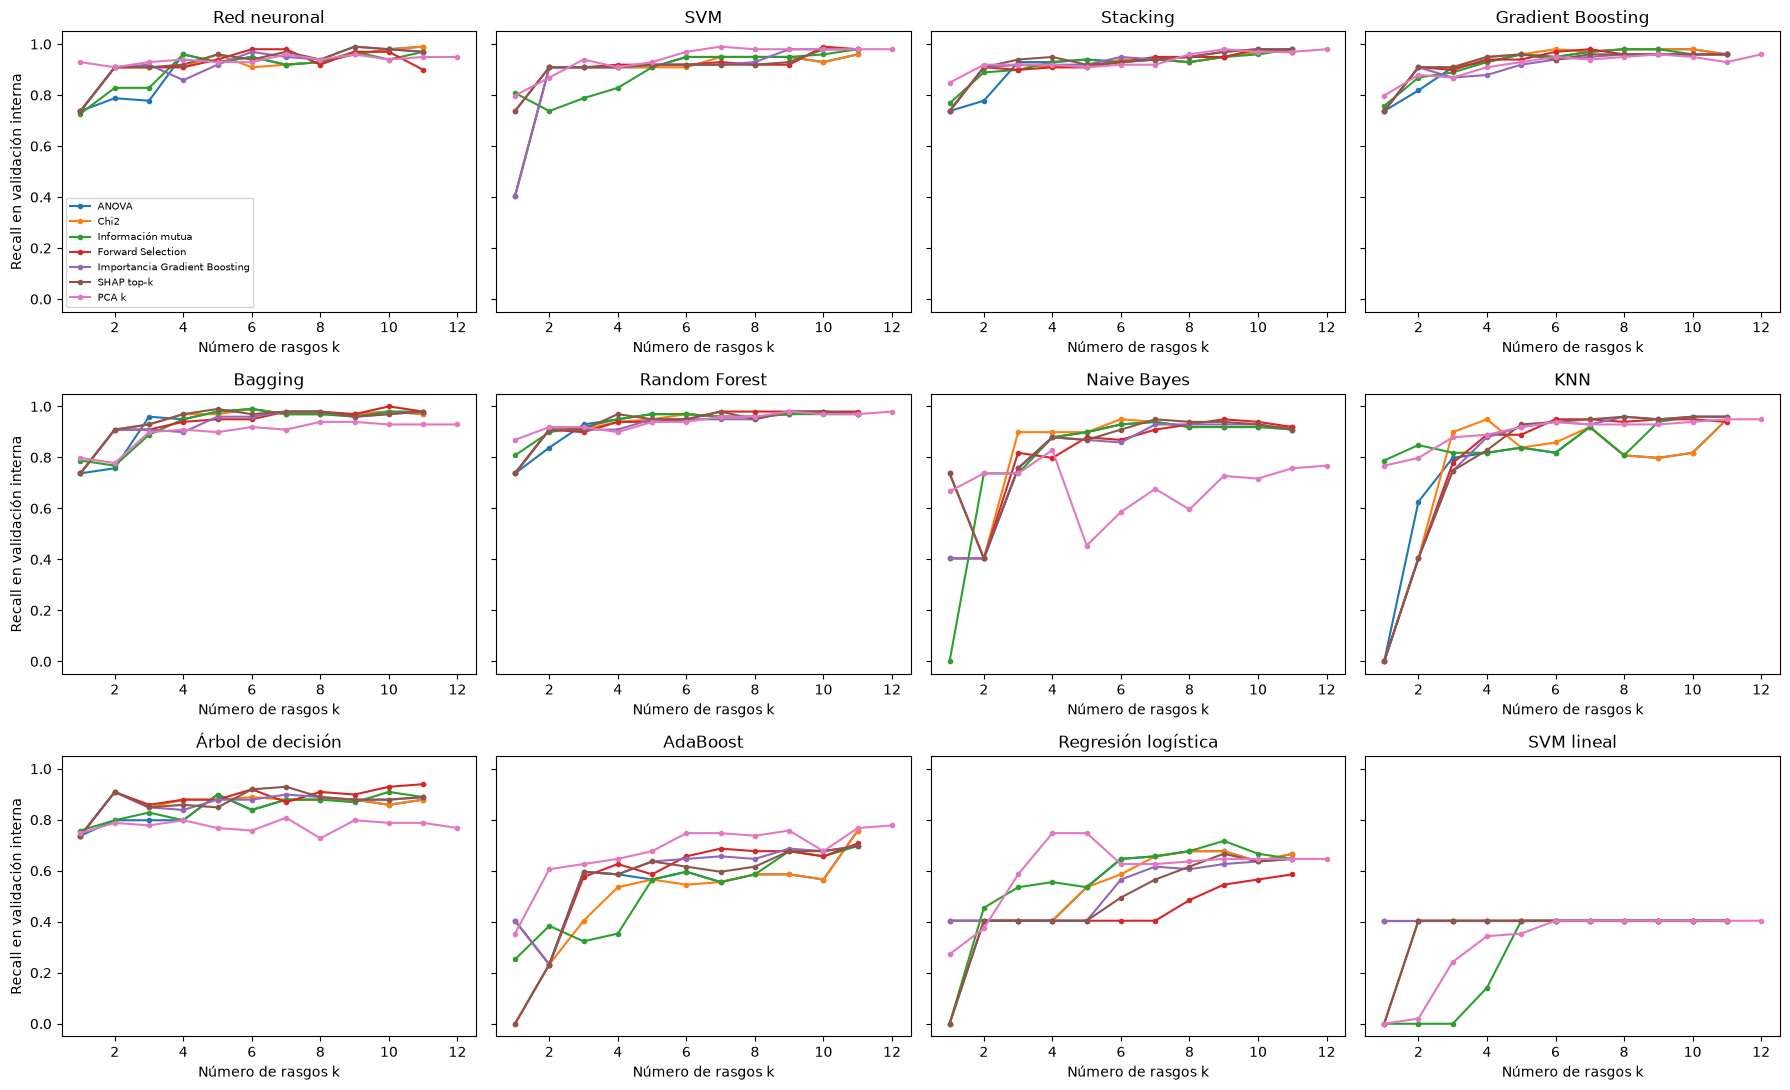

In [66]:
curvas = pd.DataFrame(filas_curvas)
metodos_con_curva = list(curvas["Método"].unique())

figura, ejes = plt.subplots(3, 4, figsize=(18, 11), sharey=True)
ejes = ejes.flatten()

for posicion in range(len(orden_modelos)):
    nombre_modelo = orden_modelos[posicion]
    for metodo in metodos_con_curva:
        punto = curvas[(curvas["Modelo"] == nombre_modelo) & (curvas["Método"] == metodo)]
        ejes[posicion].plot(punto["k"], punto["Recall"], marker="o", markersize=3, label=metodo)
    ejes[posicion].set_title(nombre_modelo)
    ejes[posicion].set_xlabel("Número de rasgos k")

ejes[0].set_ylabel("Recall en validación interna")
ejes[4].set_ylabel("Recall en validación interna")
ejes[8].set_ylabel("Recall en validación interna")
ejes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

Desde unos cinco o seis variables la curva de la mayoría de los modelos se aplana cerca de su nivel con todas las variables.

Por último, cuántos de los doce modelos conservan cada variable con cada método. Un método de lista fija elige lo mismo para todos los modelos, así que su columna vale 0 o 12; los de k variable cambian de un modelo a otro. Los métodos de PCA y el de todos los rasgos no se cuentan.

In [67]:
metodos_con_rasgos = []
for metodo in metodos:
    if metodo != "Todos los rasgos" and not metodo.startswith("PCA"):
        metodos_con_rasgos.append(metodo)

votos = pd.DataFrame(0, index=columnas, columns=metodos_con_rasgos)

for fila in matriz.to_dict("records"):
    if fila["Método"] in metodos_con_rasgos:
        for rasgo in json.loads(fila["Rasgos"]):
            votos.loc[rasgo, fila["Método"]] += 1

votos["Total"] = votos.sum(axis=1)
votos = votos.sort_values("Total", ascending=False)
votos

,ANOVA,Chi2,Información mutua,Varianza,Forward Selection,RFECV,L1,Importancia Gradient Boosting,SHAP top-k,SHAP 95 %,Correlación entre rasgos,Total
quejas,12,12,12,12,12,12,12,12,12,12,12,132
estado,11,11,12,12,12,12,12,11,12,12,12,129
frecuencia_uso,11,10,12,12,9,12,12,10,10,12,12,122
antiguedad,10,9,9,12,10,12,12,10,10,12,12,118
numeros_distintos,11,10,11,12,0,12,12,9,9,12,12,110
valor_cliente,11,10,12,12,8,12,0,9,10,12,12,108
frecuencia_sms,11,10,11,12,8,12,12,9,9,12,0,106
segundos_uso,11,10,12,12,10,12,0,10,10,12,0,99
nivel_cargo,11,10,11,12,5,12,12,5,4,0,12,94
grupo_edad,7,6,10,12,8,0,12,9,8,0,12,84


quejas queda en las 132 selecciones posibles (doce modelos por once métodos) y estado en 129; las que menos aparecen son plan_tarifario (73), fallas_llamadas (81) y grupo_edad (84). El ranking de SHAP de 10.6 coincide: estado y quejas encabezan.

### 10.11. El mejor de todos

De la matriz elegimos una combinación y probamos todo con ella: reajustamos sus hiperparámetros, la explicamos con SHAP, la medimos con validación anidada y calibramos su umbral en la sección siguiente. Todo con datos de entrenamiento.

Tomamos la combinación de mayor Recall con precisión sobre el piso. Las de PCA no compiten: sus componentes no son variables que se puedan explicar al equipo de retención. Si hay un empate exacto de Recall, gana la de mayor precisión. La tabla muestra también las combinaciones que quedan a menos de un error estándar del mejor (la desviación entre la raíz de diez), para ver cuánto depende la decisión de diferencias pequeñas.

In [68]:
def elegir_ganador(tabla):
    """Elige la combinación de mayor Recall sin PCA y con precisión sobre el piso; en un empate, la de mayor precisión."""
    candidatas = tabla[(tabla["Precisión"] >= PISO_PRECISION) & (~tabla["Método"].str.startswith("PCA"))]
    mejor_recall = candidatas["Recall"].max()
    empatadas = candidatas[(candidatas["Recall"] - mejor_recall).abs() < 1e-9]
    return empatadas.sort_values(["Precisión", "Número de rasgos"], ascending=[False, True]).iloc[0]


ganador = elegir_ganador(matriz)
modelo_ganador = ganador["Modelo"]
metodo_ganador = ganador["Método"]
k_ganador = None
if not pd.isna(ganador["k"]):
    k_ganador = int(ganador["k"])

error_estandar = ganador["Desviación Recall"] / 10 ** 0.5
cercanas = matriz[
    (matriz["Precisión"] >= PISO_PRECISION)
    & (~matriz["Método"].str.startswith("PCA"))
    & (matriz["Recall"] >= ganador["Recall"] - error_estandar)
].sort_values(["Recall", "Precisión"], ascending=False).reset_index(drop=True)

print("Ganador:", modelo_ganador, "con", metodo_ganador, "| Recall", round(ganador["Recall"], 4),
      "| precisión", round(ganador["Precisión"], 4), "| rasgos", int(ganador["Número de rasgos"]))
print("Error estándar del ganador:", round(error_estandar, 4))
print("Combinaciones sin PCA dentro de un error estándar:", len(cercanas))

tabla_cercanas = cercanas[["Modelo", "Método", "Número de rasgos", "Recall", "Desviación Recall", "Precisión", "F1"]].head(12).copy()
for columna in ["Recall", "Desviación Recall", "Precisión", "F1"]:
    tabla_cercanas[columna] = tabla_cercanas[columna].round(4)
tabla_cercanas

Ganador: Red neuronal con Todos los rasgos | Recall 0.9597 | precisión 0.6762 | rasgos 12
Error estándar del ganador: 0.0094
Combinaciones sin PCA dentro de un error estándar: 23


,Modelo,Método,Número de rasgos,Recall,Desviación Recall,Precisión,F1
0,Red neuronal,Todos los rasgos,12,0.9597,0.0297,0.6762,0.7931
1,Red neuronal,Varianza,12,0.9597,0.0297,0.6762,0.7931
2,SVM,Importancia Gradient Boosting,11,0.9597,0.0395,0.6731,0.7905
3,SVM,L1,10,0.9571,0.0375,0.6390,0.7659
4,SVM,SHAP top-k,11,0.9571,0.0374,0.6726,0.7893
5,SVM,Información mutua,11,0.9547,0.0369,0.6118,0.7443
6,SVM,Todos los rasgos,12,0.9546,0.0387,0.6707,0.7872
7,SVM,Varianza,12,0.9546,0.0387,0.6707,0.7872
8,SVM,Correlación entre rasgos,10,0.9546,0.0406,0.6356,0.7621
9,Stacking,Todos los rasgos,12,0.9546,0.0309,0.6759,0.7905


Elegimos la red neuronal de dos capas (32 y 16 neuronas) con todos los rasgos, escalador de rango 0 a 1 y submuestreo aleatorio: Recall de 0,9597 y precisión de 0,6762 en la matriz. Hay 23 combinaciones sin PCA a menos de un error estándar (0,0094) del mejor, y la SVM con la importancia de Gradient Boosting empata en Recall con 11 variables (precisión de 0,6731). La diferencia entre ellas es menor que la desviación entre particiones, así que la elección entre las empatadas no es firme; nos quedamos con la red neuronal porque alcanza el mismo Recall con la precisión más alta y devuelve probabilidades.

### 10.12. Reajuste de los hiperparámetros del ganador

Con la selección ya fija volvemos a buscar el modelo en el mismo espacio de la sección 9, con otra semilla (43) para que el sorteo de combinaciones no repita el anterior. Conservamos la configuración reajustada solo si mejora el Recall con la precisión sobre el piso; si no, queda la de la matriz. Como la elección vuelve a hacerse con las mismas diez particiones, la cifra del reajuste es optimista; la validación anidada la corrige.

In [69]:
espacio_ganador = None
n_iter_ganador = 60

for nombre_busqueda, espacio, n_iter in busquedas:
    if nombre_busqueda == modelo_ganador:
        espacio_ganador = agregar_preprocesado(dict(espacio))
        n_iter_ganador = n_iter

busqueda_ganador = RandomizedSearchCV(
    pipeline_con_seleccion(modelo_ganador, metodo_ganador, k_ganador), espacio_ganador,
    n_iter=n_iter_ganador, cv=particiones, scoring=metricas, refit=elegir_por_recall,
    n_jobs=-1, random_state=43, error_score=0.0
)
busqueda_ganador.fit(X_train, y_train)

resultados_ganador = busqueda_ganador.cv_results_
mejor_indice = busqueda_ganador.best_index_

recalls_reajuste = []
for numero in range(10):
    recalls_reajuste.append(resultados_ganador["split" + str(numero) + "_test_recall"][mejor_indice])

recall_reajuste = resultados_ganador["mean_test_recall"][mejor_indice]
precision_reajuste = resultados_ganador["mean_test_precision"][mejor_indice]
f1_reajuste = resultados_ganador["mean_test_f1"][mejor_indice]
desviacion_reajuste = pd.Series(recalls_reajuste).std()

if precision_reajuste >= PISO_PRECISION and recall_reajuste > ganador["Recall"]:
    pipeline_final = clone(busqueda_ganador.best_estimator_)
    decision_reajuste = "Se conserva la configuración reajustada"
else:
    pipeline_final = pipeline_con_seleccion(modelo_ganador, metodo_ganador, k_ganador)
    decision_reajuste = "Se conserva la configuración de la matriz"

pd.DataFrame([
    {"Configuración": "Matriz de la sección 6", "Recall": round(ganador["Recall"], 4),
     "Desviación Recall": round(ganador["Desviación Recall"], 4),
     "Precisión": round(ganador["Precisión"], 4), "F1": round(ganador["F1"], 4)},
    {"Configuración": "Reajuste de la sección 7.2", "Recall": round(recall_reajuste, 4),
     "Desviación Recall": round(desviacion_reajuste, 4),
     "Precisión": round(precision_reajuste, 4), "F1": round(f1_reajuste, 4)}
])

,Configuración,Recall,Desviación Recall,Precisión,F1
0,Matriz de la sección 6,0.9597,0.0297,0.6762,0.7931
1,Reajuste de la sección 7.2,0.9572,0.0267,0.6085,0.7431


In [70]:
print(decision_reajuste)

rows = []
for clave, valor in busqueda_ganador.best_params_.items():
    if clave in ["escalador", "balanceo"]:
        valor = nombre_de(valor)
    rows.append({"Parámetro": clave, "Valor reajustado": str(valor)})

pd.DataFrame(rows)

Se conserva la configuración de la matriz


,Parámetro,Valor reajustado
0,balanceo,RandomUnderSampler
1,escalador,MinMaxScaler
2,modelo__activation,relu
3,modelo__alpha,0.0008331134647297038
4,modelo__hidden_layer_sizes,"(128, 64)"
5,modelo__learning_rate_init,0.0004917780460421115
6,modelo__max_iter,300


El reajuste no mejoró: Recall de 0,9572 con precisión de 0,6085, apenas sobre el piso, así que conservamos la configuración de la matriz.

### 10.13. SHAP del ganador

Ajustamos el Pipeline elegido con todo el entrenamiento y explicamos las variables que llegan al modelo. Si el modelo es de árboles usamos TreeExplainer; si no, una explicación sobre su probabilidad con una muestra de fondo de 50 clientes, que es más lenta. La explicación se calcula sobre 200 clientes de entrenamiento.

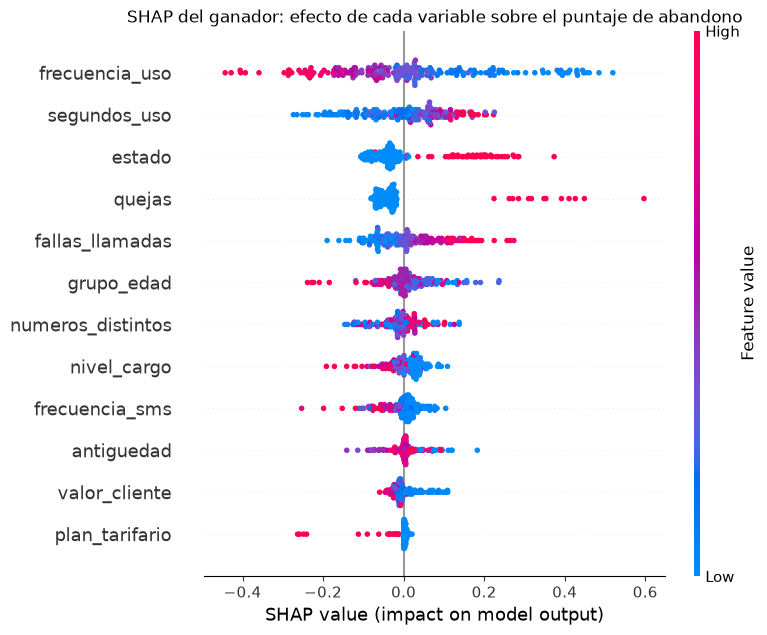

,Variable,Importancia media,Acumulada
0,frecuencia_uso,0.1521,0.2374
1,segundos_uso,0.0864,0.3724
2,estado,0.0777,0.4936
3,quejas,0.0647,0.5946
4,fallas_llamadas,0.0633,0.6934
5,grupo_edad,0.0448,0.7633
6,numeros_distintos,0.0343,0.8169
7,nivel_cargo,0.0318,0.8665
8,frecuencia_sms,0.0306,0.9142
9,antiguedad,0.0223,0.9490


In [71]:
def puntajes_de(modelo, datos):
    """Devuelve la probabilidad de abandono, o el puntaje de decisión si el modelo no calcula probabilidades."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(datos)[:, 1]
    return modelo.decision_function(datos)


def nombres_tras_seleccion(pipeline):
    """Devuelve los nombres de las variables que salen del paso de selección de un Pipeline ajustado."""
    seleccion = pipeline.named_steps["seleccion"]
    nombres = []
    if isinstance(seleccion, str):
        return columnas
    if isinstance(seleccion, ColumnTransformer):
        for posicion in seleccion.transformers_[0][2]:
            nombres.append(columnas[posicion])
        return nombres
    if isinstance(seleccion, PCA):
        for numero in range(seleccion.n_components_):
            nombres.append("PC" + str(numero + 1))
        return nombres
    for posicion in posiciones_de(seleccion.get_support()):
        nombres.append(columnas[posicion])
    return nombres


modelo_explicado = clone(pipeline_final)
modelo_explicado.fit(X_train, y_train)

nombres_ganador = nombres_tras_seleccion(modelo_explicado)
X_ganador = pd.DataFrame(modelo_explicado[:-1].transform(X_train), columns=nombres_ganador)
modelo_interno = modelo_explicado.named_steps["modelo"]


def puntaje_modelo_interno(datos):
    """Puntaje del modelo del ganador sobre datos ya escalados y seleccionados."""
    return puntajes_de(modelo_interno, np.asarray(datos))


muestra_shap = X_ganador.sample(200, random_state=42)

if type(modelo_interno).__name__ in ["RandomForestClassifier", "GradientBoostingClassifier", "DecisionTreeClassifier"]:
    valores_ganador = shap.TreeExplainer(modelo_interno).shap_values(muestra_shap)
    if isinstance(valores_ganador, list):
        valores_ganador = valores_ganador[1]
    if valores_ganador.ndim == 3:
        valores_ganador = valores_ganador[:, :, 1]
else:
    fondo_shap = X_ganador.sample(50, random_state=42)
    valores_ganador = shap.Explainer(puntaje_modelo_interno, fondo_shap, seed=42)(muestra_shap, silent=True).values

shap.summary_plot(valores_ganador, muestra_shap, show=False)
plt.title("SHAP del ganador: efecto de cada variable sobre el puntaje de abandono")
plt.show()

importancia_ganador = pd.Series(np.abs(valores_ganador).mean(axis=0), index=nombres_ganador).sort_values(ascending=False)
pd.DataFrame({
    "Variable": importancia_ganador.index,
    "Importancia media": importancia_ganador.values.round(4),
    "Acumulada": (importancia_ganador / importancia_ganador.sum()).cumsum().values.round(4)
})

frecuencia_uso lidera con 0,1521, que es el 23,7 % de la importancia, seguida de segundos_uso (0,0864), estado (0,0777) y quejas (0,0647); las cuatro reúnen el 59,5 % del total. En el gráfico empujan hacia el abandono una frecuencia de uso baja, un estado alto (cliente no activo), tener quejas y más fallas de llamadas.

El orden es distinto del que dio Gradient Boosting en 10.6, con estado y quejas primero, porque la importancia depende del modelo. Además frecuencia_uso y segundos_uso se correlacionan en 0,946 y aparecen con efectos opuestos: más segundos empuja hacia el abandono y más frecuencia lo aleja. Por eso no conviene leer cada una por separado.

### 10.14. Validación anidada

Es la cifra que sí se puede creer. En cada una de las diez particiones externas buscamos el mejor modelo con cinco particiones internas (escalador, balanceo e hiperparámetros incluidos) y lo medimos en la parte externa, que la búsqueda nunca vio. Cada búsqueda interna prueba la mitad de las combinaciones de la sección 9. La selección de variables queda fija: el método y el número de variables se eligieron en la matriz con todo el entrenamiento, así que lo único que esta validación no corrige es esa decisión.

In [72]:
n_iter_interno = max(10, n_iter_ganador // 2)

busqueda_interna = RandomizedSearchCV(
    clone(pipeline_final), espacio_ganador, n_iter=n_iter_interno, cv=particiones_internas,
    scoring=metricas, refit=elegir_por_recall, n_jobs=-1, random_state=42, error_score=0.0
)

inicio = time.time()
resultados_anidados = cross_validate(
    busqueda_interna, X_train, y_train, cv=particiones, scoring=metricas, error_score=0.0
)
duracion_anidada = time.time() - inicio

recall_anidado = resultados_anidados["test_recall"].mean()
desviacion_anidada = pd.Series(resultados_anidados["test_recall"]).std()
precision_anidada = resultados_anidados["test_precision"].mean()
f1_anidado = resultados_anidados["test_f1"].mean()

print("Validación anidada terminada en", round(duracion_anidada / 60, 1), "min")

tabla_anidada = pd.DataFrame([
    {"Medición": "Matriz de la sección 6", "Recall": ganador["Recall"],
     "Desviación Recall": ganador["Desviación Recall"], "Precisión": ganador["Precisión"], "F1": ganador["F1"]},
    {"Medición": "Reajuste de la sección 7.2", "Recall": recall_reajuste,
     "Desviación Recall": desviacion_reajuste, "Precisión": precision_reajuste, "F1": f1_reajuste},
    {"Medición": "Validación anidada", "Recall": recall_anidado,
     "Desviación Recall": desviacion_anidada, "Precisión": precision_anidada, "F1": f1_anidado}
])
for columna in ["Recall", "Desviación Recall", "Precisión", "F1"]:
    tabla_anidada[columna] = tabla_anidada[columna].round(4)
tabla_anidada

Validación anidada terminada en 28.1 min


,Medición,Recall,Desviación Recall,Precisión,F1
0,Matriz de la sección 6,0.9597,0.0297,0.6762,0.7931
1,Reajuste de la sección 7.2,0.9572,0.0267,0.6085,0.7431
2,Validación anidada,0.9546,0.0260,0.6684,0.7843


La validación anidada da un Recall de 0,9546 (desviación de 0,0260) con precisión de 0,6684, frente a 0,9597 y 0,6762 de la matriz: elegir con las mismas particiones infló el Recall en unos 0,005, poco.

### 10.15. PCA del ganador

Los clientes de entrenamiento llevados a las variables que ve el modelo, con su escalador, y proyectados en los dos primeros componentes principales.

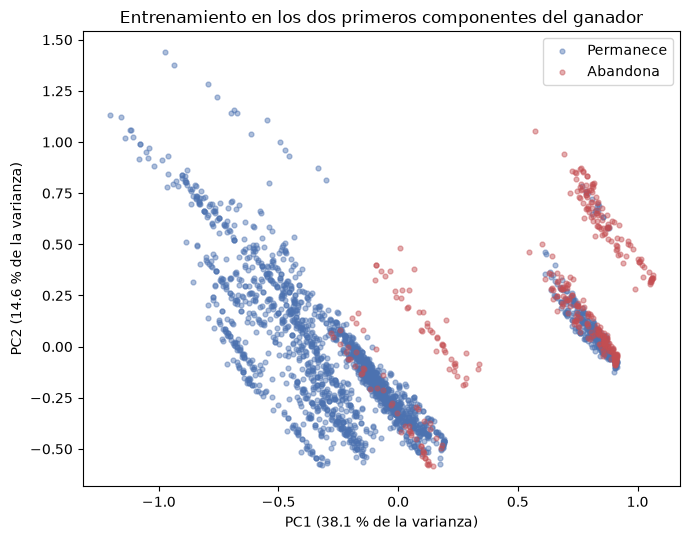

In [73]:
proyeccion_ganador = PCA(n_components=2, random_state=42)
puntos = proyeccion_ganador.fit_transform(X_ganador)

figura, eje = plt.subplots(figsize=(7, 5.5))
for clase, etiqueta, color in [(0, "Permanece", "#4C72B0"), (1, "Abandona", "#C44E52")]:
    seleccionados = (y_train == clase).values
    eje.scatter(puntos[seleccionados, 0], puntos[seleccionados, 1], c=color, alpha=0.45, s=12, label=etiqueta)
eje.set_xlabel("PC1 (" + str(round(proyeccion_ganador.explained_variance_ratio_[0] * 100, 1)) + " % de la varianza)")
eje.set_ylabel("PC2 (" + str(round(proyeccion_ganador.explained_variance_ratio_[1] * 100, 1)) + " % de la varianza)")
eje.set_title("Entrenamiento en los dos primeros componentes del ganador")
eje.legend()
plt.tight_layout()
plt.show()

[Volver al índice](#indice)

<a id="seccion-11"></a>
## 11. Selección del umbral

Elegimos el corte que da el mayor Recall con precisión sobre el piso, usando predicciones fuera de pliegue del entrenamiento. Las salidas del modelo sirven como puntuaciones para clasificar y priorizar clientes; no se interpretan como riesgos exactos. La prueba no interviene en esta decisión.

### 11.1. Probabilidades fuera de pliegue

Necesitamos probabilidades que el modelo haya dado sin haber visto al cliente. Las sacamos con las mismas diez particiones: cada cliente recibe la probabilidad que le asignó el modelo entrenado sin él. Si el modelo no calculara probabilidades usaríamos su puntaje de decisión.

In [74]:
from sklearn.model_selection import cross_val_predict

if hasattr(pipeline_final, "predict_proba"):
    puntajes_oof = cross_val_predict(pipeline_final, X_train, y_train, cv=particiones, method="predict_proba", n_jobs=-1)[:, 1]
else:
    puntajes_oof = cross_val_predict(pipeline_final, X_train, y_train, cv=particiones, method="decision_function", n_jobs=-1)

es_probabilidad = puntajes_oof.min() >= 0 and puntajes_oof.max() <= 1

if es_probabilidad:
    cortes = np.arange(0.05, 0.9501, 0.01)
    corte_predeterminado = 0.5
else:
    cortes = np.quantile(puntajes_oof, np.linspace(0.05, 0.95, 91))
    corte_predeterminado = 0.0

### 11.2. El umbral

Recorremos los cortes de 0,05 a 0,95 y miramos qué Recall, precisión y F1 da cada uno sobre las probabilidades fuera de pliegue. Elegimos el de mayor Recall con precisión sobre el piso; si varios cortes dan el mismo Recall, el más alto.

In [75]:
rows = []
for corte in cortes:
    alertas = (puntajes_oof >= corte).astype(int)
    rows.append({
        "Corte": corte,
        "Recall": recall_score(y_train, alertas, zero_division=0),
        "Precisión": precision_score(y_train, alertas, zero_division=0),
        "F1": f1_score(y_train, alertas, zero_division=0)
    })
barrido = pd.DataFrame(rows)

umbral_elegido = corte_predeterminado
mejor_recall_umbral = -1
for posicion in range(len(barrido) - 1, -1, -1):
    if barrido.loc[posicion, "Precisión"] >= PISO_PRECISION and barrido.loc[posicion, "Recall"] > mejor_recall_umbral:
        mejor_recall_umbral = barrido.loc[posicion, "Recall"]
        umbral_elegido = float(barrido.loc[posicion, "Corte"])

fila_umbral = barrido.iloc[(barrido["Corte"] - umbral_elegido).abs().argmin()]

La gráfica muestra cómo se reparte el resultado según el corte.

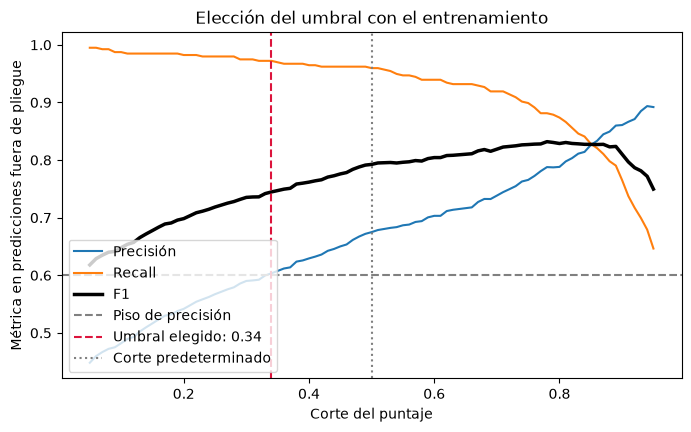

Umbral elegido: 0.34


,Corte,Recall,Precisión,F1
0,Elegido (0.34),0.9722,0.6034,0.7447
1,Predeterminado (0.5),0.9596,0.6750,0.7925


In [76]:
plt.figure(figsize=(8, 4.5))
plt.plot(barrido["Corte"], barrido["Precisión"], label="Precisión")
plt.plot(barrido["Corte"], barrido["Recall"], label="Recall")
plt.plot(barrido["Corte"], barrido["F1"], label="F1", linewidth=2.5, color="black")
plt.axhline(PISO_PRECISION, color="gray", linestyle="--", label="Piso de precisión")
plt.axvline(umbral_elegido, color="crimson", linestyle="--", label="Umbral elegido: " + str(round(umbral_elegido, 2)))
plt.axvline(corte_predeterminado, color="gray", linestyle=":", label="Corte predeterminado")
plt.xlabel("Corte del puntaje")
plt.ylabel("Métrica en predicciones fuera de pliegue")
plt.title("Elección del umbral con el entrenamiento")
plt.legend(loc="lower left")
plt.show()

print("Umbral elegido:", round(umbral_elegido, 4))
pd.DataFrame([
    {"Corte": "Elegido (" + str(round(umbral_elegido, 2)) + ")", "Recall": round(fila_umbral["Recall"], 4),
     "Precisión": round(fila_umbral["Precisión"], 4), "F1": round(fila_umbral["F1"], 4)},
    {"Corte": "Predeterminado (" + str(corte_predeterminado) + ")",
     "Recall": round(recall_score(y_train, (puntajes_oof >= corte_predeterminado).astype(int)), 4),
     "Precisión": round(precision_score(y_train, (puntajes_oof >= corte_predeterminado).astype(int), zero_division=0), 4),
     "F1": round(f1_score(y_train, (puntajes_oof >= corte_predeterminado).astype(int)), 4)}
])

### 11.3. Lo que queda decidido

El umbral elegido es 0,34. Con las predicciones fuera de pliegue da un Recall de 0,9722 y una precisión de 0,6034, justo sobre el piso. Con el corte de 0,5 serían 0,9596 y 0,6750: bajar el corte compra 1,3 puntos de Recall a cambio de 7,2 puntos de precisión. Este resultado se usa para seleccionar el corte, no como evaluación independiente.

[Volver al índice](#indice)

<a id="seccion-12"></a>
## 12. Evaluación final

Evaluamos el modelo y el umbral ya fijados con entrenamiento sobre los 630 clientes de prueba. Este conjunto ya se había consultado en el cuaderno original, así que la medición documenta el cambio de criterio y no constituye una prueba nueva intacta. No se usa para modificar el modelo ni el umbral.

### 12.1. El modelo final y su predicción

Ajustamos el Pipeline elegido con las 2.520 filas de entrenamiento, calculamos el puntaje de abandono de cada cliente de prueba y aplicamos el umbral.

In [77]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import classification_report
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import PrecisionRecallDisplay

modelo_final = clone(pipeline_final)
modelo_final.fit(X_train, y_train)

puntajes_test = puntajes_de(modelo_final, X_test)
predicciones_test = (puntajes_test >= umbral_elegido).astype(int)

print("Clientes de prueba:", len(y_test))
print("Abandonos reales:", int(y_test.sum()))
print("Clientes alertados por el modelo:", int(predicciones_test.sum()))

Clientes de prueba: 630
Abandonos reales: 99
Clientes alertados por el modelo: 139


### 12.2. Métricas

El Recall con precisión sobre el piso es lo que optimizamos. La segunda columna aplica el corte predeterminado en lugar del umbral elegido, solo para ver cuánto cambia.

In [78]:
def metricas_en_corte(y_real, puntajes, corte):
    """Calcula las métricas de decisión con un corte y las de ranking sin corte."""
    alertas = (puntajes >= corte).astype(int)
    return {
        "Recall": recall_score(y_real, alertas, zero_division=0),
        "Precisión": precision_score(y_real, alertas, zero_division=0),
        "F1": f1_score(y_real, alertas, zero_division=0),
        "Exactitud": accuracy_score(y_real, alertas),
        "ROC AUC": roc_auc_score(y_real, puntajes),
        "Precisión promedio": average_precision_score(y_real, puntajes)
    }


con_umbral = metricas_en_corte(y_test, puntajes_test, umbral_elegido)
con_predeterminado = metricas_en_corte(y_test, puntajes_test, corte_predeterminado)

rows = []
for nombre_metrica in con_umbral:
    rows.append({
        "Métrica": nombre_metrica,
        "Umbral elegido": round(con_umbral[nombre_metrica], 4),
        "Corte predeterminado": round(con_predeterminado[nombre_metrica], 4)
    })

tabla_test = pd.DataFrame(rows)
tabla_test

,Métrica,Umbral elegido,Corte predeterminado
0,Recall,0.9596,0.9394
1,Precisión,0.6835,0.7440
2,F1,0.7983,0.8304
3,Exactitud,0.9238,0.9397
4,ROC AUC,0.9801,0.9801
5,Precisión promedio,0.9091,0.9091


Y el reporte por clase.

In [79]:
reporte = pd.DataFrame(classification_report(
    y_test, predicciones_test, target_names=["Permanece", "Abandona"], digits=4, output_dict=True
)).T.round(4)
reporte

,precision,recall,f1-score,support
Permanece,0.9919,0.9171,0.9530,531.0000
Abandona,0.6835,0.9596,0.7983,99.0000
accuracy,0.9238,0.9238,0.9238,0.9238
macro avg,0.8377,0.9384,0.8757,630.0000
weighted avg,0.9434,0.9238,0.9287,630.0000


Con el umbral de 0,34 el modelo tiene un Recall de 0,9596, una precisión de 0,6835, un F1 de 0,7983 y una exactitud de 0,9238, con un ROC AUC de 0,9801. Con el corte de 0,5 el Recall baja a 0,9394 y la precisión sube a 0,7440. El Recall de prueba coincide con el de la validación anidada (0,9546, desviación de 0,0260) y la precisión (0,6835) con la anidada (0,6684), así que no hay señal de que la elección se ajustara a la prueba.

### 12.3. Matriz de confusión

Los cuatro casos posibles, en conteos y normalizada por fila: la segunda muestra, para cada clase real, qué proporción cae en cada predicción.

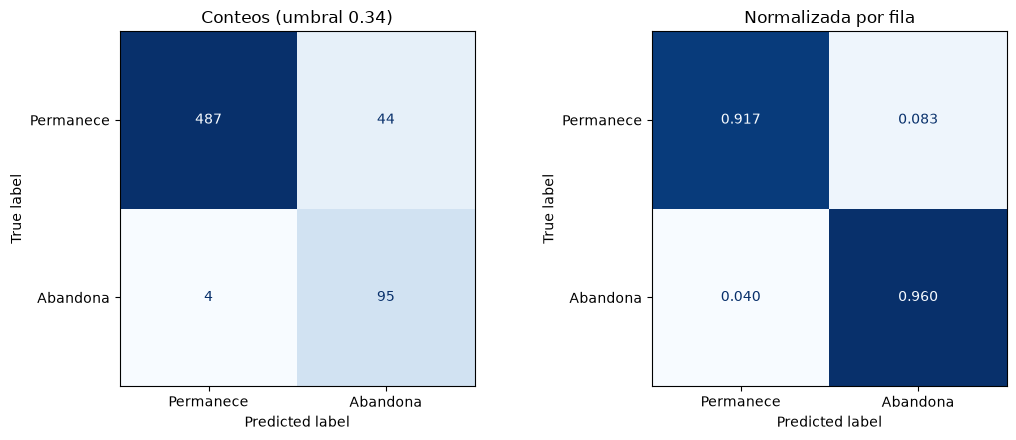

Abandonos detectados: 95 de 99
Abandonos no detectados: 4
Falsas alarmas: 44 de 531 clientes que permanecen


In [80]:
figura, ejes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, predicciones_test, display_labels=["Permanece", "Abandona"],
    cmap="Blues", colorbar=False, ax=ejes[0]
)
ejes[0].set_title("Conteos (umbral " + str(round(umbral_elegido, 2)) + ")")

ConfusionMatrixDisplay.from_predictions(
    y_test, predicciones_test, display_labels=["Permanece", "Abandona"],
    normalize="true", values_format=".3f", cmap="Blues", colorbar=False, ax=ejes[1]
)
ejes[1].set_title("Normalizada por fila")

plt.tight_layout()
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, predicciones_test).ravel()
print("Abandonos detectados:", int(vp), "de", int(vp + fn))
print("Abandonos no detectados:", int(fn))
print("Falsas alarmas:", int(fp), "de", int(vn + fp), "clientes que permanecen")

Se detectan 95 de los 99 abandonos y quedan 4 sin detectar. Hay 44 falsas alarmas entre los 531 clientes que permanecen: 139 alertas en total.

### 12.4. Curvas ROC y Precision-Recall

La línea de azar de la curva Precision-Recall es la proporción de abandonos de la prueba, no 0,5; por eso es más informativa que la ROC con clases desbalanceadas. En la gráfica de la derecha marcamos también el piso de precisión.

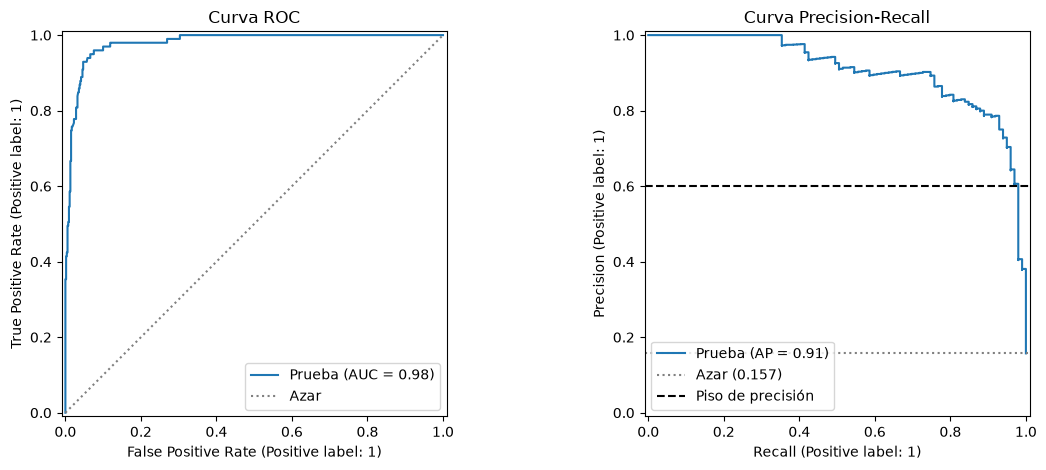

In [81]:
figura, ejes = plt.subplots(1, 2, figsize=(12, 4.8))

RocCurveDisplay.from_predictions(y_test, puntajes_test, name="Prueba", ax=ejes[0])
ejes[0].plot([0, 1], [0, 1], linestyle=":", color="gray", label="Azar")
ejes[0].set_title("Curva ROC")
ejes[0].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(y_test, puntajes_test, name="Prueba", ax=ejes[1])
ejes[1].axhline(y_test.mean(), linestyle=":", color="gray", label="Azar (" + str(round(y_test.mean(), 3)) + ")")
ejes[1].axhline(PISO_PRECISION, linestyle="--", color="black", label="Piso de precisión")
ejes[1].set_title("Curva Precision-Recall")
ejes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

### 12.5. La lista de prioridad

Así se usaría en la práctica: ordenamos a los clientes de prueba por puntaje y miramos cuántos de los que de verdad abandonaron caen en los primeros puestos. Es la pregunta que le importa al equipo de retención, que solo puede llamar a unos cuantos.

In [82]:
priorizacion = pd.DataFrame({
    "puntaje": puntajes_test,
    "abandono_real": y_test.to_numpy()
}).sort_values("puntaje", ascending=False).reset_index(drop=True)

rows = []
tasa_base = y_test.mean()

for fraccion in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    cantidad = int(round(len(priorizacion) * fraccion))
    primeros = priorizacion.head(cantidad)
    aciertos = primeros["abandono_real"].mean()
    rows.append({
        "Fraccion_contactada": fraccion,
        "Clientes": cantidad,
        "Abandonos dentro": int(primeros["abandono_real"].sum()),
        "Precision": round(aciertos, 4),
        "Recall": round(primeros["abandono_real"].sum() / y_test.sum(), 4),
        "Lift": round(aciertos / tasa_base, 2)
    })

tabla_priorizacion = pd.DataFrame(rows)
tabla_priorizacion

,Fraccion_contactada,Clientes,Abandonos dentro,Precision,Recall,Lift
0,0.05,32,32,1.0000,0.3232,6.36
1,0.10,63,57,0.9048,0.5758,5.76
2,0.15,94,79,0.8404,0.7980,5.35
3,0.20,126,93,0.7381,0.9394,4.70
4,0.25,158,96,0.6076,0.9697,3.87
5,0.30,189,97,0.5132,0.9798,3.27


Contactando al 5 % de los clientes (32) los 32 son abandonos; con el 20 % (126) se alcanza el 93,9 % de los abandonos, y con el 25 % (158) el 97,0 % con precisión de 0,6076.

### 12.6. Comparación con el cuaderno original

El cuaderno original optimiza el F1 y eligió Random Forest con umbral de 0,5. Sus cifras de prueba salen de la salida ejecutada de su sección 11. Se comparan sobre los mismos 630 clientes.

In [83]:
tabla_comparacion = pd.DataFrame([
    {
        "Cuaderno": "Original (optimiza F1), Random Forest",
        "Recall": 0.9495, "Precisión": 0.8624, "F1": 0.9038,
        "Abandonos detectados": 94, "Falsas alarmas": 15, "Clientes alertados": 109
    },
    {
        "Cuaderno": "Este cuaderno (optimiza Recall), " + modelo_ganador + " con " + metodo_ganador,
        "Recall": round(con_umbral["Recall"], 4), "Precisión": round(con_umbral["Precisión"], 4),
        "F1": round(con_umbral["F1"], 4), "Abandonos detectados": int(vp),
        "Falsas alarmas": int(fp), "Clientes alertados": int(predicciones_test.sum())
    }
])
tabla_comparacion

,Cuaderno,Recall,Precisión,F1,Abandonos detectados,Falsas alarmas,Clientes alertados
0,"Original (optimiza F1), Random Forest",0.9495,0.8624,0.9038,94,15,109
1,"Este cuaderno (optimiza Recall), Red neuronal con Todos los rasgos",0.9596,0.6835,0.7983,95,44,139


Este modelo detecta 95 abandonos y el del cuaderno original 94, pero con 44 falsas alarmas contra 15, casi el triple. Con 99 abandonos en la prueba, un cliente más o menos es un punto de Recall, así que la ganancia en detectados está dentro del ruido; el costo en falsas alarmas no. El original queda mejor en precisión (0,8624 contra 0,6835) y en F1 (0,9038 contra 0,7983).

[Volver al índice](#indice)

<a id="seccion-13"></a>
## 13. Despliegue y conclusiones

Guardamos el modelo para poder usarlo sin volver a entrenarlo, comprobamos que al recargarlo predice exactamente lo mismo, dejamos una función para usarlo con clientes nuevos y definimos qué vigilar una vez que esté en uso. No tocamos modelo_final.joblib, que usa la aplicación del cuaderno original.

### 13.1. Qué variables pesan

El ranking de SHAP del modelo elegido dice cuánto se apoyó en cada variable. No dice si empuja hacia el abandono o en contra, solo cuánto pesa, pero sirve para explicarle al equipo de retención en qué se está fijando el modelo.

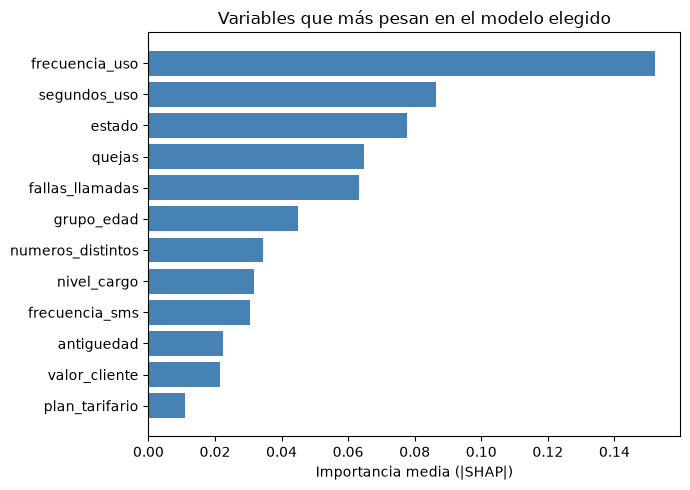

,Variable,Importancia
0,frecuencia_uso,0.1521
1,segundos_uso,0.0864
2,estado,0.0777
3,quejas,0.0647
4,fallas_llamadas,0.0633
5,grupo_edad,0.0448
6,numeros_distintos,0.0343
7,nivel_cargo,0.0318
8,frecuencia_sms,0.0306
9,antiguedad,0.0223


In [84]:
tabla_importancias = pd.DataFrame({
    "Variable": importancia_ganador.index,
    "Importancia": importancia_ganador.values.round(4)
})

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(tabla_importancias["Variable"][::-1], tabla_importancias["Importancia"][::-1], color="steelblue")
ax.set_xlabel("Importancia media (|SHAP|)")
ax.set_title("Variables que más pesan en el modelo elegido")
plt.tight_layout()
plt.show()

tabla_importancias

frecuencia_uso es la variable en la que más se apoya el modelo (0,1521), seguida de segundos_uso (0,0864), estado (0,0777) y quejas (0,0647). Las que menos pesan son valor_cliente (0,0215) y plan_tarifario (0,0111).

Hay una diferencia con lo que vimos en la exploración: quejas y estado eran las señales más fuertes por phik y por ANOVA, y aquí quedan en tercer y cuarto lugar. Las dos variables de uso se solapan (phik de 0,928 en 6.7) y entre las dos suman 0,2385, así que el modelo reparte entre ellas lo que antes se veía en una sola. Las quejas pesan menos en promedio porque solo 202 de los 2.520 clientes de entrenamiento tienen alguna, pero cuando aparecen su efecto es de los más grandes.

### 13.2. Referencia para el PSI

El PSI (índice de estabilidad de la población) compara la distribución de cada variable en un lote nuevo con la del entrenamiento. Para las variables de diez valores o menos comparamos la proporción de cada valor; para las demás, las proporciones en intervalos por deciles del entrenamiento. Los cortes se guardan con el modelo para poder calcularlo con lotes futuros.

In [85]:
def cortes_de_referencia(datos_referencia):
    """Guarda por variable los cortes y las proporciones del entrenamiento para calcular el PSI."""
    cortes_psi = {}
    for columna in datos_referencia.columns:
        serie = datos_referencia[columna]
        if serie.nunique() <= 10:
            valores = []
            proporciones = []
            for valor in sorted(serie.unique()):
                valores.append(float(valor))
                proporciones.append(float((serie == valor).mean()))
            cortes_psi[columna] = {"tipo": "categorias", "valores": valores, "proporciones": proporciones}
        else:
            bordes = np.unique(np.quantile(serie, np.linspace(0.1, 0.9, 9)))
            conteos = np.bincount(np.digitize(serie, bordes), minlength=len(bordes) + 1)
            cortes_psi[columna] = {
                "tipo": "deciles",
                "bordes": bordes.astype(float).tolist(),
                "proporciones": (conteos / len(serie)).tolist()
            }
    return cortes_psi


def calcular_psi(corte, nuevos):
    """Calcula el PSI de una variable de un lote nuevo contra su corte de referencia."""
    if corte["tipo"] == "categorias":
        proporciones_nuevas = []
        for valor in corte["valores"]:
            proporciones_nuevas.append((nuevos == valor).mean())
        proporciones_nuevas = np.array(proporciones_nuevas)
    else:
        conteos = np.bincount(np.digitize(nuevos, corte["bordes"]), minlength=len(corte["bordes"]) + 1)
        proporciones_nuevas = conteos / len(nuevos)
    referencia = np.clip(np.array(corte["proporciones"]), 1e-4, None)
    nuevas = np.clip(proporciones_nuevas, 1e-4, None)
    return float(np.sum((nuevas - referencia) * np.log(nuevas / referencia)))


cortes_psi = cortes_de_referencia(X_train)

rows = []
for columna in columnas:
    valor_psi = calcular_psi(cortes_psi[columna], X_test[columna])
    if valor_psi < 0.1:
        lectura = "estable"
    elif valor_psi < 0.25:
        lectura = "cambio moderado"
    else:
        lectura = "cambio significativo"
    rows.append({"Variable": columna, "PSI": round(valor_psi, 4), "Lectura": lectura})

tabla_psi = pd.DataFrame(rows).sort_values("PSI", ascending=False).reset_index(drop=True)
tabla_psi

,Variable,PSI,Lectura
0,frecuencia_uso,0.0248,estable
1,numeros_distintos,0.0229,estable
2,segundos_uso,0.0226,estable
3,valor_cliente,0.0186,estable
4,frecuencia_sms,0.0163,estable
5,fallas_llamadas,0.0124,estable
6,antiguedad,0.0120,estable
7,nivel_cargo,0.0078,estable
8,quejas,0.0051,estable
9,grupo_edad,0.0018,estable


La prueba sale de la misma partición aleatoria que el entrenamiento, así que esperamos un PSI bajo en todas las variables. El mayor es el de frecuencia_uso, con 0,0248, y las doce quedan estables. Aquí no es una señal de que el modelo funcione, sino la comprobación de que el cálculo está bien y la referencia lista para lotes futuros de clientes reales.

### 13.3. Guardar el modelo

Guardamos en un solo archivo el Pipeline ya entrenado, el umbral y los nombres de las columnas en el orden en que las espera, con el mismo formato del cuaderno original. Aparte va un archivo de metadatos con las decisiones, las cifras de validación y de prueba, las versiones de las librerías y los cortes del PSI, para que quien use el modelo sepa de dónde salió. También guardamos la tabla de priorización.

In [86]:
import joblib
import datetime
import platform
import sklearn
import imblearn

RUTA_MODELOS = RUTA_BASE + "models/"


def a_json(valor):
    """Convierte un valor de scikit-learn en algo que se pueda guardar en JSON."""
    if hasattr(valor, "item"):
        return valor.item()
    if isinstance(valor, tuple):
        return list(valor)
    if valor is None or isinstance(valor, (int, float, str, bool)):
        return valor
    return str(valor)


hiperparametros_finales = {}
for clave, valor in modelo_final.named_steps["modelo"].get_params(deep=False).items():
    hiperparametros_finales[clave] = a_json(valor)

artefacto = {
    "modelo": modelo_final,
    "umbral": float(umbral_elegido),
    "columnas_entrada": list(X_train.columns)
}
joblib.dump(artefacto, RUTA_MODELOS + "modelo_recall.joblib")

metricas_prueba = {}
for nombre_metrica in con_umbral:
    metricas_prueba[nombre_metrica] = float(con_umbral[nombre_metrica])

metadata = {
    "modelo": modelo_ganador,
    "seleccion_de_rasgos": metodo_ganador,
    "k_rasgos": k_ganador,
    "rasgos_que_ve_el_modelo": nombres_ganador,
    "escalador": nombre_de(modelo_final.named_steps["escalador"]),
    "balanceo": nombre_de(modelo_final.named_steps["balanceo"]),
    "hiperparametros": hiperparametros_finales,
    "umbral": float(umbral_elegido),
    "piso_precision": PISO_PRECISION,
    "columnas_entrada": list(X_train.columns),
    "validacion_cruzada_matriz": {
        "recall": float(ganador["Recall"]), "precision": float(ganador["Precisión"]), "f1": float(ganador["F1"])
    },
    "validacion_anidada": {
        "recall": float(recall_anidado), "desviacion_recall": float(desviacion_anidada),
        "precision": float(precision_anidada), "f1": float(f1_anidado)
    },
    "metricas_test": metricas_prueba,
    "procedimiento": ("Partición 80/20 estratificada; hiperparámetros, método de selección, ganador y umbral "
                      "decididos solo con entrenamiento; prueba ya consultada en el cuaderno original, "
                      "medida una sola vez aquí sin usarla para seleccionar."),
    "advertencia": ("La cifra de prueba proviene de 630 clientes con 99 abandonos y tiene incertidumbre "
                    "muestral; no constituye una prueba nueva intacta."),
    "psi_referencia": cortes_psi,
    "fecha_entrenamiento": datetime.datetime.now().isoformat(timespec="seconds"),
    "version_python": platform.python_version(),
    "version_sklearn": sklearn.__version__,
    "version_imblearn": imblearn.__version__,
    "version_pandas": pd.__version__,
    "version_numpy": np.__version__,
    "version_shap": shap.__version__
}

with open(RUTA_MODELOS + "metadata_recall.json", "w", encoding="utf-8") as archivo:
    json.dump(metadata, archivo, ensure_ascii=False, indent=2)

tabla_priorizacion.to_csv(RUTA_RESULTADOS + "priorizacion_recall.csv", index=False)

print("Guardados modelo_recall.joblib y metadata_recall.json en", RUTA_MODELOS)
print("Guardada priorizacion_recall.csv en", RUTA_RESULTADOS)

Guardados modelo_recall.joblib y metadata_recall.json en ./models/
Guardada priorizacion_recall.csv en ./resultados/


### 13.4. Comprobación de la recarga

Recargamos el archivo y predecimos la prueba de nuevo. Los puntajes y las alertas tienen que ser idénticos a los de la sección 12.

In [87]:
recargado = joblib.load(RUTA_MODELOS + "modelo_recall.joblib")

puntajes_recargados = puntajes_de(recargado["modelo"], X_test[recargado["columnas_entrada"]])
alertas_recargadas = (puntajes_recargados >= recargado["umbral"]).astype(int)

print("Puntajes idénticos:", bool(np.array_equal(puntajes_test, puntajes_recargados)))
print("Alertas idénticas:", bool(np.array_equal(predicciones_test, alertas_recargadas)))

Puntajes idénticos: True
Alertas idénticas: True


Los puntajes y las alertas son idénticos.

### 13.5. Función de predicción

Recibe una tabla de clientes con las columnas en español, comprueba que estén las doce entradas y que sean numéricas, y devuelve el puntaje de abandono y la alerta con el umbral guardado. Si falta algo, avisa con la lista de columnas. La probamos con cinco clientes de prueba, ya evaluados arriba, y con una tabla a la que le quitamos dos columnas.

In [88]:
def predecir_abandono(clientes, ruta_modelo):
    """Devuelve el puntaje de abandono y la alerta de cada cliente de la tabla recibida."""
    artefacto_guardado = joblib.load(ruta_modelo)
    esperadas = artefacto_guardado["columnas_entrada"]

    faltantes = []
    no_numericas = []
    for columna in esperadas:
        if columna not in clientes.columns:
            faltantes.append(columna)
        elif not pd.api.types.is_numeric_dtype(clientes[columna]):
            no_numericas.append(columna)

    if len(faltantes) > 0:
        raise ValueError("Faltan columnas: " + ", ".join(faltantes))
    if len(no_numericas) > 0:
        raise ValueError("Columnas no numéricas: " + ", ".join(no_numericas))

    puntajes = puntajes_de(artefacto_guardado["modelo"], clientes[esperadas])
    return pd.DataFrame({
        "puntaje_abandono": puntajes,
        "alerta": (puntajes >= artefacto_guardado["umbral"]).astype(int)
    }, index=clientes.index)


ejemplo = predecir_abandono(X_test.head(5), RUTA_MODELOS + "modelo_recall.joblib")
ejemplo["abandono_real"] = y_test.head(5).to_numpy()
ejemplo

,puntaje_abandono,alerta,abandono_real
0,7.931809e-02,0,0
1,5.291944e-05,0,0
2,2.426526e-05,0,0
3,1.609487e-06,0,0
4,1.159788e-11,0,0


In [89]:
try:
    predecir_abandono(X_test.head(5).drop(columns=["quejas", "estado"]), RUTA_MODELOS + "modelo_recall.joblib")
except ValueError as error:
    print("Error esperado:", error)

Error esperado: Faltan columnas: quejas, estado


### 13.6. Qué vigilar cuando el modelo esté en uso

Con el PSI y la tasa de alertas esperada armamos un plan corto de monitoreo. Las cifras de referencia salen de la prueba ejecutada arriba.

In [90]:
tasa_alertas_prueba = predicciones_test.mean()

tabla_monitoreo = pd.DataFrame([
    {
        "Qué se vigila": "Cambio en los datos (PSI por variable)",
        "Cómo": "Calcular el PSI de cada variable del lote nuevo con los cortes guardados en metadata_recall.json",
        "Cuándo actuar": "PSI mayor a 0,25 en una variable con peso alto en SHAP: revisar; en dos o más variables: reentrenar"
    },
    {
        "Qué se vigila": "Tasa de alertas",
        "Cómo": "Proporción de clientes alertados en cada lote (en la prueba fue " + str(round(tasa_alertas_prueba * 100, 1)) + " %)",
        "Cuándo actuar": "Desvío mayor a 5 puntos porcentuales sostenido en dos lotes seguidos"
    },
    {
        "Qué se vigila": "Recall real",
        "Cómo": "Cuando se conozcan los abandonos reales del lote, calcular el Recall y la precisión con el umbral guardado",
        "Cuándo actuar": "Recall menor a " + str(round((con_umbral["Recall"] - 0.05) * 100, 1)) + " % (cinco puntos bajo la prueba) o precisión menor a " + str(int(PISO_PRECISION * 100)) + " %"
    },
    {
        "Qué se vigila": "Columnas de entrada",
        "Cómo": "La función predecir_abandono revisa que estén las doce y sean numéricas",
        "Cuándo actuar": "Si falta alguna, bloquear la predicción y avisar"
    }
])
tabla_monitoreo

,Qué se vigila,Cómo,Cuándo actuar
0,Cambio en los datos (PSI por variable),Calcular el PSI de cada variable del lote nuevo con los cortes guardados en metadata_recall.json,"PSI mayor a 0,25 en una variable con peso alto en SHAP: revisar; en dos o más variables: reentrenar"
1,Tasa de alertas,Proporción de clientes alertados en cada lote (en la prueba fue 22.1 %),Desvío mayor a 5 puntos porcentuales sostenido en dos lotes seguidos
2,Recall real,"Cuando se conozcan los abandonos reales del lote, calcular el Recall y la precisión con el umbral guardado",Recall menor a 91.0 % (cinco puntos bajo la prueba) o precisión menor a 60 %
3,Columnas de entrada,La función predecir_abandono revisa que estén las doce y sean numéricas,"Si falta alguna, bloquear la predicción y avisar"


### 13.7. Resumen de cifras clave

Las cifras que citan las conclusiones, en un solo lugar.

In [91]:
rows = [
    {"Cifra": "Combinaciones que cumplen el piso", "Valor": str(len(matriz[matriz["Precisión"] >= PISO_PRECISION])) + " de " + str(len(matriz))},
    {"Cifra": "Ganador", "Valor": modelo_ganador + " con " + metodo_ganador + " (" + str(int(ganador["Número de rasgos"])) + " rasgos)"},
    {"Cifra": "Recall en la matriz", "Valor": round(ganador["Recall"], 4)},
    {"Cifra": "Precisión en la matriz", "Valor": round(ganador["Precisión"], 4)},
    {"Cifra": "Recall del reajuste", "Valor": round(recall_reajuste, 4)},
    {"Cifra": "Recall en validación anidada", "Valor": round(recall_anidado, 4)},
    {"Cifra": "Precisión en validación anidada", "Valor": round(precision_anidada, 4)},
    {"Cifra": "Umbral elegido", "Valor": round(umbral_elegido, 4)},
    {"Cifra": "Recall en prueba", "Valor": round(con_umbral["Recall"], 4)},
    {"Cifra": "Precisión en prueba", "Valor": round(con_umbral["Precisión"], 4)},
    {"Cifra": "F1 en prueba", "Valor": round(con_umbral["F1"], 4)},
    {"Cifra": "ROC AUC en prueba", "Valor": round(con_umbral["ROC AUC"], 4)},
    {"Cifra": "Abandonos detectados en prueba", "Valor": str(int(vp)) + " de " + str(int(vp + fn))},
    {"Cifra": "Falsas alarmas en prueba", "Valor": str(int(fp)) + " de " + str(int(vn + fp))},
    {"Cifra": "Clientes alertados en prueba", "Valor": int(predicciones_test.sum())},
    {"Cifra": "PSI mayor entre variables", "Valor": tabla_psi.loc[0, "Variable"] + " (" + str(tabla_psi.loc[0, "PSI"]) + ")"}
]

resumen_cifras = pd.DataFrame(rows)
resumen_cifras

,Cifra,Valor
0,Combinaciones que cumplen el piso,145 de 180
1,Ganador,Red neuronal con Todos los rasgos (12 rasgos)
2,Recall en la matriz,0.9597
3,Precisión en la matriz,0.6762
4,Recall del reajuste,0.9572
5,Recall en validación anidada,0.9546
6,Precisión en validación anidada,0.6684
7,Umbral elegido,0.34
8,Recall en prueba,0.9596
9,Precisión en prueba,0.6835


## Conclusiones

Ajustamos los hiperparámetros de doce modelos con una búsqueda aleatoria de 60 combinaciones por modelo (30 en el Stacking) y, con los doce ya ajustados, probamos quince formas de usar las variables: 180 combinaciones en total. Ajustar fue lo que más movió el Recall: seis modelos superan 0,95 con la precisión sobre el piso de 0,60, y la SVM pasó de 0,4147 a 0,9546 y la red neuronal de 0,6314 a 0,9597 respecto a sus valores por defecto.

La selección de variables, el PCA y SHAP no mejoraron el Recall. De las 180 combinaciones, 145 cumplen el piso, y en siete de los doce modelos la mejor es la de todos los rasgos. Las listas fijas son algo optimistas y aun así no superan a la columna de todos los rasgos. Elegimos la red neuronal con las doce variables; la SVM con la importancia de Gradient Boosting empata con ella en la matriz con una variable menos.

La cifra más honesta del modelo elegido es la de la validación anidada: Recall de 0,9546 con precisión de 0,6684. La prueba la confirma: con el umbral de 0,34 se detectan 95 de los 99 abandonos (Recall de 0,9596) con 44 falsas alarmas, precisión de 0,6835 y ROC AUC de 0,9801. Si se contacta al 20 % de los clientes se alcanza el 93,9 % de los abandonos.

El piso de precisión es lo que da sentido a la métrica: sin él, Naive Bayes tendría uno de los mejores Recall (0,9367) con precisión de 0,3728. Con él se ve el costo de buscar Recall. Frente al cuaderno original, que optimiza el F1, detectamos un abandono más (95 contra 94), pero con 44 falsas alarmas en lugar de 15. Con 99 abandonos en la prueba esa ganancia está dentro del ruido, y el original queda mejor en precisión y en F1; la elección entre los dos depende de cuánto cueste una llamada de más frente a un cliente que se va.

La evaluación reutiliza el conjunto de prueba ya consultado en el cuaderno original y tiene 99 abandonos, así que cada cliente pesa un punto de Recall. El método de selección y el número de variables se eligieron con todo el entrenamiento y la validación anidada no los corrige. El umbral de 0,34 deja la precisión del entrenamiento justo sobre el piso (0,6034) y en la prueba salió algo más alta. El archivo no trae fechas ni identificador de cliente, y estado puede reflejar una situación tardía para retenerlo.

El modelo se guarda en models/modelo_recall.joblib y se usa con predecir_abandono, que rechaza tablas con columnas faltantes; al recargarlo las predicciones son idénticas. El PSI de la prueba contra el entrenamiento es menor a 0,03 en todas las variables, como era de esperar al venir de la misma partición, y el plan de monitoreo deja definidos los avisos de cambio en los datos, en la tasa de alertas y en el Recall real.

[Volver al índice](#indice)